Notebook de análisis exploratorio para los precios scrapeados del SNIIM (salida del notebook de scraping: `precios_historicos_sniim_continuo.csv`).

Incluye:
1. Series de precios de granos/semillas y de frutas/hortalizas, **por separado**.
2. Visualización de datos faltantes.
3. Comparación y armonización por estado de origen, para productos con más de un estado consultado (hoy: Tomate Saladette).
4. Búsqueda de estacionalidad y tendencia por cultivo (descomposición STL).

**`serie_semanal` es la función central que usa todo el notebook** (series de precios, datos faltantes, estacionalidad). Para un producto con un solo estado de origen, promedia lo que haya por fecha y resamplea a semanal, igual que antes. Para un producto con más de un estado (Tomate Saladette: Sinaloa/Puebla), usa automáticamente la serie **armonizada** (sección 3b explica por qué: promediar los estados tal cual genera un salto artificial cada vez que uno entra o sale de temporada, porque es un cambio de composición, no un cambio real de precio).

**Configuración y utilidades**

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import STL

# --- Configuración ---
RUTA_CSV = 'precios_historicos_sniim_continuo.csv'  # el CSV que genera el notebook de scraping
COLUMNA_PRECIO = 'Precio Frec'  # también puedes usar 'Precio Mín' o 'Precio Max'
PERIODO_ESTACIONAL = 52  # semanas por año (todo se resamplea a semanal antes de analizarlo)

PRODUCTOS_GRANOS = [
    "Maíz blanco", "Maíz blanco pozolero", "Frijol Pinto", "Frijol Negro", "Haba",
]
PRODUCTOS_HORTALIZAS = [
    "Aguacate Hass - Primera", "Tomate Saladette - Primera",
]

In [40]:
import os

if not os.path.exists(RUTA_CSV):
    raise FileNotFoundError(
        f"No encontré '{RUTA_CSV}' en esta carpeta. Corre primero el notebook de scraping "
        "(o copia aquí el CSV que generó) antes de seguir."
    )

df = pd.read_csv(RUTA_CSV)
df['Fecha'] = pd.to_datetime(df['Fecha'], format='%d/%m/%Y', errors='coerce')

for col in ['Precio Mín', 'Precio Max', 'Precio Frec']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df_granos = df[df['Categoria'] == 'granos'].copy()
df_hortalizas = df[df['Categoria'] == 'hortalizas'].copy()

print(f"Filas granos: {len(df_granos)} | Filas hortalizas: {len(df_hortalizas)}")
print(f"Rango de fechas granos: {df_granos['Fecha'].min()} a {df_granos['Fecha'].max()}")
print(f"Rango de fechas hortalizas: {df_hortalizas['Fecha'].min()} a {df_hortalizas['Fecha'].max()}")

Filas granos: 2811 | Filas hortalizas: 8636
Rango de fechas granos: 2015-01-07 00:00:00 a 2025-12-31 00:00:00
Rango de fechas hortalizas: 2015-01-02 00:00:00 a 2025-12-31 00:00:00


**Funciones comunes** — incluye `serie_semanal`, que decide sola si debe usar la serie armonizada (ver sección 3) según cuántos estados de origen tenga el producto.

In [41]:
def serie_semanal_por_origen(df_fuente, producto):
    """Regresa un diccionario {estado: serie semanal}, sin promediar entre estados. Usa
    'Origen_Estado' (el estado realmente consultado), NO 'Origen' — esa columna no existe
    para hortalizas; lo que había ahí era la presentación (tamaño de caja)."""
    sub = df_fuente[df_fuente['Producto_Buscado'] == producto].dropna(subset=['Fecha', COLUMNA_PRECIO, 'Origen_Estado'])
    sub = sub[sub['Origen_Estado'] != '']
    series_por_origen = {}
    for origen, grupo in sub.groupby('Origen_Estado'):
        s = grupo.sort_values('Fecha').set_index('Fecha')[COLUMNA_PRECIO]
        s = s.groupby(level=0).mean()  # promedia entre presentaciones del mismo estado/fecha
        series_por_origen[origen] = s.resample('W').mean()
    return series_por_origen


def calcular_serie_armonizada(df_fuente, producto, verbose=False):
    """Combina las series por estado de origen en UNA serie continua, corrigiendo primero la
    diferencia de nivel entre estados (si no, promediar genera saltos artificiales cada vez
    que un estado entra o sale de temporada). Regresa None si el producto tiene 0 o 1 estados."""
    series_por_origen = serie_semanal_por_origen(df_fuente, producto)
    if len(series_por_origen) < 2:
        return None

    nombres = list(series_por_origen.keys())
    referencia = series_por_origen[nombres[0]]
    desfases = {nombres[0]: 0.0}

    for nombre in nombres[1:]:
        serie = series_por_origen[nombre]
        traslape = referencia.index.intersection(serie.index)
        traslape = traslape[referencia[traslape].notna() & serie[traslape].notna()]
        if len(traslape) < 8:
            print(f"[!] {producto}: solo {len(traslape)} semanas de traslape entre "
                  f"'{nombres[0]}' y '{nombre}' — el desfase estimado puede no ser confiable.")
        diferencia_semanal = serie[traslape] - referencia[traslape]
        desfases[nombre] = diferencia_semanal.mean()
        if verbose and len(traslape) >= 8:
            variabilidad = diferencia_semanal.std()
            print(f"{producto}: desfase '{nombre}' vs '{nombres[0]}' = {desfases[nombre]:.2f} "
                  f"(desviación estándar de la diferencia semanal: {variabilidad:.2f} — "
                  f"si es grande respecto al desfase, la brecha no es tan constante como asume este ajuste)")

    ajuste_centrado = sum(desfases.values()) / len(desfases)
    series_ajustadas = {
        nombre: series_por_origen[nombre] - desfases[nombre] + ajuste_centrado
        for nombre in nombres
    }
    combinada = pd.concat(series_ajustadas.values(), axis=1, sort=True).mean(axis=1)
    combinada.name = f'{producto} (armonizada)'
    return combinada


def serie_semanal(df_fuente, producto):
    """Serie semanal continua para un producto — la que usa el resto del notebook (datos
    faltantes, estacionalidad/tendencia, etc.). Si el producto tiene más de un estado de
    origen consultado, usa la serie ARMONIZADA (nivel ajustado entre estados antes de
    promediar) en vez de mezclarlos tal cual, lo que evita el salto artificial de composición
    que se documenta en la sección 3 (ver 'Comparación por estado de origen')."""
    if 'Origen_Estado' in df_fuente.columns:
        estados = df_fuente[df_fuente['Producto_Buscado'] == producto]['Origen_Estado'].dropna().unique()
        estados = [e for e in estados if e not in ('', 'Todos')]
        if len(estados) > 1:
            armonizada = calcular_serie_armonizada(df_fuente, producto)
            if armonizada is not None:
                return armonizada

    # Un solo origen (o "Todos" sin desglose): promedia lo que haya por fecha (distintas
    # presentaciones, etc.) y resamplea a semanal.
    sub = df_fuente[df_fuente['Producto_Buscado'] == producto].dropna(subset=['Fecha', COLUMNA_PRECIO])
    sub = sub.sort_values('Fecha').set_index('Fecha')[COLUMNA_PRECIO]
    sub = sub.groupby(level=0).mean()
    return sub.resample('W').mean()


def matriz_faltantes_mensual(semanal):
    faltante = semanal.isna().astype(int)
    tmp = faltante.to_frame('faltante')
    tmp['Año'] = tmp.index.year
    tmp['Mes'] = tmp.index.month
    conteo = tmp.groupby(['Año', 'Mes'])['faltante'].sum().unstack('Mes')
    total = tmp.groupby(['Año', 'Mes'])['faltante'].size().unstack('Mes')
    return (conteo / total).fillna(0)


def graficar_mapa_faltantes(fraccion, titulo):
    fig, ax = plt.subplots(figsize=(10, max(2, 0.4 * len(fraccion))))
    im = ax.imshow(fraccion.values, aspect='auto', cmap='Reds', vmin=0, vmax=1)
    ax.set_xticks(range(len(fraccion.columns)))
    ax.set_xticklabels(fraccion.columns)
    ax.set_yticks(range(len(fraccion.index)))
    ax.set_yticklabels(fraccion.index)
    ax.set_xlabel('Mes')
    ax.set_ylabel('Año')
    ax.set_title(titulo)
    fig.colorbar(im, ax=ax, label='Fracción de semanas faltantes')
    fig.tight_layout()
    plt.show()

## 1. Series de precios (granos y hortalizas por separado)

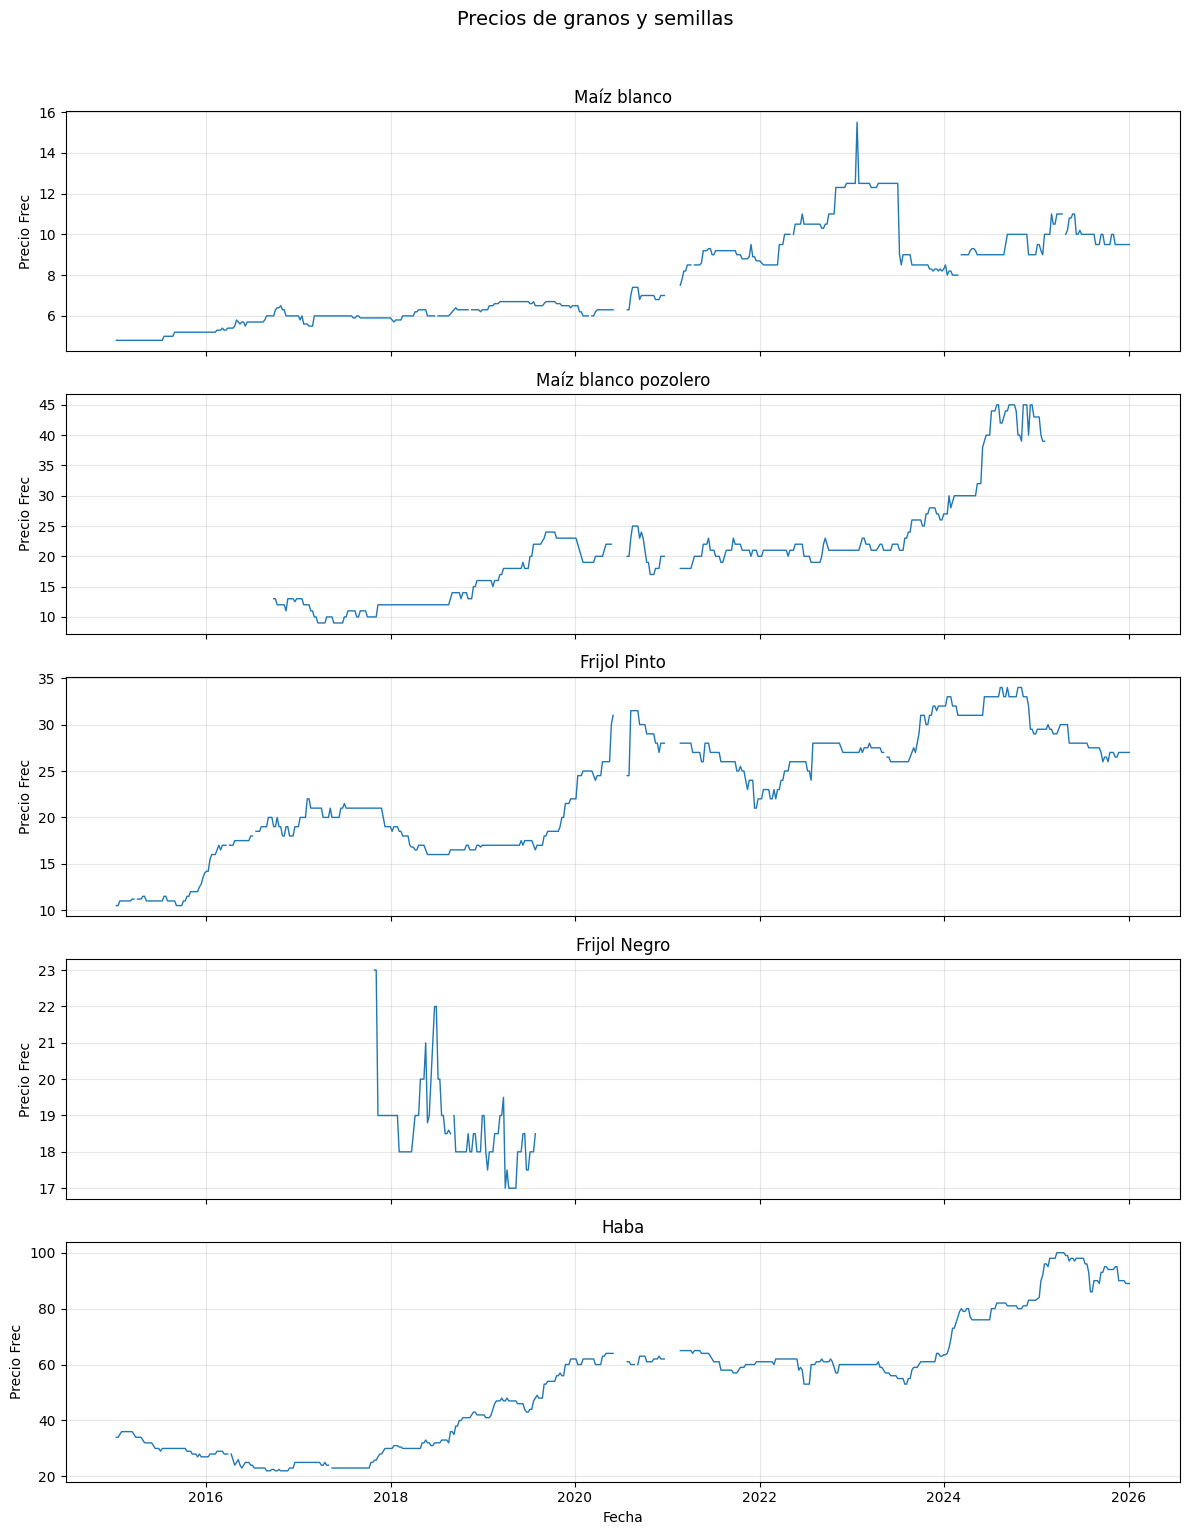

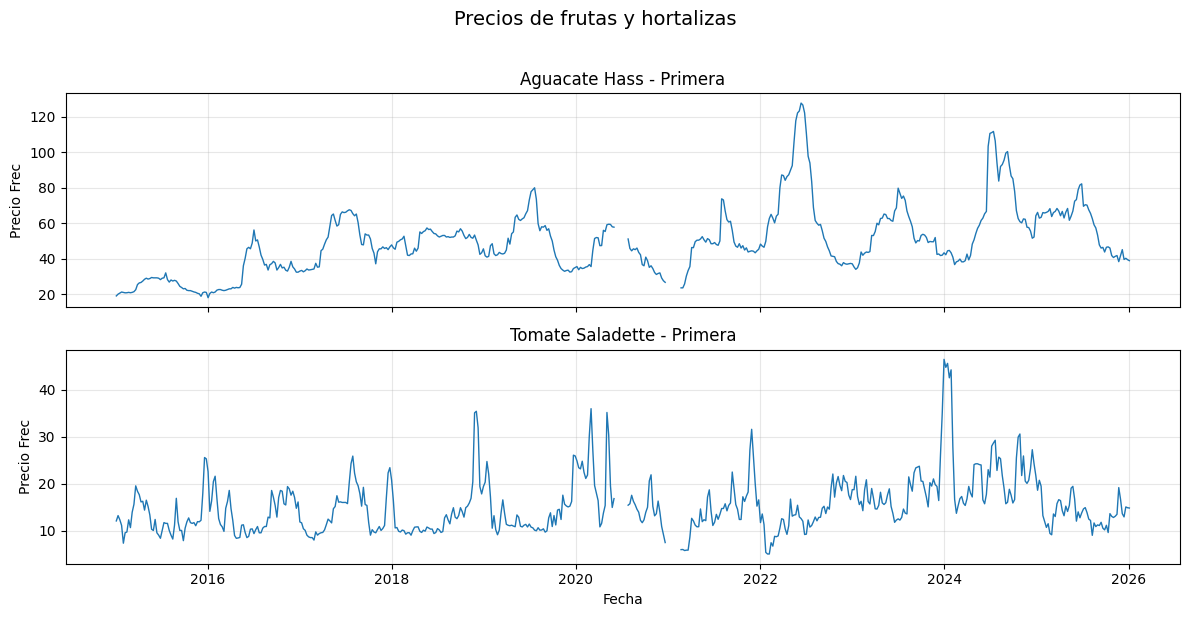

In [42]:
def graficar_series_por_categoria(df_categoria, productos, titulo):
    n = len(productos)
    fig, axes = plt.subplots(n, 1, figsize=(12, 3 * n), sharex=True)
    if n == 1:
        axes = [axes]
    for ax, producto in zip(axes, productos):
        serie = serie_semanal(df_categoria, producto)
        ax.plot(serie.index, serie.values, linewidth=1)
        ax.set_title(producto)
        ax.set_ylabel(COLUMNA_PRECIO)
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel('Fecha')
    fig.suptitle(titulo, y=1.02, fontsize=14)
    fig.tight_layout()
    plt.show()

graficar_series_por_categoria(df_granos, PRODUCTOS_GRANOS, 'Precios de granos y semillas')
graficar_series_por_categoria(df_hortalizas, PRODUCTOS_HORTALIZAS, 'Precios de frutas y hortalizas')

## 2. Datos faltantes

% de semanas faltantes por producto (tras resamplear a semanal):
  Maíz blanco: 3.8%
  Maíz blanco pozolero: 3.7%
  Frijol Pinto: 3.3%
  Frijol Negro: 1.1%
  Haba: 3.1%
  Aguacate Hass - Primera: 2.6%
  Tomate Saladette - Primera: 2.6%


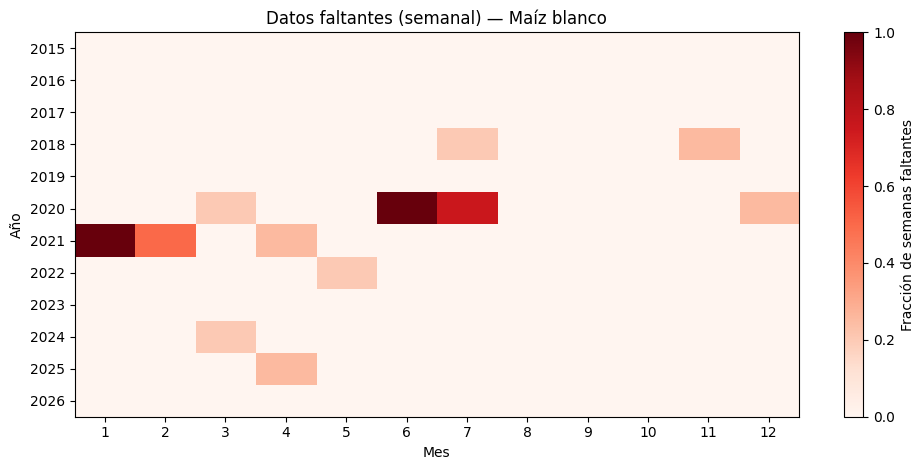

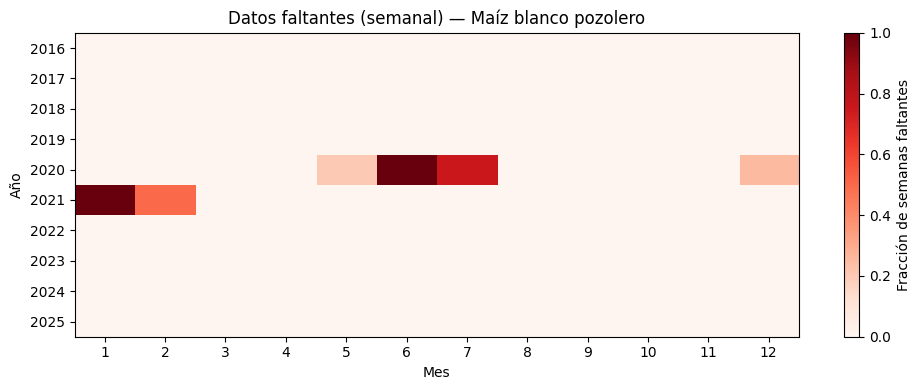

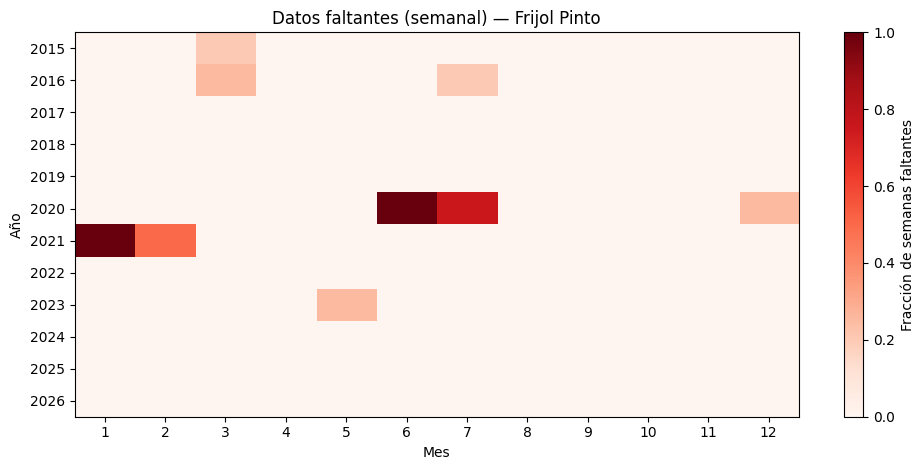

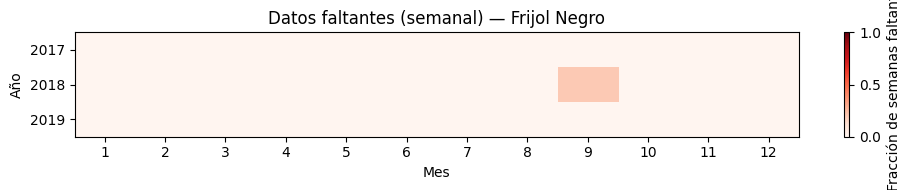

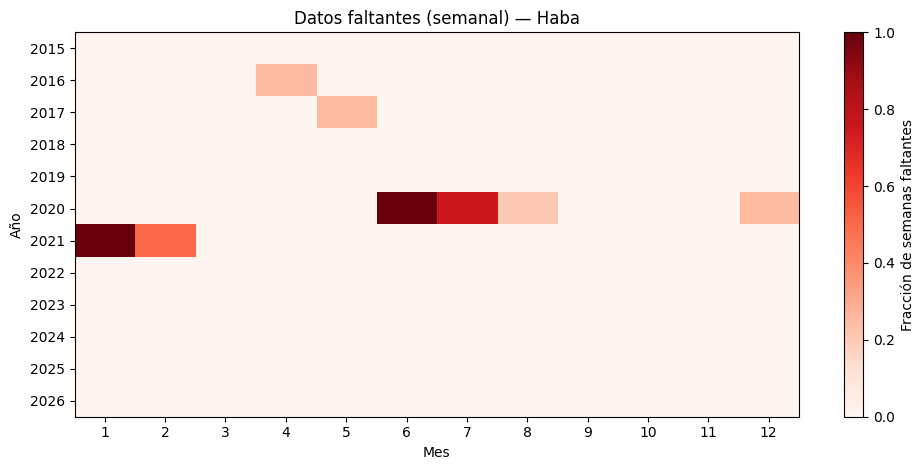

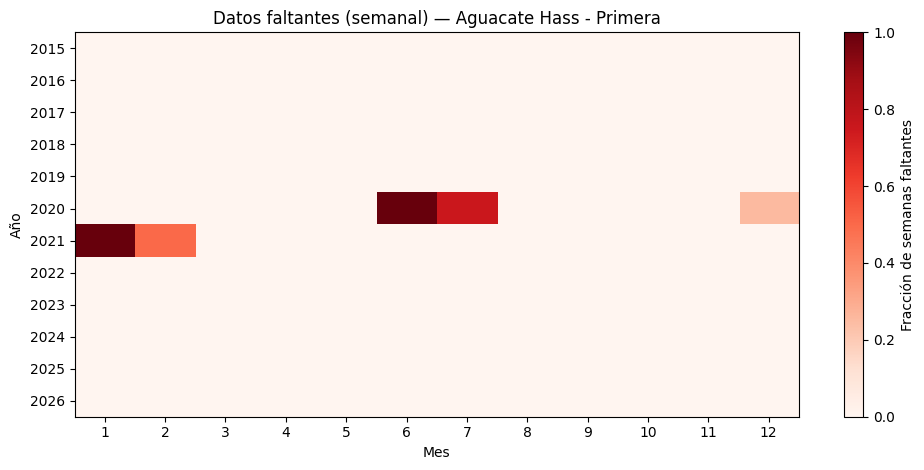

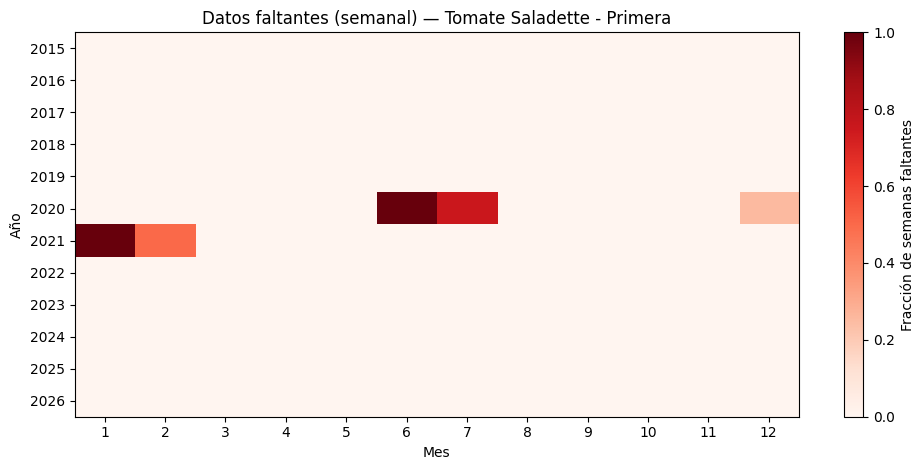

In [43]:
print("% de semanas faltantes por producto (tras resamplear a semanal):")
for producto in PRODUCTOS_GRANOS + PRODUCTOS_HORTALIZAS:
    semanal = serie_semanal(df, producto)
    pct = 100 * semanal.isna().mean()
    print(f"  {producto}: {pct:.1f}%")

for producto in PRODUCTOS_GRANOS + PRODUCTOS_HORTALIZAS:
    semanal = serie_semanal(df, producto)
    fraccion = matriz_faltantes_mensual(semanal)
    graficar_mapa_faltantes(fraccion, f"Datos faltantes (semanal) — {producto}")

## 3. Comparación por estado de origen

**Corrección importante:** lo que esta sección usaba como "Origen" en realidad era la **presentación** (tamaño de caja) — el sitio del SNIIM no regresa el estado de origen como columna de la tabla, es un filtro que se aplica en la búsqueda. El scraper ahora consulta cada estado por separado y etiqueta cada fila con `Origen_Estado`; lo que antes se llamaba `Origen` ahora se llama correctamente `Presentación`.

**Sobre los huecos que vas a ver aquí y no en la serie armonizada:** son esperados, no un error — basta que UN estado reporte esa semana para que la armonizada no tenga hueco (sección 3b). Con reporteo diario, un hueco disperso/aleatorio casi nunca deja una semana entera sin dato tras resamplear, así que si ves huecos reales aquí, lo más probable es que sean un bloque de ausencia real (temporada baja de ese estado).

Tomate Saladette - Primera: estados de origen detectados -> ['Puebla', 'Sinaloa']


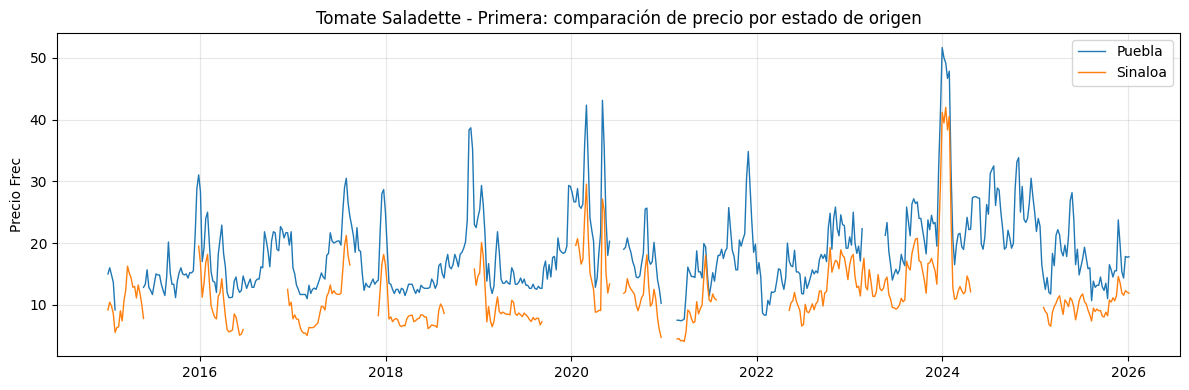

Tomate Saladette - Primera (Puebla): 7.3% de semanas faltantes


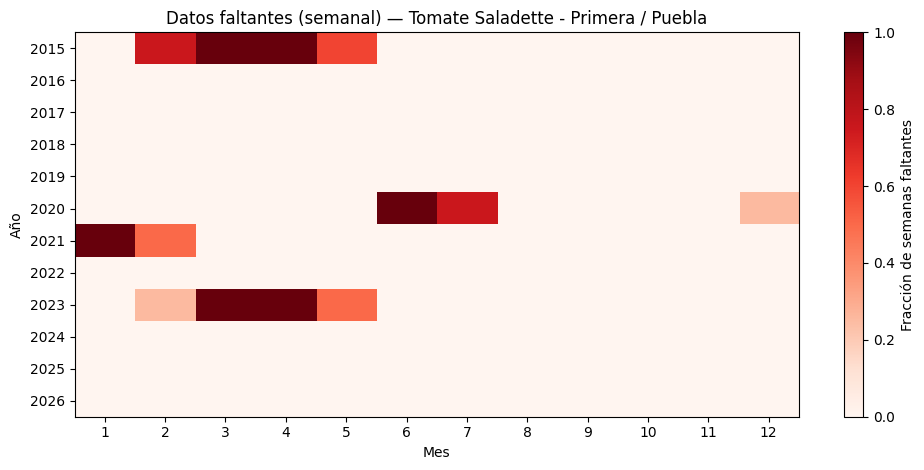

Tomate Saladette - Primera (Sinaloa): 34.4% de semanas faltantes


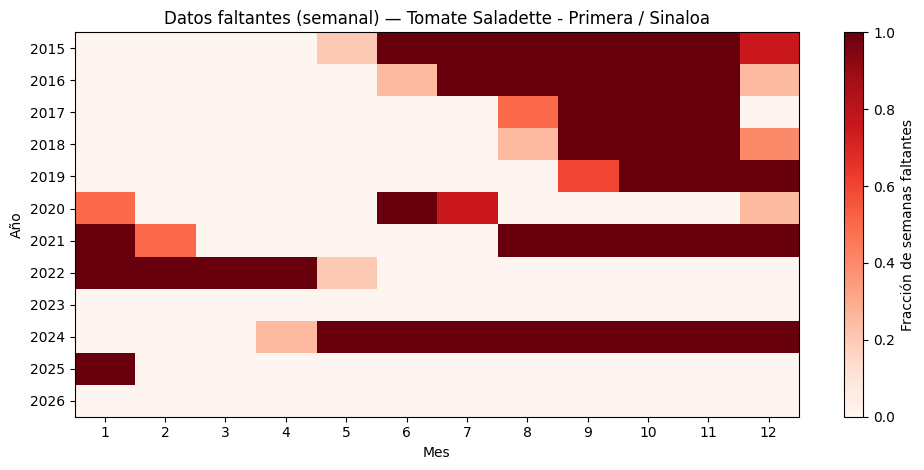

In [44]:
def graficar_comparacion_origenes(df_fuente, producto):
    series_por_origen = serie_semanal_por_origen(df_fuente, producto)
    fig, ax = plt.subplots(figsize=(12, 4))
    for origen, serie in series_por_origen.items():
        ax.plot(serie.index, serie.values, label=origen, linewidth=1)
    ax.set_title(f'{producto}: comparación de precio por estado de origen')
    ax.set_ylabel(COLUMNA_PRECIO)
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
    return series_por_origen


series_por_origen_de = {}
if 'Origen_Estado' in df.columns:
    for producto in PRODUCTOS_GRANOS + PRODUCTOS_HORTALIZAS:
        estados = df[df['Producto_Buscado'] == producto]['Origen_Estado'].dropna().unique()
        if len(estados) > 1:
            print(f"{producto}: estados de origen detectados -> {list(estados)}")
            series_por_origen_de[producto] = graficar_comparacion_origenes(df, producto)
else:
    print("[!] Esta versión del CSV no tiene la columna 'Origen_Estado' — vuelve a correr el "
          "scraper actualizado para obtener el desglose por estado.")

for producto, series_por_origen in series_por_origen_de.items():
    for origen, semanal in series_por_origen.items():
        pct = 100 * semanal.isna().mean()
        print(f"{producto} ({origen}): {pct:.1f}% de semanas faltantes")
        fraccion = matriz_faltantes_mensual(semanal)
        graficar_mapa_faltantes(fraccion, f"Datos faltantes (semanal) — {producto} / {origen}")

## 3b. Por qué `serie_semanal` usa la serie armonizada

Promediar los estados tal cual (sin ajustar nivel) genera un salto artificial cada vez que un estado entra o sale de temporada — no porque el precio real haya cambiado, sino porque cambia a quién estás promediando. Esta celda corrige eso: calcula el desfase de nivel entre estados usando solo las semanas donde ambos reportan, centra ambas series a un nivel intermedio, y ya entonces promedia. Es la misma serie que usan las secciones 1, 2 y 4 — esta celda solo la grafica junto a las series individuales para que veas el ajuste. También imprime la desviación estándar del desfase junto con su valor — si sale grande en relación al desfase, la brecha entre estados no es tan constante como este método asume, y conviene revisar el resultado con más cautela.

Tomate Saladette - Primera: desfase 'Sinaloa' vs 'Puebla' = -6.55 (desviación estándar de la diferencia semanal: 2.26 — si es grande respecto al desfase, la brecha no es tan constante como asume este ajuste)


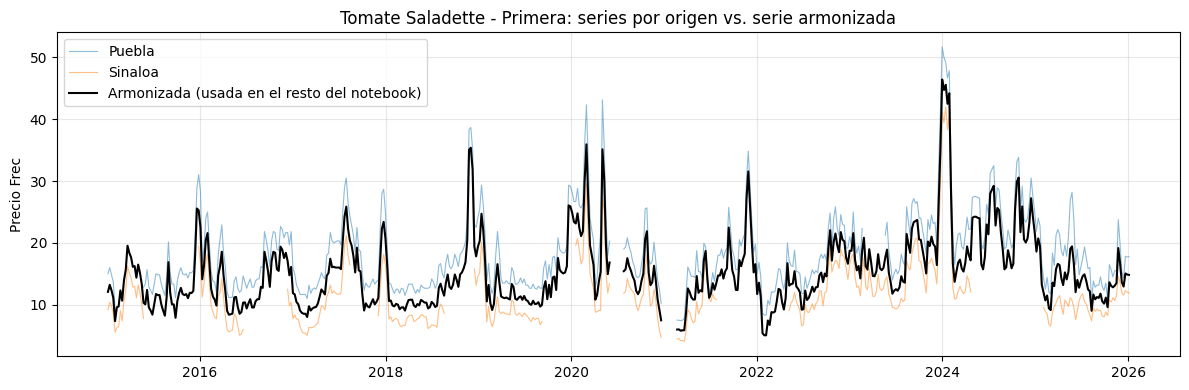

In [45]:
def graficar_armonizada(df_fuente, producto):
    series_por_origen = serie_semanal_por_origen(df_fuente, producto)
    combinada = calcular_serie_armonizada(df_fuente, producto, verbose=True)

    fig, ax = plt.subplots(figsize=(12, 4))
    for origen, serie in series_por_origen.items():
        ax.plot(serie.index, serie.values, label=origen, linewidth=0.8, alpha=0.5)
    ax.plot(combinada.index, combinada.values, label='Armonizada (usada en el resto del notebook)',
            linewidth=1.5, color='black')
    ax.set_title(f'{producto}: series por origen vs. serie armonizada')
    ax.set_ylabel(COLUMNA_PRECIO)
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
    return combinada


series_armonizadas = {}
for producto in series_por_origen_de:
    series_armonizadas[producto] = graficar_armonizada(df, producto)

## 4. Estacionalidad y tendencia (descomposición STL, semanal)

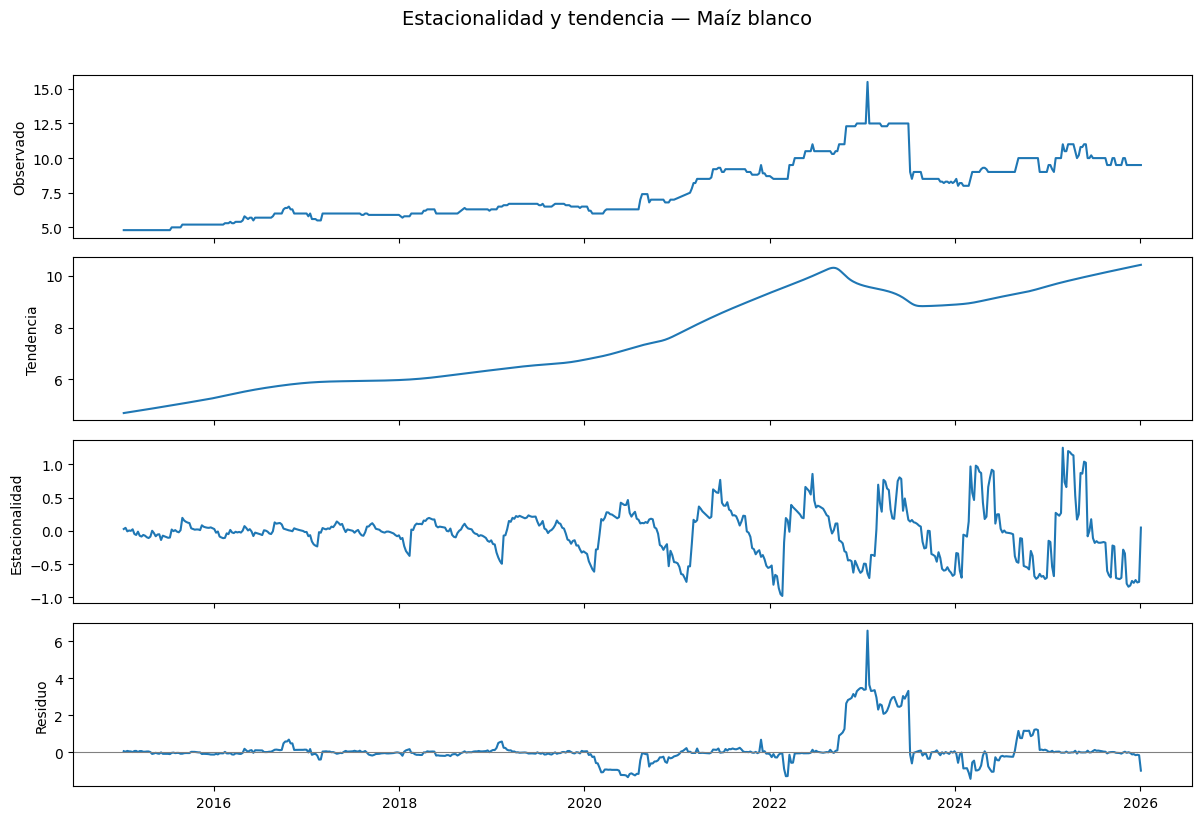

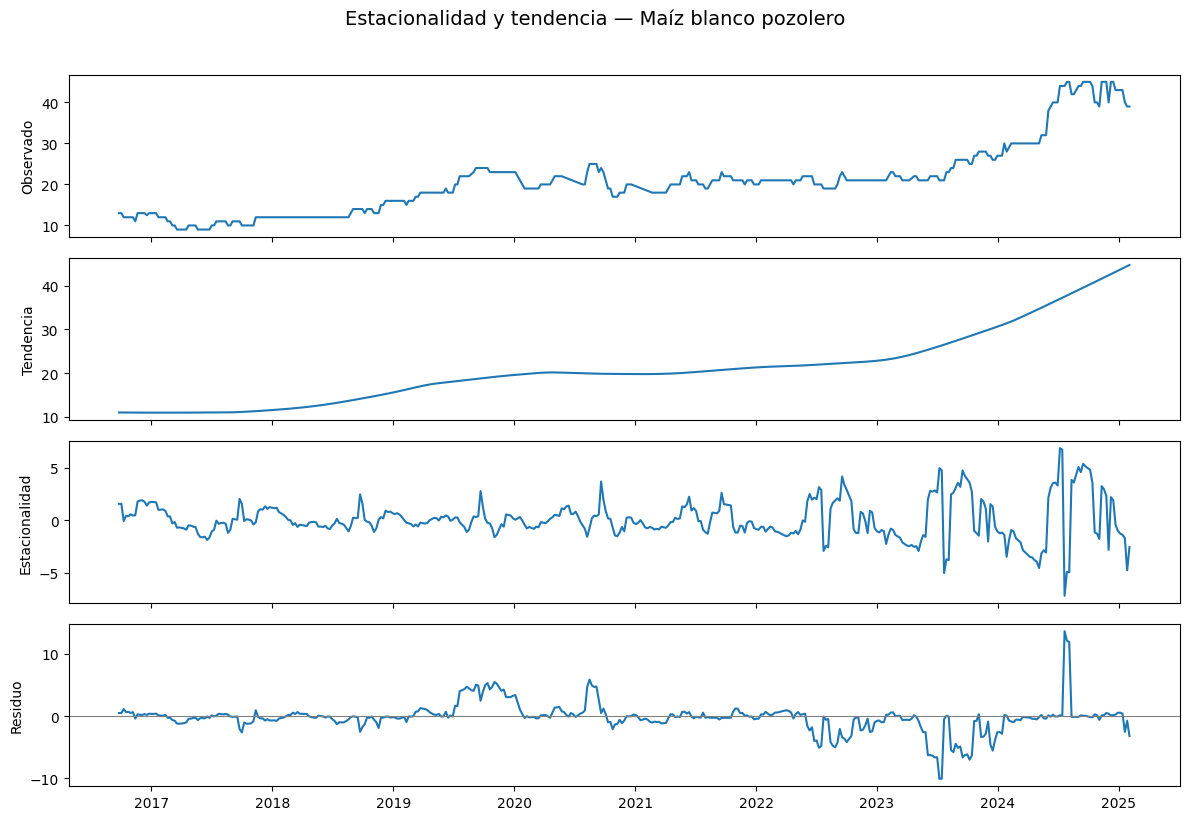

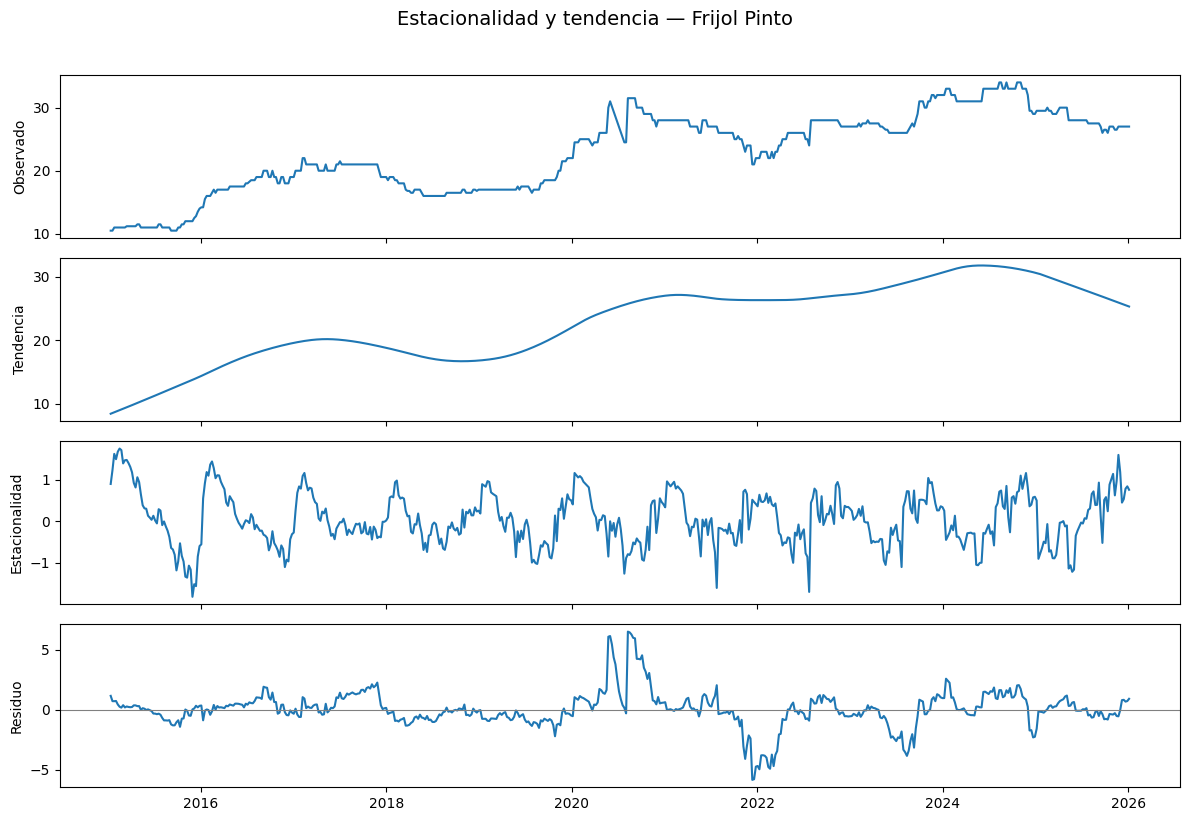

[!] Frijol Negro: no hay suficiente historial (se necesitan al menos 104 semanas) para una descomposición confiable; se omite.


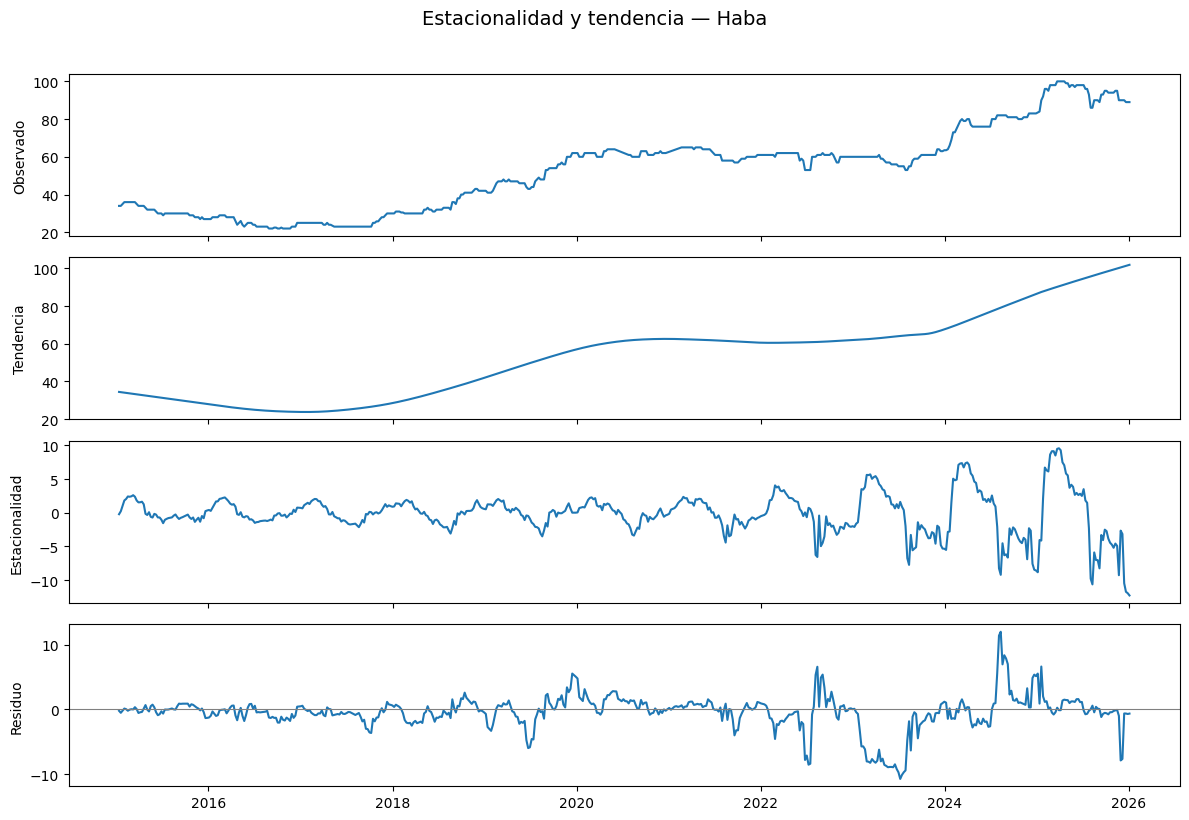

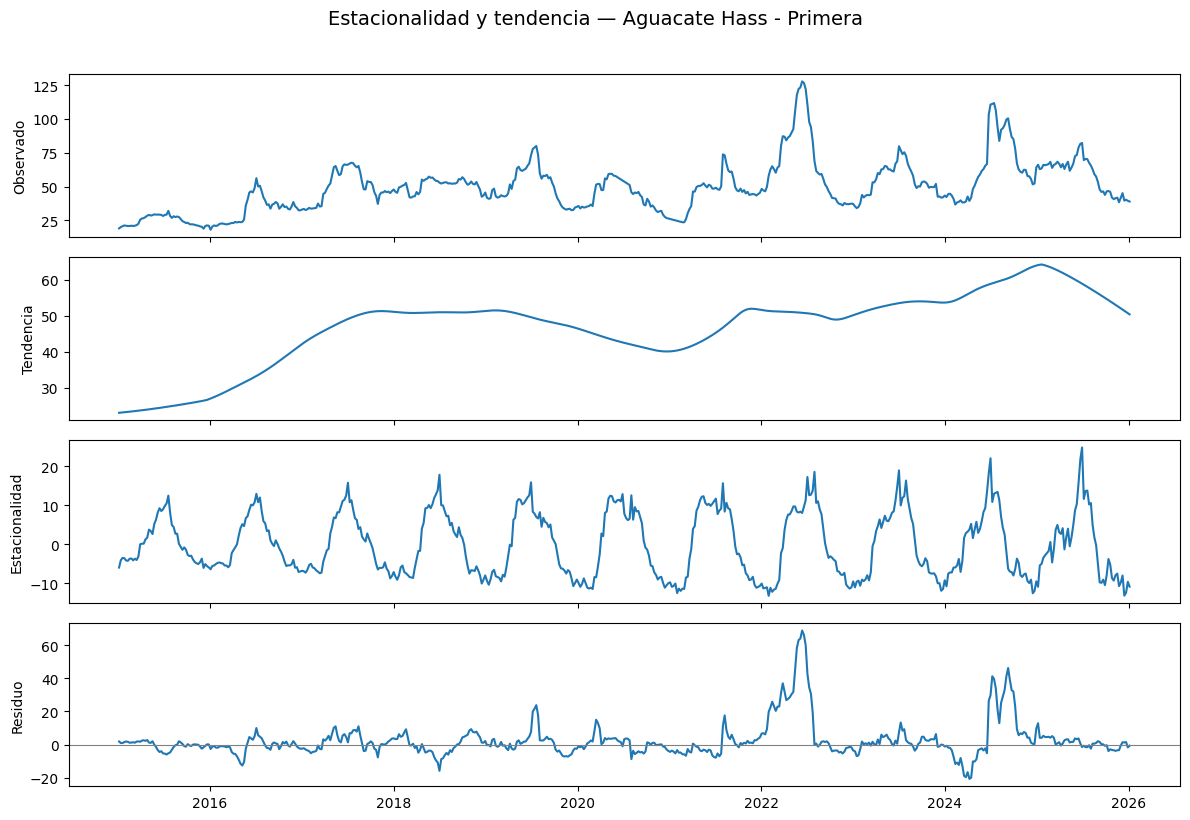

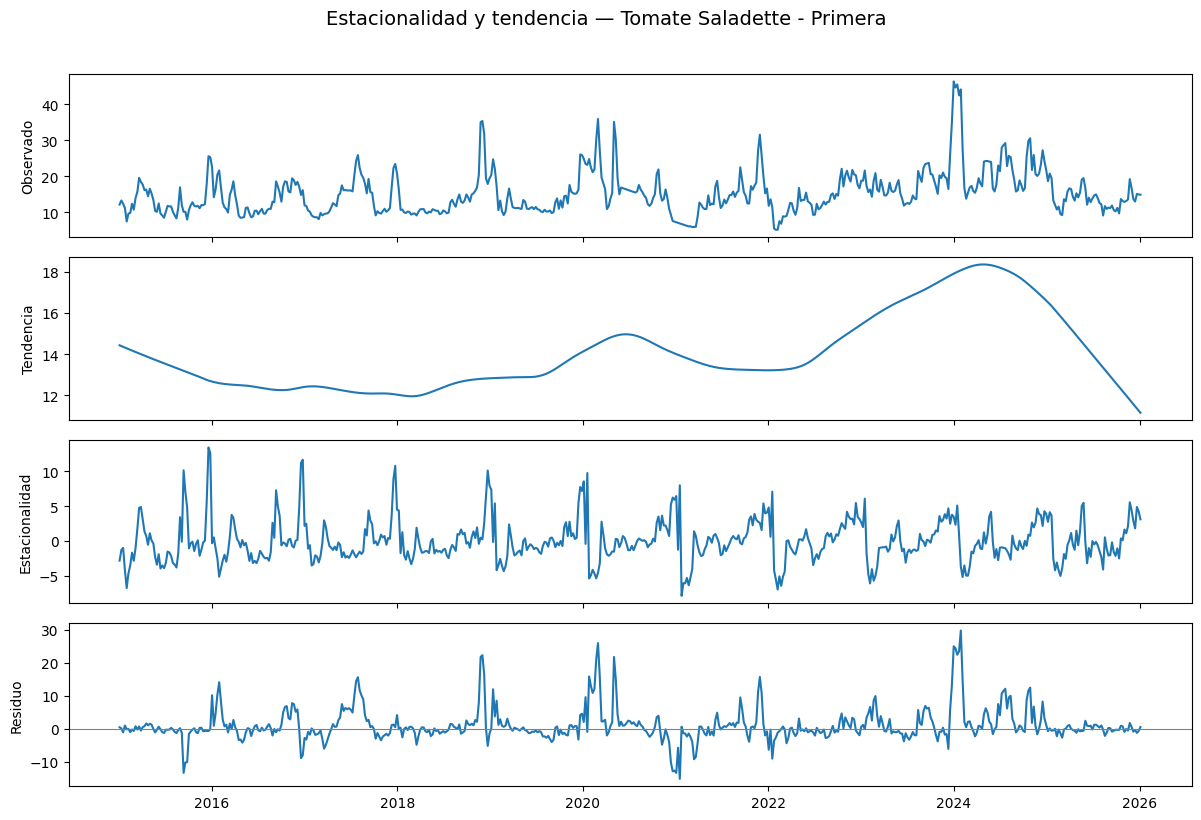

In [46]:
def descomponer_estacionalidad(semanal, periodo=PERIODO_ESTACIONAL):
    serie_completa = semanal.interpolate(limit_direction='both')
    stl = STL(serie_completa, period=periodo, robust=True)
    return stl.fit()


def graficar_descomposicion(resultado, titulo):
    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    axes[0].plot(resultado.observed); axes[0].set_ylabel('Observado')
    axes[1].plot(resultado.trend); axes[1].set_ylabel('Tendencia')
    axes[2].plot(resultado.seasonal); axes[2].set_ylabel('Estacionalidad')
    axes[3].plot(resultado.resid); axes[3].set_ylabel('Residuo')
    axes[3].axhline(0, color='gray', linewidth=0.8)
    fig.suptitle(titulo, y=1.02, fontsize=14)
    fig.tight_layout()
    plt.show()


for producto in PRODUCTOS_GRANOS + PRODUCTOS_HORTALIZAS:
    semanal = serie_semanal(df, producto)
    if semanal.dropna().shape[0] < 2 * PERIODO_ESTACIONAL:
        print(f"[!] {producto}: no hay suficiente historial (se necesitan al menos {2*PERIODO_ESTACIONAL} semanas) para una descomposición confiable; se omite.")
        continue
    resultado = descomponer_estacionalidad(semanal)
    graficar_descomposicion(resultado, f"Estacionalidad y tendencia — {producto}")

## 5. Modelado inicial: concentración productiva y comparación ARIMA / SARIMA / ARIMAX / SARIMAX / Koyck / STL

Extiende el mismo procedimiento del notebook de semillas corregido (`Análisis_semillas.ipynb`, TT 2026-B148) a los 5 productos: las 3 semillas (Haba, Maíz blanco, Frijol Pinto) y las 2 hortalizas (Aguacate Hass - Primera, Tomate Saladette - Primera).

**Qué incluye esta sección:**
1. Municipios que concentran el 50 % de la producción nacional (SIAP), para los 5 productos.
2. Prueba ADF (orden de integración) para los 5.
3. ACF/PACF y CCF (clima vs. precio) — CCF solo para los productos con clima suficiente.
4. Búsqueda de orden SARIMA, rezago climático óptimo, ajuste SARIMAX y comparación contra SARIMA sin clima y pronósticos ingenuos.
5. Tabla comparativa final de los 5 productos.
6. Modelo de Koyck (rezagos distribuidos geométricos) para los productos con clima, comparado contra SARIMA y SARIMAX (secciones 5.10 y 5.11).
7. Descomposición STL: ARIMA para la tendencia, SARIMA para la estacionalidad y un modelo para el residuo según sea ruido blanco o no, con y sin clima, recombinados y comparados con todo lo anterior (secciones 5.12 y 5.13).

**Clima.** Las 3 semillas usan el clima ya asignado en `Clima_Municipios_Top50_Semanal_v2.csv` / `Asignacion_Espacial_Validada_k5_v2.csv` (de `Análisis_semillas.ipynb`). Para Aguacate Hass y Tomate Saladette, la sección 5.3 calcula sus municipios del Top 50 % (`Municipios_Top50_5_Productos.csv`), que es la entrada de `Clima_Hortalizas_Aguacate_Tomate.ipynb`; ese notebook asigna estaciones con el mismo método (K = 5 vecinos, cobertura ≥ 80 %) y produce `Clima_Hortalizas_Top50_Semanal_v2.csv` y `Asignacion_Hortalizas_k5_v2.csv`.

La sección 5.5 lee todos esos archivos que existan en la carpeta y decide **sola**, producto por producto, si hay clima suficiente: estaciones asignadas y al menos la mitad de las semanas del año de prueba con datos reales. Los productos que no cumplen se modelan solo con ARIMA/SARIMA y se imprime el motivo. Para activar las hortalizas basta copiar sus dos archivos a esta carpeta y volver a correr desde la sección 5.5.

La serie de precio que usa todo lo de aquí en adelante es la **misma que usan las secciones 1-4**: para Tomate Saladette usa la armonizada por estado de origen.

### 5.1 Configuración del modelado

In [47]:
# [CONFIGURACIÓN DEL MODELADO]
import os, itertools, unicodedata, warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning  # statsmodels reactiva sus avisos al importarse
warnings.filterwarnings("ignore")

# --- Periodo (igual que en el resto del notebook) ---
FECHA_INICIO_MODELADO = '2015-01-01'
FECHA_FIN_MODELADO = '2025-12-31'
ANIO_PRUEBA = 2025  # entrenamiento: 2015-2024 | prueba: 2025
FECHA_CORTE_MODELADO = pd.Timestamp(f'{ANIO_PRUEBA}-01-01')

# --- Correspondencia SNIIM (precio) -> SIAP (producción) ---
# Ajusta el lado derecho si el nombre de 'Cultivo' en tus CSV del SIAP es distinto: la sección
# 5.3 avisa si alguno de estos nombres no encuentra ningún registro.
MAPEO_CULTIVO_SIAP = {
    'Haba': 'Haba grano',
    'Maíz blanco': 'Maíz grano',
    'Frijol Pinto': 'Frijol',
    'Aguacate Hass - Primera': 'Aguacate',
    'Tomate Saladette - Primera': 'Tomate rojo (jitomate)',
}

# --- Archivos de entrada: SIAP y clima ya asignado ---
ANIOS_SIAP = range(2015, 2025)  # cierres agrícolas 2015-2024
PATRON_SIAP = 'Cierre_agricola_mun_{anio}.csv'
# Se leen todos los que existan, en pares (clima, asignación): semillas (Análisis_semillas.ipynb)
# y hortalizas (Clima_Hortalizas_Aguacate_Tomate.ipynb).
ARCHIVOS_CLIMA = ['Clima_Municipios_Top50_Semanal_v2.csv', 'Clima_Hortalizas_Top50_Semanal_v2.csv']
ARCHIVOS_ASIGNACION = ['Asignacion_Espacial_Validada_k5_v2.csv', 'Asignacion_Hortalizas_k5_v2.csv']

# --- Archivo de salida: municipios Top 50 % de los 5 productos ---
ARCHIVO_TOP50_5 = 'Municipios_Top50_5_Productos.csv'
CARPETA_RESULTADOS_MODELADO = 'resultados_modelado'
os.makedirs(CARPETA_RESULTADOS_MODELADO, exist_ok=True)

# --- Productos a modelar (cuáles tienen clima suficiente lo decide la sección 5.5) ---
PRODUCTOS_MODELADO = list(MAPEO_CULTIVO_SIAP)
MIN_SEMANAS_PRUEBA_CON_CLIMA = 0.5  # fracción mínima de semanas del año de prueba con clima real para usar SARIMAX (0 = sin exigir)

# --- Hiperparámetros de modelado ---
S_ESTACIONAL = 52
D_ESTACIONAL = 0  # fijo: el AIC no es comparable entre órdenes de diferenciación
MAX_LAG = 100
PASO_LAG = 1
VARIABLES_CLIMA = ['TMAX', 'TMIN', 'PRECIP']
AGREGACION_CLIMA = 'ponderado'  # 'ponderado' (por producción) o 'simple'


def slug(texto):
    """Nombre de archivo sin acentos ni espacios."""
    t = unicodedata.normalize('NFKD', str(texto)).encode('ascii', 'ignore').decode()
    return t.lower().replace(' ', '_')


print("Configuración del modelado cargada.")
print(f"Productos a modelar: {PRODUCTOS_MODELADO}")

Configuración del modelado cargada.
Productos a modelar: ['Haba', 'Maíz blanco', 'Frijol Pinto', 'Aguacate Hass - Primera', 'Tomate Saladette - Primera']


### 5.2 Serie de precios semanal para el modelado (W-WED, con máscara de observado)

`serie_semanal` (sección 1-4) ya elige la armonizada cuando aplica, pero usa semanas domingo-sábado y no distingue semanas reales de imputadas. Para el modelado necesitamos: (a) el mismo anclaje jueves-miércoles que usa el clima del SMN —si no, el rezago en semanas no coincide entre precio y clima—, y (b) saber qué semanas son reales, para no evaluar el pronóstico contra datos que inventamos nosotros. `serie_semanal_precio_modelado` hace ambas cosas, reutilizando la misma armonización por estado de origen que la sección 3b.

In [48]:
def indice_semanal_modelado(inicio=FECHA_INICIO_MODELADO, fin=FECHA_FIN_MODELADO):
    """Semanas de jueves a miércoles, etiquetadas con el miércoles en que terminan."""
    return pd.date_range(pd.Timestamp(inicio), pd.Timestamp(fin), freq='W-WED')


def _proyectar_a_miercoles(sub):
    sub = sub.copy()
    sub['Semana_Miercoles'] = sub['Fecha'].dt.to_period('W-WED').dt.end_time.dt.normalize()
    return sub


def serie_semanal_por_origen_modelado(df_fuente, producto, inicio=FECHA_INICIO_MODELADO, fin=FECHA_FIN_MODELADO):
    """Como serie_semanal_por_origen (sección 3), pero anclada a W-WED y SIN imputar: se usa
    para armonizar antes de completar huecos."""
    sub = df_fuente[df_fuente['Producto_Buscado'] == producto].dropna(subset=['Fecha', COLUMNA_PRECIO, 'Origen_Estado'])
    sub = sub[sub['Origen_Estado'] != '']
    idx = indice_semanal_modelado(inicio, fin)
    series = {}
    if sub.empty:
        return series
    sub = _proyectar_a_miercoles(sub)
    for origen, grupo in sub.groupby('Origen_Estado'):
        s = grupo.groupby('Semana_Miercoles')[COLUMNA_PRECIO].mean()
        series[origen] = s.reindex(idx)
    return series


def calcular_serie_armonizada_modelado(df_fuente, producto, inicio=FECHA_INICIO_MODELADO, fin=FECHA_FIN_MODELADO, verbose=False):
    """Igual que calcular_serie_armonizada (sección 3b), pero sobre las series W-WED sin imputar."""
    series_por_origen = serie_semanal_por_origen_modelado(df_fuente, producto, inicio, fin)
    if len(series_por_origen) < 2:
        return None
    nombres = list(series_por_origen.keys())
    referencia = series_por_origen[nombres[0]]
    desfases = {nombres[0]: 0.0}
    for nombre in nombres[1:]:
        serie = series_por_origen[nombre]
        mascara = referencia.notna() & serie.notna()
        traslape = referencia.index[mascara]
        if len(traslape) < 8:
            print(f"[!] {producto}: solo {len(traslape)} semanas de traslape entre "
                  f"'{nombres[0]}' y '{nombre}' — el desfase estimado puede no ser confiable.")
        desfases[nombre] = (serie[traslape] - referencia[traslape]).mean()
        if verbose and len(traslape) >= 8:
            print(f"{producto}: desfase '{nombre}' vs '{nombres[0]}' = {desfases[nombre]:.2f}")
    ajuste = sum(desfases.values()) / len(desfases)
    ajustadas = {n: series_por_origen[n] - desfases[n] + ajuste for n in nombres}
    combinada = pd.concat(ajustadas.values(), axis=1, sort=True).mean(axis=1)
    combinada = combinada.reindex(indice_semanal_modelado(inicio, fin))
    combinada.name = producto
    return combinada


def serie_semanal_precio_modelado(df_fuente, producto, inicio=FECHA_INICIO_MODELADO, fin=FECHA_FIN_MODELADO):
    """Serie semanal (W-WED) imputada + máscara de semanas observadas. Usa la serie armonizada
    cuando el producto tiene más de un estado de origen (mismo criterio que la sección 3b)."""
    idx = indice_semanal_modelado(inicio, fin)
    cruda = None
    if 'Origen_Estado' in df_fuente.columns:
        estados = df_fuente[df_fuente['Producto_Buscado'] == producto]['Origen_Estado'].dropna().unique()
        estados = [e for e in estados if e not in ('', 'Todos')]
        if len(estados) > 1:
            cruda = calcular_serie_armonizada_modelado(df_fuente, producto, inicio, fin)
    if cruda is None:
        sub = df_fuente[df_fuente['Producto_Buscado'] == producto].dropna(subset=['Fecha', COLUMNA_PRECIO])
        if sub.empty:
            cruda = pd.Series(index=idx, dtype=float)
        else:
            sub = _proyectar_a_miercoles(sub)
            s = sub.groupby('Semana_Miercoles')[COLUMNA_PRECIO].mean()
            cruda = s.reindex(idx)
    observado = cruda.notna()
    imputada = cruda.interpolate('linear', limit_area='inside').bfill().ffill()
    imputada.name = producto
    return imputada, observado


print(f"Semanas con dato real (de {len(indice_semanal_modelado())} semanas totales, "
      f"{FECHA_INICIO_MODELADO} a {FECHA_FIN_MODELADO}):")
for producto in PRODUCTOS_MODELADO:
    _, observado = serie_semanal_precio_modelado(df, producto)
    print(f"  {producto}: {int(observado.sum())} ({100*observado.mean():.1f} %)")

Semanas con dato real (de 574 semanas totales, 2015-01-01 a 2025-12-31):
  Haba: 556 (96.9 %)
  Maíz blanco: 552 (96.2 %)
  Frijol Pinto: 555 (96.7 %)
  Aguacate Hass - Primera: 560 (97.6 %)
  Tomate Saladette - Primera: 560 (97.6 %)


### 5.3 Concentración productiva (SIAP): municipios que cubren el 50 % de la producción nacional

Se usa la producción municipal del SIAP (cierres agrícolas 2015-2024) para cada uno de los 5 productos, vía `MAPEO_CULTIVO_SIAP`. El resultado (`Municipios_Top50_5_Productos.csv`) es, para las 2 hortalizas, el insumo para asignarles estación climática en otro notebook con el mismo método (K = 5 vecinos, cobertura ≥ 80 %) ya usado para las 3 semillas.

In [49]:
def leer_siap(anios=ANIOS_SIAP, patron=PATRON_SIAP, cultivos=None):
    """Lee los cierres agrícolas municipales del SIAP y normaliza encabezados (varían de año a
    año: mayúsculas, espacios, guiones bajos)."""
    cultivos = set(cultivos) if cultivos is not None else None
    lista = []
    for anio in anios:
        archivo = patron.format(anio=anio)
        if not os.path.exists(archivo):
            print(f" [-] Archivo no encontrado: {archivo}")
            continue
        df_siap = pd.read_csv(archivo, encoding='latin1', low_memory=False)
        df_siap.columns = df_siap.columns.str.lower().str.replace(' ', '').str.replace('_', '')
        buscar = lambda opciones: next((c for c in df_siap.columns if c in opciones), None)
        c_est = buscar(['nomestado', 'estado', 'nombreestado'])
        c_mun = buscar(['nommunicipio', 'municipio', 'nombremunicipio'])
        c_cul = buscar(['nomcultivo', 'cultivo', 'nombrecultivo', 'nomcultivosinum'])
        c_vol = buscar(['volumenproduccion', 'volumen', 'produccion', 'volproduccion'])
        if not all([c_est, c_mun, c_cul, c_vol]):
            print(f" [!] {archivo}: faltan columnas clave")
            continue
        df_siap = df_siap.rename(columns={c_est: 'Estado', c_mun: 'Municipio', c_cul: 'Cultivo', c_vol: 'Produccion'})
        df_siap['Produccion'] = pd.to_numeric(df_siap['Produccion'].astype(str).str.replace(',', ''), errors='coerce').fillna(0)
        if cultivos is not None:
            df_siap = df_siap[df_siap['Cultivo'].isin(cultivos)]
        df_siap = df_siap[['Estado', 'Municipio', 'Cultivo', 'Produccion']].copy()
        df_siap['Anio'] = anio
        lista.append(df_siap)
        print(f" [+] {archivo} cargado.")
    if not lista:
        return pd.DataFrame(columns=['Estado', 'Municipio', 'Cultivo', 'Produccion', 'Anio'])
    return pd.concat(lista, ignore_index=True)


df_siap_historico = leer_siap(cultivos=set(MAPEO_CULTIVO_SIAP.values()))
df_siap_agrupado = df_siap_historico.groupby(['Estado', 'Municipio', 'Cultivo'])['Produccion'].sum().reset_index()

lista_top50 = []
print("\nMUNICIPIOS QUE CONCENTRAN EL 50 % DE LA PRODUCCIÓN NACIONAL (2015-2024)")
for producto_sniim, cultivo_siap in MAPEO_CULTIVO_SIAP.items():
    d = df_siap_agrupado[df_siap_agrupado['Cultivo'] == cultivo_siap].sort_values('Produccion', ascending=False).copy()
    if d.empty or d['Produccion'].sum() == 0:
        print(f"\n{producto_sniim.upper()} (SIAP: '{cultivo_siap}'): [!] no se encontraron registros. "
              f"Revisa MAPEO_CULTIVO_SIAP contra los valores reales de 'Cultivo' en tus CSV del SIAP.")
        continue
    d['Producto_SNIIM'] = producto_sniim
    d['Porcentaje_Nacional'] = 100 * d['Produccion'] / d['Produccion'].sum()
    d['Acumulado_Pct'] = d['Porcentaje_Nacional'].cumsum()
    top = d[d['Acumulado_Pct'].shift(fill_value=0) < 50].copy()  # incluye al municipio que cruza el 50 %
    lista_top50.append(top)
    print(f"\n{producto_sniim.upper()} (SIAP: '{cultivo_siap}'): {len(top)} municipios "
          f"(de {(d['Produccion'] > 0).sum()} productores)")
    for _, fila in top.head(3).iterrows():
        print(f"   * {fila['Estado']} ({fila['Municipio']}): {fila['Porcentaje_Nacional']:.2f} %")

if lista_top50:
    df_top50_5 = pd.concat(lista_top50, ignore_index=True)
    df_top50_5[['Porcentaje_Nacional', 'Acumulado_Pct']] = df_top50_5[['Porcentaje_Nacional', 'Acumulado_Pct']].round(4)
    df_top50_5.to_csv(ARCHIVO_TOP50_5, index=False, encoding='utf-8-sig')
    print(f"\nGuardado en '{ARCHIVO_TOP50_5}'.")
else:
    df_top50_5 = pd.DataFrame(columns=['Estado', 'Municipio', 'Cultivo', 'Produccion', 'Anio',
                                        'Producto_SNIIM', 'Porcentaje_Nacional', 'Acumulado_Pct'])
    print("\n[!] No se generó ningún municipio Top 50 %. Revisa que los archivos del SIAP existan "
          f"({PATRON_SIAP.format(anio='<año>')}) y que MAPEO_CULTIVO_SIAP tenga los nombres correctos.")

 [+] Cierre_agricola_mun_2015.csv cargado.
 [+] Cierre_agricola_mun_2016.csv cargado.
 [+] Cierre_agricola_mun_2017.csv cargado.
 [+] Cierre_agricola_mun_2018.csv cargado.
 [+] Cierre_agricola_mun_2019.csv cargado.
 [+] Cierre_agricola_mun_2020.csv cargado.
 [+] Cierre_agricola_mun_2021.csv cargado.
 [+] Cierre_agricola_mun_2022.csv cargado.
 [+] Cierre_agricola_mun_2023.csv cargado.
 [+] Cierre_agricola_mun_2024.csv cargado.

MUNICIPIOS QUE CONCENTRAN EL 50 % DE LA PRODUCCIÓN NACIONAL (2015-2024)

HABA (SIAP: 'Haba grano'): 8 municipios (de 158 productores)
   * Veracruz (Jalacingo): 17.61 %
   * Veracruz (Perote): 7.64 %
   * Veracruz (Altotonga): 5.48 %

MAÍZ BLANCO (SIAP: 'Maíz grano'): 92 municipios (de 2391 productores)
   * Sinaloa (Guasave): 4.67 %
   * Sinaloa (Culiacán): 3.72 %
   * Sinaloa (Ahome): 3.62 %

FRIJOL PINTO (SIAP: 'Frijol'): 23 municipios (de 1889 productores)
   * Zacatecas (Sombrerete): 7.27 %
   * Zacatecas (Fresnillo): 4.78 %
   * Sinaloa (Guasave): 4.68 %

A

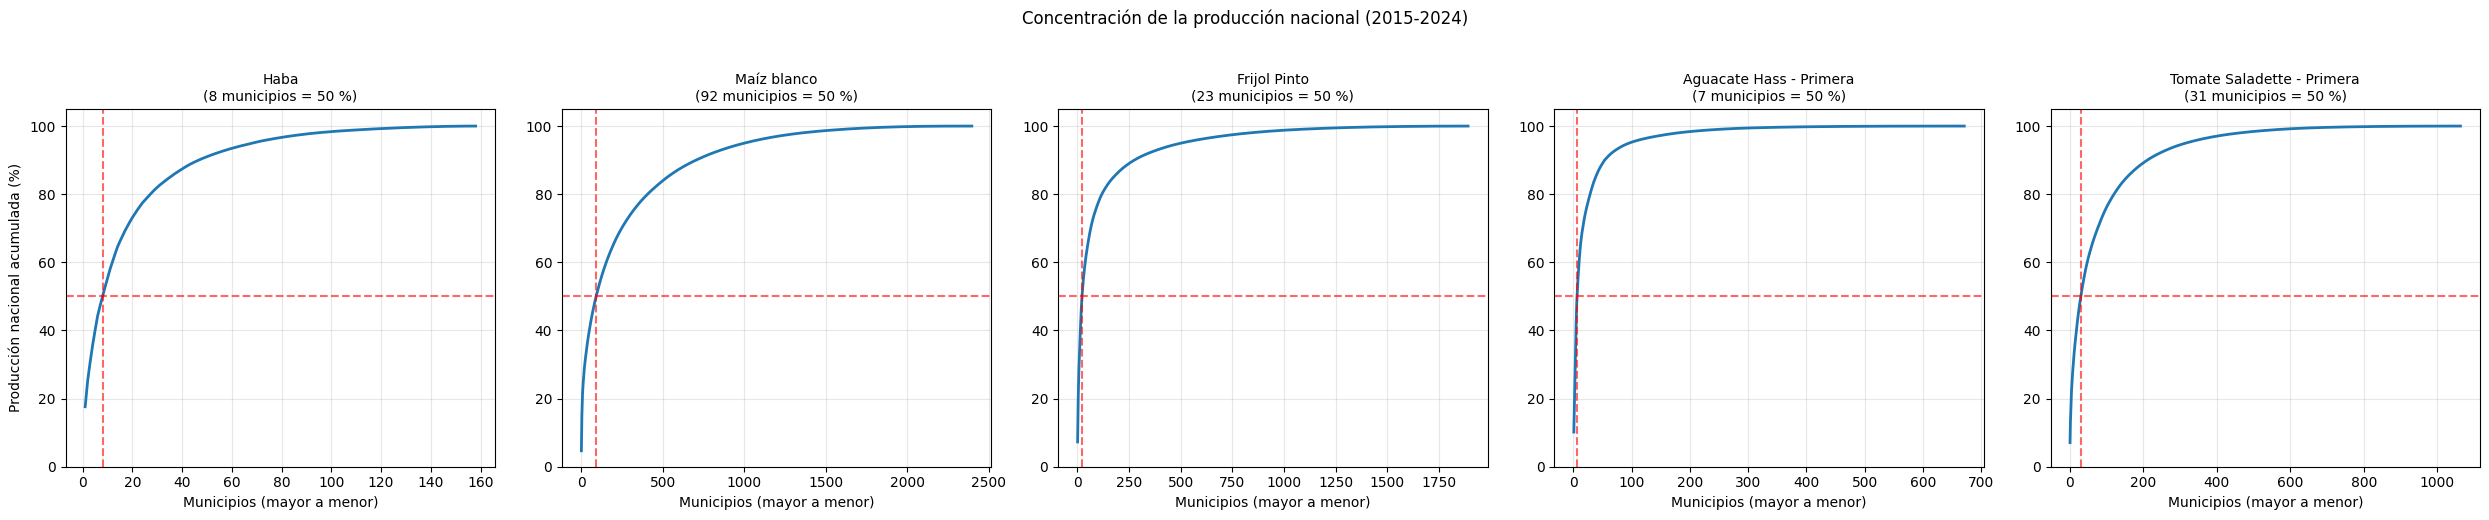

In [50]:
if not df_top50_5.empty:
    productos_con_datos = [p for p in PRODUCTOS_MODELADO if p in df_top50_5['Producto_SNIIM'].unique()]
    n = len(productos_con_datos)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    if n == 1:
        axes = [axes]
    for ax, producto in zip(axes, productos_con_datos):
        cultivo_siap = MAPEO_CULTIVO_SIAP[producto]
        d = df_siap_agrupado[df_siap_agrupado['Cultivo'] == cultivo_siap].sort_values('Produccion', ascending=False).reset_index(drop=True)
        acumulado = (100 * d['Produccion'] / d['Produccion'].sum()).cumsum()
        ax.plot(range(1, len(d) + 1), acumulado, linewidth=2)
        n50 = int((acumulado >= 50).idxmax()) + 1
        ax.axhline(50, color='red', linestyle='--', alpha=0.6)
        ax.axvline(n50, color='red', linestyle='--', alpha=0.6)
        ax.set_title(f'{producto}\n({n50} municipios = 50 %)', fontsize=10)
        ax.set_xlabel('Municipios (mayor a menor)')
        ax.set_ylim(0, 105)
        ax.grid(alpha=0.3)
    axes[0].set_ylabel('Producción nacional acumulada (%)')
    fig.suptitle('Concentración de la producción nacional (2015-2024)', y=1.03)
    fig.tight_layout()
    plt.show()
else:
    print("Sin datos para graficar las ojivas de concentración.")

### 5.4 Prueba ADF (orden de integración)

Se aplica sobre el periodo de entrenamiento (2015-2024) para no usar información del año de prueba. Si la serie no es estacionaria en niveles pero sí en primera diferencia, es I(1) y se fija d = 1 en el resto del modelado.

In [51]:
from statsmodels.tsa.stattools import adfuller

filas_adf = []
for producto in PRODUCTOS_MODELADO:
    s, _ = serie_semanal_precio_modelado(df, producto)
    s_train = s[s.index < FECHA_CORTE_MODELADO].dropna()
    for forma, x in [('Niveles', s_train), ('Primera diferencia', s_train.diff().dropna())]:
        if len(x) < 20:
            continue
        estadistico, p, rezagos, n, criticos, _ = adfuller(x, autolag='AIC')
        filas_adf.append({'Producto': producto, 'Forma': forma, 'n': n, 'Estadístico ADF': round(estadistico, 3),
                           'Valor p': round(p, 4), 'Valor crítico 5 %': round(criticos['5%'], 3),
                           'Estacionaria (5 %)': p < 0.05})
tabla_adf_5 = pd.DataFrame(filas_adf)
tabla_adf_5.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, 'tabla_adf_5_productos.csv'), index=False)
display(tabla_adf_5)

,Producto,Forma,n,Estadístico ADF,Valor p,Valor crítico 5 %,Estacionaria (5 %)
0,Haba,Niveles,513,0.301,0.9774,-2.867,False
1,Haba,Primera diferencia,513,-8.130,0.0000,-2.867,True
2,Maíz blanco,Niveles,518,-1.432,0.5670,-2.867,False
3,Maíz blanco,Primera diferencia,518,-18.658,0.0000,-2.867,True
4,Frijol Pinto,Niveles,520,-1.688,0.4371,-2.867,False
5,Frijol Pinto,Primera diferencia,519,-22.339,0.0000,-2.867,True
6,Aguacate Hass - Primera,Niveles,519,-3.637,0.0051,-2.867,True
7,Aguacate Hass - Primera,Primera diferencia,519,-13.907,0.0000,-2.867,True
8,Tomate Saladette - Primera,Niveles,518,-5.677,0.0000,-2.867,True
9,Tomate Saladette - Primera,Primera diferencia,508,-9.540,0.0000,-2.867,True


### 5.5 Clima de las estaciones ya asignadas y qué productos lo tienen

Lee todos los pares de archivos de `ARCHIVOS_CLIMA` / `ARCHIVOS_ASIGNACION` que existan (semillas y, cuando los tengas, hortalizas) y los une. Después clasifica **cada producto**: tiene clima si sus municipios del Top 50 % tienen estaciones asignadas y el clima real cubre al menos `MIN_SEMANAS_PRUEBA_CON_CLIMA` de las semanas del año de prueba (el resto de esas semanas se rellena con la climatología de entrenamiento, y con muy poco clima real el SARIMAX no sería comparable con el SARIMA). Los que no cumplen se modelan solo con ARIMA/SARIMA y la celda imprime el motivo. Si no hay ningún archivo, todos los productos quedan sin clima y el resto del notebook corre igual.

In [52]:
COLUMNAS_CLIMA = {'FECHA', 'PRECIP', 'TMAX', 'TMIN', 'ID_Estacion'}
COLUMNAS_ASIGNACION = {'Cultivo', 'Municipio', 'Estado', 'Porcentaje_Nacional', 'ID_Estacion_Final'}
partes_clima, partes_asignacion, archivos_leidos = [], [], []
for f_clima, f_asig in zip(ARCHIVOS_CLIMA, ARCHIVOS_ASIGNACION):
    if not (os.path.exists(f_clima) and os.path.exists(f_asig)):
        faltan = [f for f in (f_clima, f_asig) if not os.path.exists(f)]
        print(f"  (sin leer: falta {', '.join(faltan)})")
        continue
    c, a = pd.read_csv(f_clima, parse_dates=['FECHA']), pd.read_csv(f_asig)
    if COLUMNAS_CLIMA - set(c.columns) or COLUMNAS_ASIGNACION - set(a.columns):
        raise ValueError(f"'{f_clima}' / '{f_asig}' no tienen el formato esperado. Faltan columnas: "
                         f"{sorted(COLUMNAS_CLIMA - set(c.columns))} y {sorted(COLUMNAS_ASIGNACION - set(a.columns))}.")
    partes_clima.append(c); partes_asignacion.append(a); archivos_leidos.append(f_clima)
    print(f"  Leído: {f_clima} ({c['ID_Estacion'].nunique()} estaciones) + {f_asig} ({a['Cultivo'].nunique()} cultivos)")

if partes_clima:
    # una estación compartida entre cultivos (o entre archivos) trae las mismas filas: se deja una sola
    df_clima_modelado = pd.concat(partes_clima, ignore_index=True).drop_duplicates(subset=['FECHA', 'ID_Estacion'])
    df_asignacion_modelado = pd.concat(partes_asignacion, ignore_index=True).drop_duplicates(subset=['Cultivo', 'Estado', 'Municipio'])
    print(f"Clima cargado: {len(df_clima_modelado)} filas de {df_clima_modelado['ID_Estacion'].nunique()} estaciones.")
else:
    df_clima_modelado = pd.DataFrame(columns=['FECHA', 'PRECIP', 'TMAX', 'TMIN', 'ID_Estacion', 'Estado'])
    df_asignacion_modelado = pd.DataFrame(columns=['Cultivo', 'Municipio', 'Estado', 'Porcentaje_Nacional', 'ID_Estacion_Final'])
    print(f"[!] No encontré ningún par de archivos de clima ({', '.join(ARCHIVOS_CLIMA)}) en esta carpeta — "
          "todos los productos se tratan como sin clima (solo ARIMA/SARIMA) hasta que existan.")

SEMANA_DEL_ANIO = lambda fechas: np.minimum((pd.DatetimeIndex(fechas).dayofyear - 1) // 7, 51)


def clima_cultivo(cultivo_siap, metodo=AGREGACION_CLIMA):
    """Clima semanal del cultivo: promedio de sus estaciones asignadas, ponderado por la
    producción de los municipios (o simple si metodo='simple')."""
    a = df_asignacion_modelado[(df_asignacion_modelado['Cultivo'] == cultivo_siap) &
                                df_asignacion_modelado['ID_Estacion_Final'].notna()].copy()
    if a.empty:
        return None, None, None
    a['ID_Estacion_Final'] = a['ID_Estacion_Final'].astype(int)
    pesos = a.groupby('ID_Estacion_Final')['Porcentaje_Nacional'].sum()
    if metodo == 'simple':
        pesos = pesos * 0 + 1.0
    sub = df_clima_modelado[df_clima_modelado['ID_Estacion'].isin(pesos.index)]
    idx = indice_semanal_modelado()
    resultado = {}
    for v in VARIABLES_CLIMA:
        tabla = sub.pivot_table(index='FECHA', columns='ID_Estacion', values=v, aggfunc='mean').reindex(index=idx, columns=pesos.index)
        peso_disponible = tabla.notna().mul(pesos, axis=1).sum(axis=1)
        resultado[v] = tabla.fillna(0).mul(pesos, axis=1).sum(axis=1) / peso_disponible.replace(0, np.nan)
    n_estaciones = sub.dropna(subset=VARIABLES_CLIMA).groupby('FECHA')['ID_Estacion'].nunique().reindex(idx, fill_value=0)
    return pd.DataFrame(resultado, index=idx), pesos, n_estaciones


def climatologia(clima, hasta=FECHA_CORTE_MODELADO):
    """Promedio de cada variable por semana del año, solo con datos de entrenamiento."""
    base = clima[clima.index < hasta]
    return base.groupby(SEMANA_DEL_ANIO(base.index)).mean()


def rellenar_clima(clima):
    """Huecos cortos (<= 4 semanas): interpolación lineal. El resto: climatología de entrenamiento."""
    c = clima.interpolate('linear', limit=4, limit_area='inside')
    clim = climatologia(c)
    semanas = SEMANA_DEL_ANIO(c.index)
    for v in VARIABLES_CLIMA:
        faltan = c[v].isna().values
        if faltan.any():
            c.loc[faltan, v] = clim.loc[semanas[faltan], v].values
    return c


def clasificar_clima(producto):
    """(tiene_clima, motivo) según estaciones asignadas y cobertura real del año de prueba."""
    clima, pesos, _ = clima_cultivo(MAPEO_CULTIVO_SIAP[producto])
    if clima is None:
        return False, 'sin estaciones asignadas en los archivos de clima'
    real = clima.loc[FECHA_CORTE_MODELADO:, VARIABLES_CLIMA].notna().all(axis=1)
    if len(real) == 0 or real.mean() < max(MIN_SEMANAS_PRUEBA_CON_CLIMA, 1e-9):
        return False, (f"el clima real de sus {len(pesos)} estaciones cubre solo {100 * real.mean():.0f} % de las semanas de "
                       f"{ANIO_PRUEBA} (mínimo {100 * MIN_SEMANAS_PRUEBA_CON_CLIMA:.0f} %)")
    return True, f"{len(pesos)} estaciones; clima real en {100 * real.mean():.0f} % de las semanas de {ANIO_PRUEBA}"


PRODUCTOS_CON_CLIMA, PRODUCTOS_SIN_CLIMA, DETALLE_CLIMA = [], [], {}
print("\nClasificación por producto:")
for producto in PRODUCTOS_MODELADO:
    tiene, detalle = clasificar_clima(producto)
    (PRODUCTOS_CON_CLIMA if tiene else PRODUCTOS_SIN_CLIMA).append(producto)
    DETALLE_CLIMA[producto] = detalle
    print(f"  {producto}: {'CON clima' if tiene else 'SIN clima'} — {detalle}")

  Leído: Clima_Municipios_Top50_Semanal_v2.csv (76 estaciones) + Asignacion_Espacial_Validada_k5_v2.csv (3 cultivos)
  Leído: Clima_Hortalizas_Top50_Semanal_v2.csv (27 estaciones) + Asignacion_Hortalizas_k5_v2.csv (2 cultivos)
Clima cargado: 53956 filas de 94 estaciones.

Clasificación por producto:
  Haba: CON clima — 7 estaciones; clima real en 100 % de las semanas de 2025
  Maíz blanco: CON clima — 56 estaciones; clima real en 100 % de las semanas de 2025
  Frijol Pinto: CON clima — 19 estaciones; clima real en 100 % de las semanas de 2025
  Aguacate Hass - Primera: CON clima — 2 estaciones; clima real en 100 % de las semanas de 2025
  Tomate Saladette - Primera: CON clima — 25 estaciones; clima real en 100 % de las semanas de 2025


### 5.6 Datos para el modelado: precio + clima (cuando hay)

In [53]:
def preparar_datos_modelado(producto, con_clima, verbose=True):
    precio, observado = serie_semanal_precio_modelado(df, producto)
    datos = pd.concat([precio.rename('Precio'), observado.rename('Observado')], axis=1).asfreq('W-WED')
    if con_clima:
        cultivo_siap = MAPEO_CULTIVO_SIAP[producto]
        clima, pesos, n_est = clima_cultivo(cultivo_siap)
        if clima is None or clima[clima.index >= FECHA_CORTE_MODELADO].dropna(how='all').empty:
            raise ValueError(f"'{producto}' no tiene clima asignado que cubra {ANIO_PRUEBA} en {ARCHIVOS_ASIGNACION}.")
        clima = rellenar_clima(clima)
        datos = pd.concat([datos, clima], axis=1)
        datos['N_estaciones'] = n_est.values
        if verbose:
            print(f"{producto}: {len(datos)} semanas | clima: {len(pesos)} estaciones "
                  f"(mín {int(n_est.min())}, máx {int(n_est.max())} por semana)")
    elif verbose:
        print(f"{producto}: {len(datos)} semanas | sin clima suficiente")
    if verbose:
        print(f"  Precio: {int((~datos['Observado']).sum())} semanas imputadas de {len(datos)}")
    return datos


def entrenamiento(datos):
    return datos.loc[:FECHA_CORTE_MODELADO - pd.Timedelta(days=1)]


def prueba(datos):
    return datos.loc[FECHA_CORTE_MODELADO:]

### 5.7 ACF/PACF y CCF

Haba: 574 semanas | clima: 7 estaciones (mín 5, máx 7 por semana)
  Precio: 18 semanas imputadas de 574


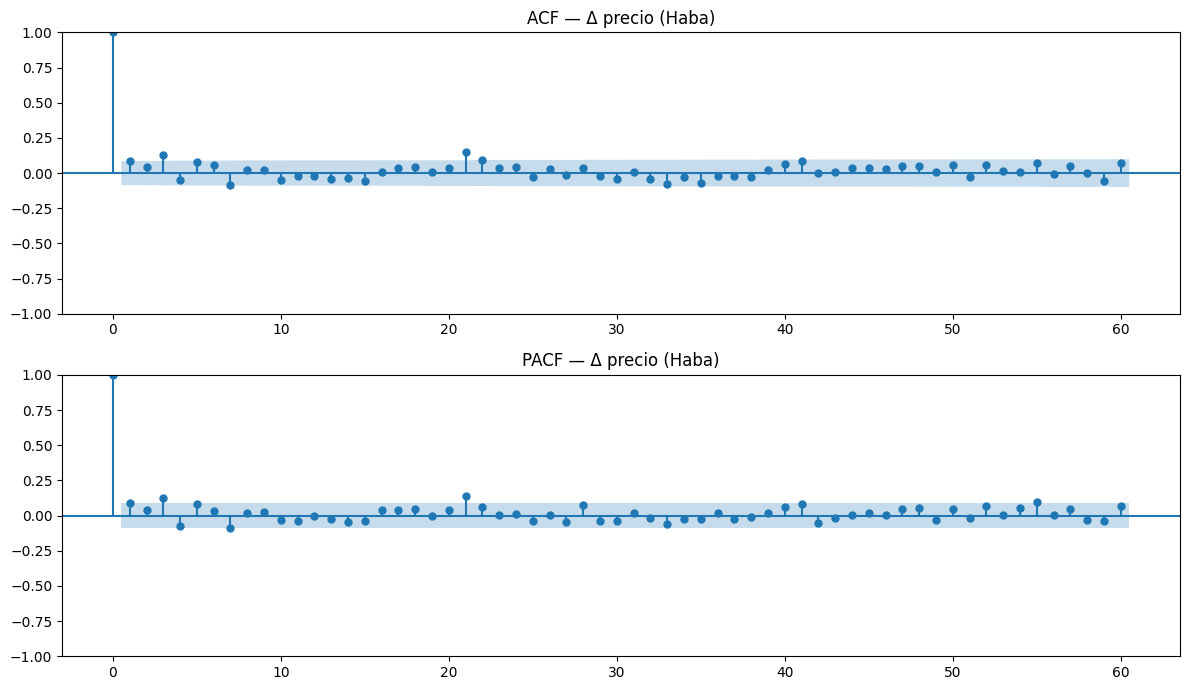

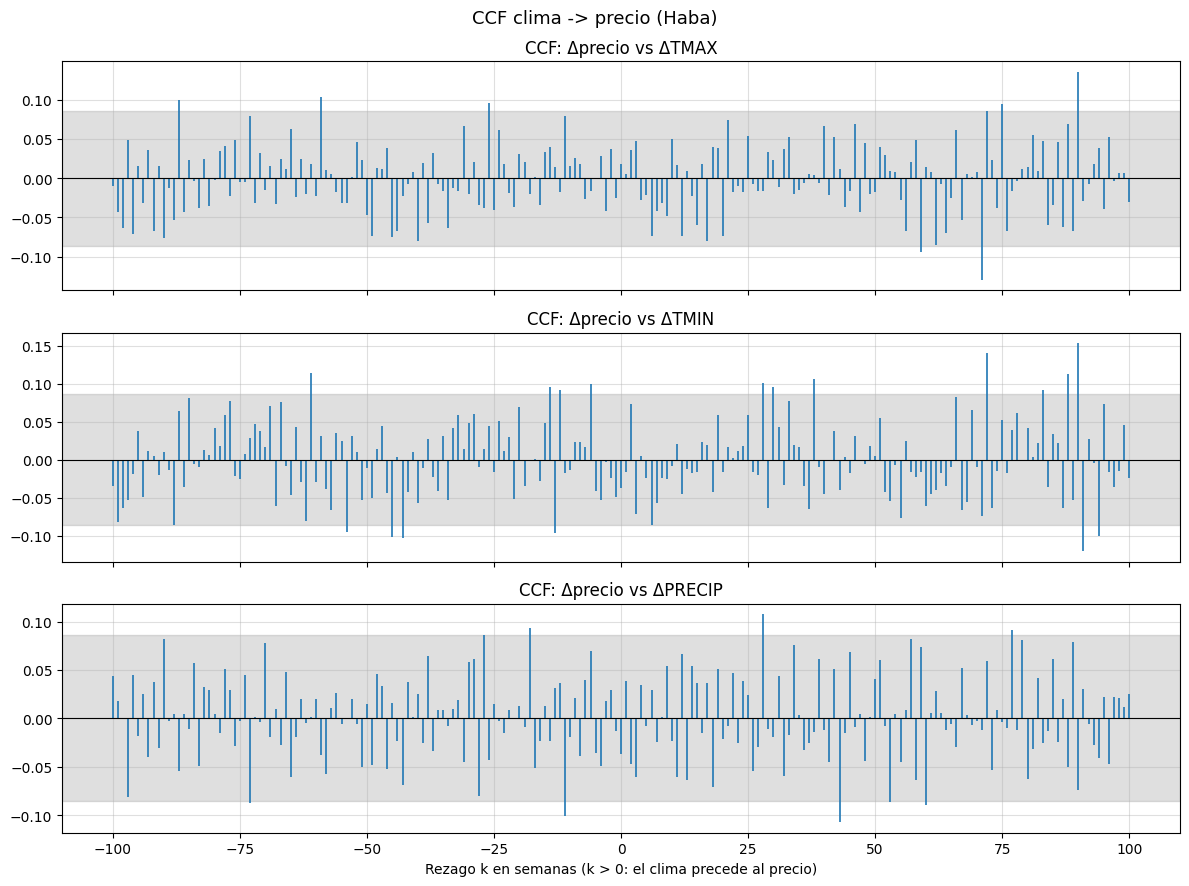

Rezagos k = 1..100 fuera de la banda del 95 % (se esperan ~5 por azar):
TMAX      4
TMIN      9
PRECIP    5
Maíz blanco: 574 semanas | clima: 56 estaciones (mín 37, máx 56 por semana)
  Precio: 22 semanas imputadas de 574


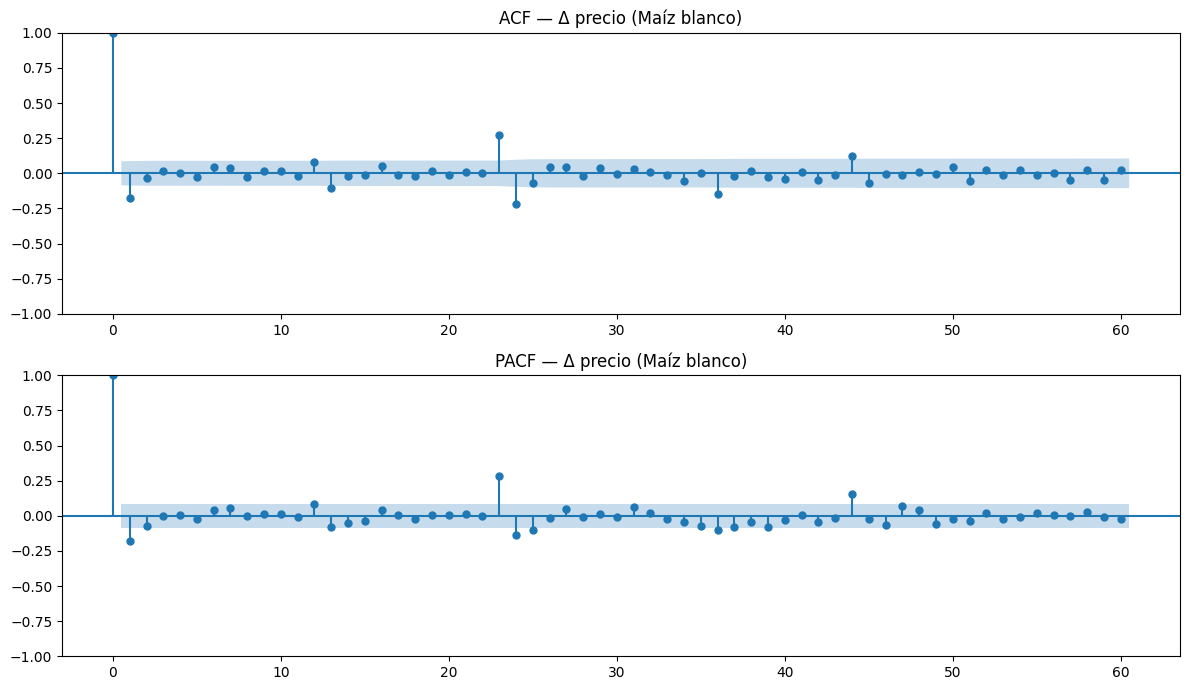

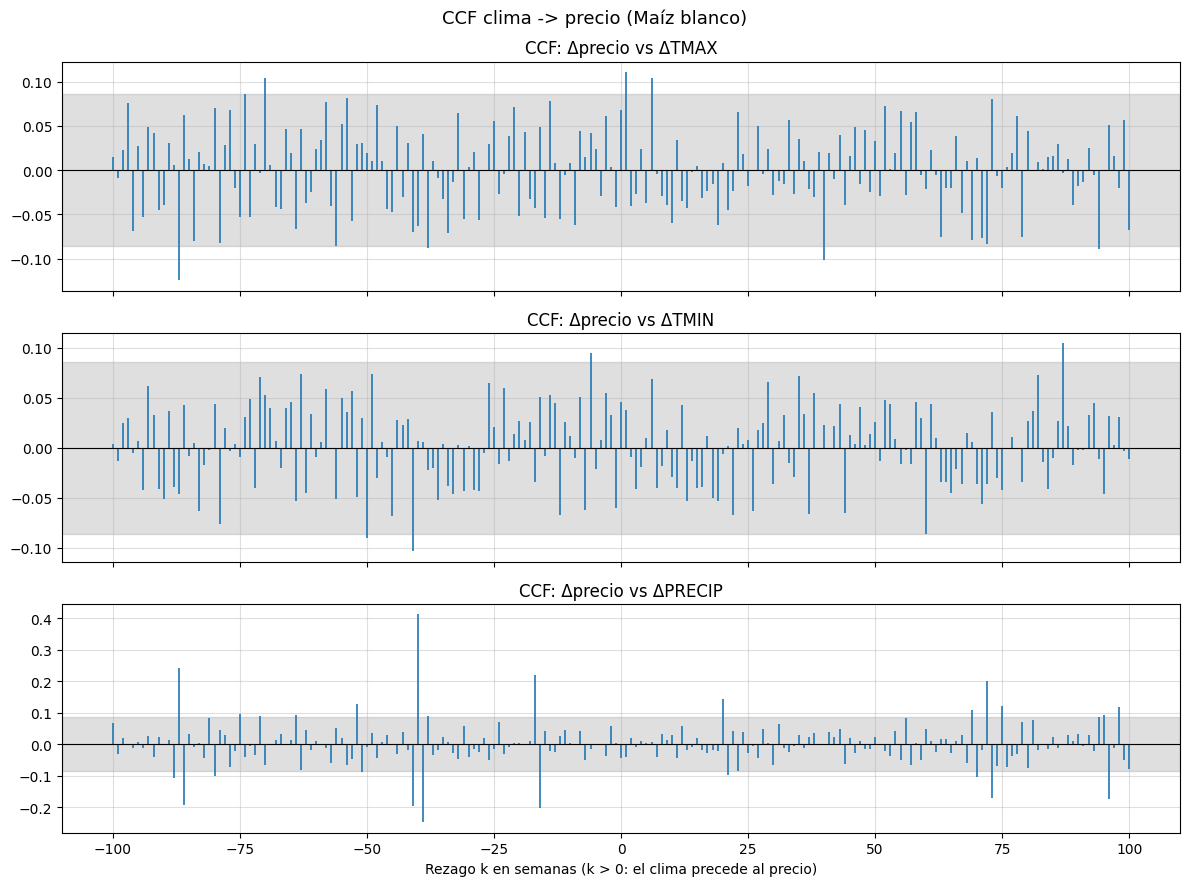

Rezagos k = 1..100 fuera de la banda del 95 % (se esperan ~5 por azar):
TMAX       4
TMIN       2
PRECIP    11
Frijol Pinto: 574 semanas | clima: 19 estaciones (mín 11, máx 19 por semana)
  Precio: 19 semanas imputadas de 574


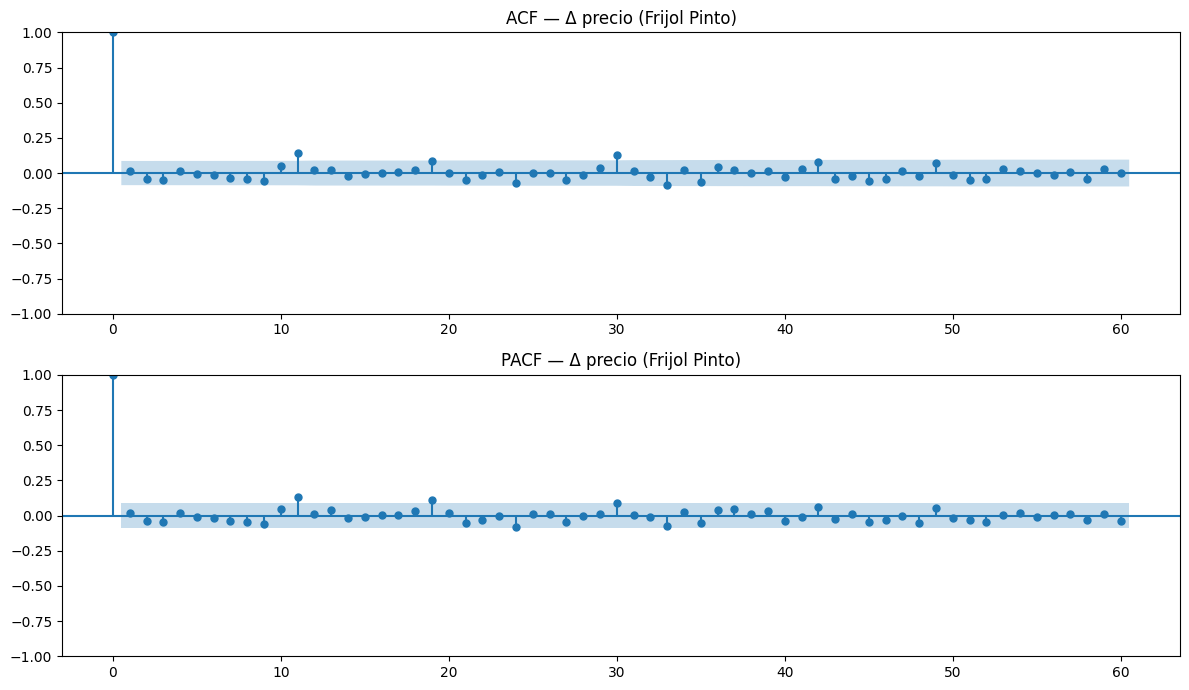

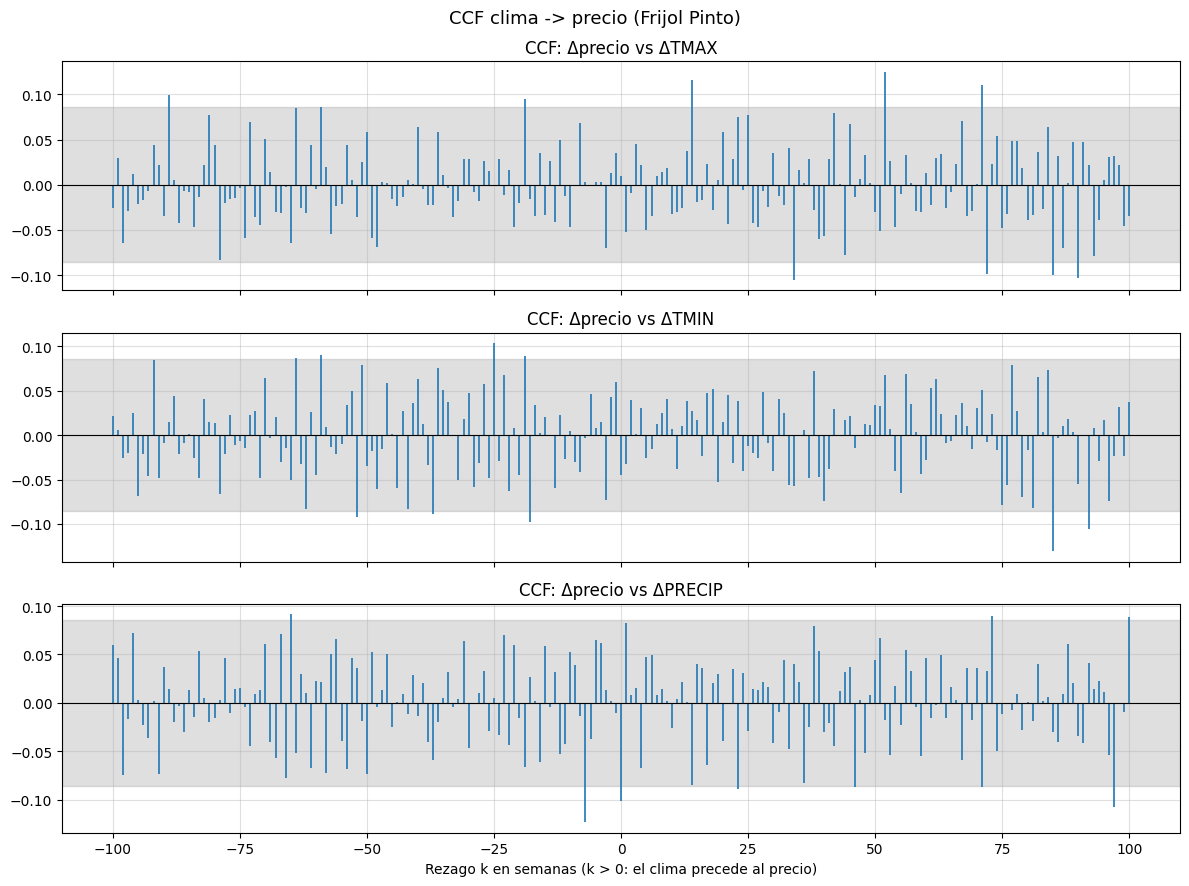

Rezagos k = 1..100 fuera de la banda del 95 % (se esperan ~5 por azar):
TMAX      7
TMIN      2
PRECIP    6
Aguacate Hass - Primera: 574 semanas | clima: 2 estaciones (mín 1, máx 2 por semana)
  Precio: 14 semanas imputadas de 574


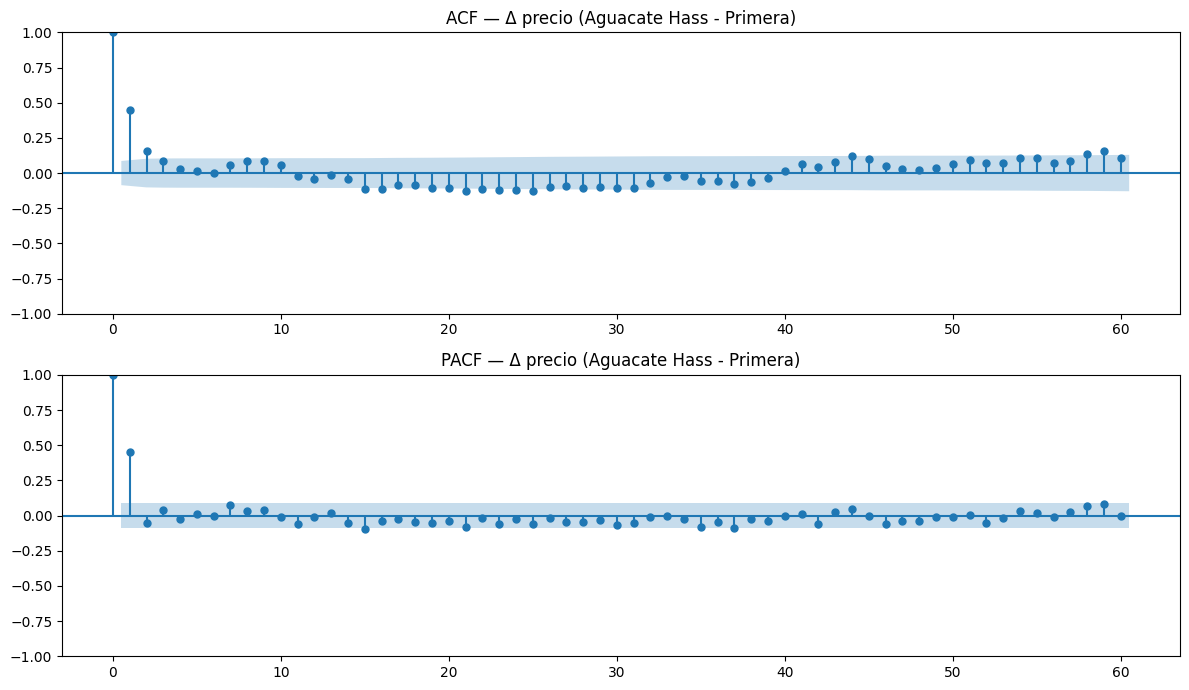

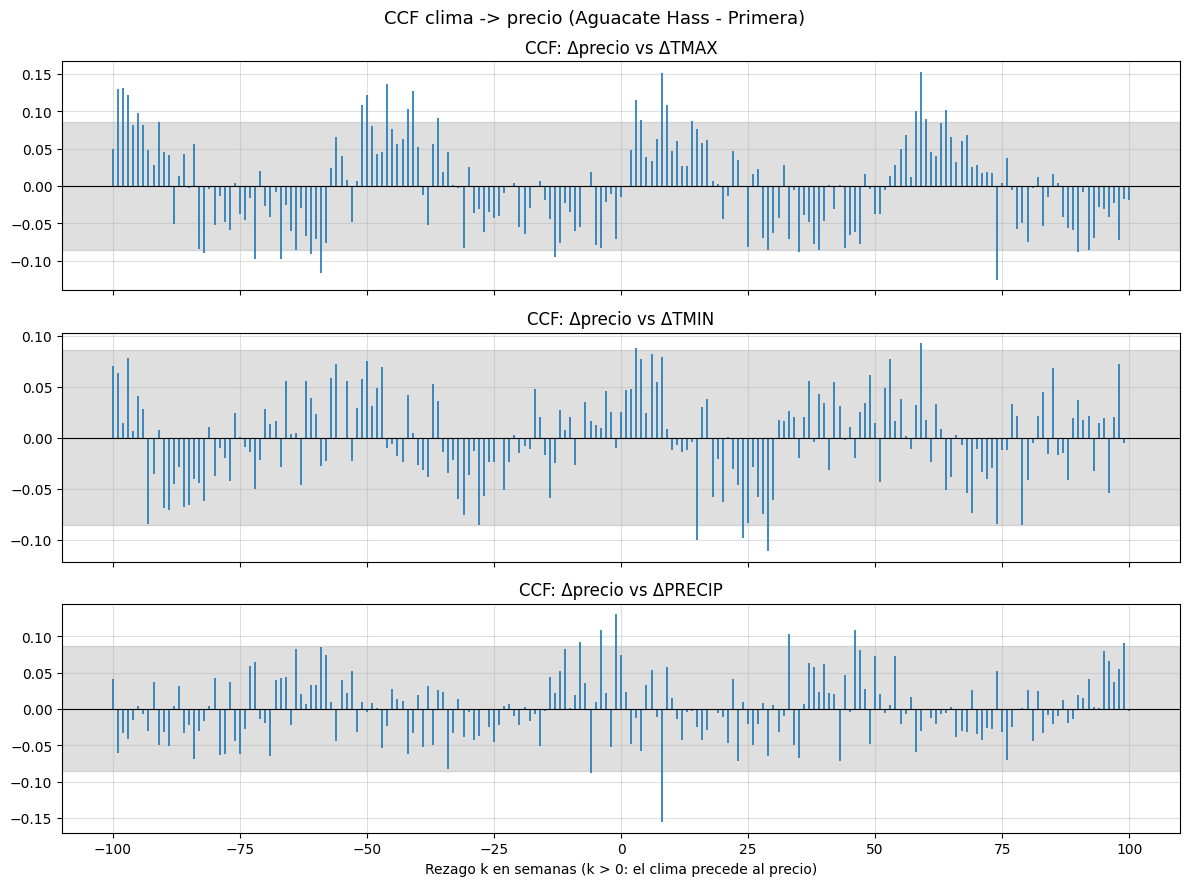

Rezagos k = 1..100 fuera de la banda del 95 % (se esperan ~5 por azar):
TMAX      12
TMIN       5
PRECIP     4
Tomate Saladette - Primera: 574 semanas | clima: 25 estaciones (mín 16, máx 25 por semana)
  Precio: 14 semanas imputadas de 574


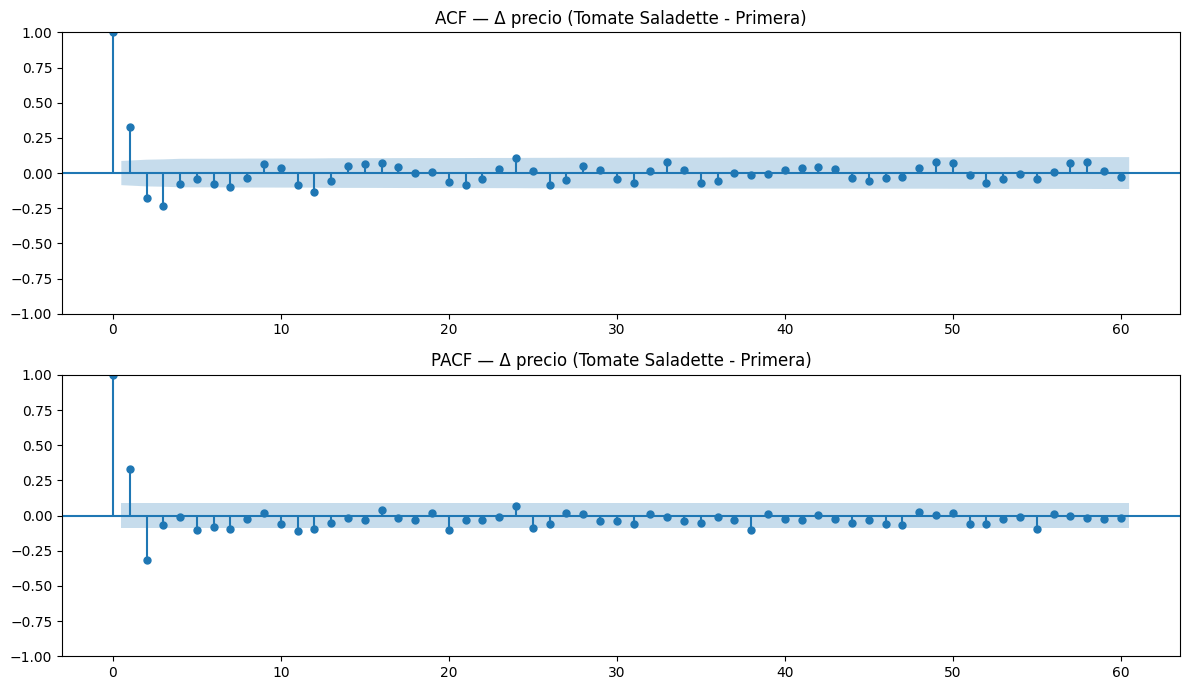

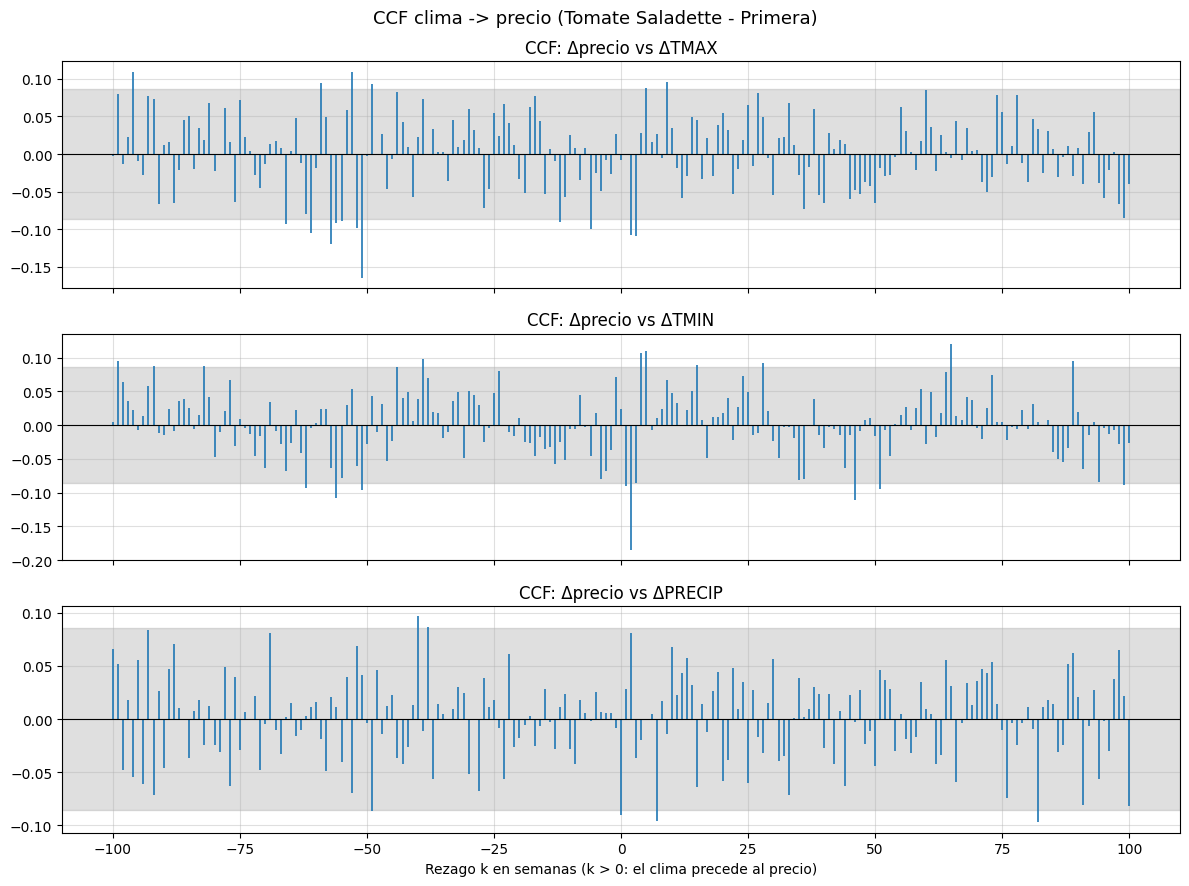

Rezagos k = 1..100 fuera de la banda del 95 % (se esperan ~5 por azar):
TMAX       4
TMIN      12
PRECIP     2


In [54]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX


def graficar_acf_pacf(datos, producto):
    train = entrenamiento(datos)
    d = train['Precio'].diff().dropna()
    lags = max(1, min(60, len(d) // 2 - 1))
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7))
    plot_acf(d, lags=lags, ax=ax1, title=f'ACF — Δ precio ({producto})')
    plot_pacf(d, lags=lags, ax=ax2, title=f'PACF — Δ precio ({producto})')
    fig.tight_layout()
    plt.savefig(os.path.join(CARPETA_RESULTADOS_MODELADO, f'acf_pacf_{slug(producto)}.png'), dpi=200)
    plt.show()


def calcular_ccf(datos, max_lag=MAX_LAG):
    """corr(Δprecio_t, Δclima_(t-k)). k > 0: el clima precede al precio k semanas."""
    train = entrenamiento(datos)
    dy = train['Precio'].diff()
    ccf = pd.DataFrame({v: {k: dy.corr(train[v].diff().shift(k)) for k in range(-max_lag, max_lag + 1)}
                        for v in VARIABLES_CLIMA})
    banda = 1.96 / np.sqrt(dy.notna().sum())
    return ccf, banda


def graficar_ccf(ccf, banda, producto):
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    for ax, v in zip(axes, VARIABLES_CLIMA):
        ax.vlines(ccf.index, 0, ccf[v], color='#1f77b4', lw=1.2)
        ax.axhspan(-banda, banda, color='gray', alpha=0.25)
        ax.axhline(0, color='black', lw=0.8)
        ax.set_title(f'CCF: Δprecio vs Δ{v}')
        ax.grid(alpha=0.4)
    axes[-1].set_xlabel('Rezago k en semanas (k > 0: el clima precede al precio)')
    fig.suptitle(f'CCF clima -> precio ({producto})', fontsize=13)
    fig.tight_layout()
    plt.savefig(os.path.join(CARPETA_RESULTADOS_MODELADO, f'ccf_{slug(producto)}.png'), dpi=200)
    plt.show()
    positivos = ccf.loc[1:]
    fuera = (positivos.abs() > banda).sum()
    print(f"Rezagos k = 1..{positivos.index.max()} fuera de la banda del 95 % "
          f"(se esperan ~{0.05 * len(positivos):.0f} por azar):")
    print(fuera.to_string())


datos_por_producto = {}
for producto in PRODUCTOS_MODELADO:
    con_clima = producto in PRODUCTOS_CON_CLIMA
    datos_por_producto[producto] = preparar_datos_modelado(producto, con_clima)
    graficar_acf_pacf(datos_por_producto[producto], producto)
    if con_clima:
        ccf, banda = calcular_ccf(datos_por_producto[producto])
        graficar_ccf(ccf, banda, producto)
    else:
        print(f"{producto}: sin CCF — {DETALLE_CLIMA.get(producto, 'sin clima')}.\n")

### 5.8 Selección de orden, rezago climático, SARIMAX y comparación de pronósticos

In [55]:
TABLAS_METRICAS_5, PRONOSTICOS_5, PARAMETROS_5 = {}, {}, {}   # los llena pipeline_cultivo; los usan el Koyck (5.10) y el STL (5.12)


def seleccionar_orden(y, d=1, D=D_ESTACIONAL, s=S_ESTACIONAL, p_max=2, q_max=2, P_max=1, Q_max=1):
    mejor, filas = None, []
    for p, q, P, Q in itertools.product(range(p_max + 1), range(q_max + 1), range(P_max + 1), range(Q_max + 1)):
        try:
            r = SARIMAX(y, order=(p, d, q), seasonal_order=(P, D, Q, s),
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        except Exception:
            continue
        filas.append({'Orden': (p, d, q), 'Estacional': (P, D, Q, s), 'AIC': r.aic})
        if mejor is None or r.aic < mejor[2]:
            mejor = ((p, d, q), (P, D, Q, s), r.aic)
    return mejor, pd.DataFrame(filas).sort_values('AIC').reset_index(drop=True)


def buscar_rezago(datos, orden, orden_est, max_lag=MAX_LAG, paso=PASO_LAG):
    """AIC del SARIMAX para cada rezago k, siempre sobre la misma muestra de entrenamiento."""
    muestra = entrenamiento(datos).iloc[max_lag:]
    filas = []
    for k in range(0, max_lag + 1, paso):
        X = datos[VARIABLES_CLIMA].shift(k).loc[muestra.index]
        try:
            r = SARIMAX(muestra['Precio'], exog=X, order=orden, seasonal_order=orden_est,
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        except Exception:
            continue
        fila = {'Rezago': k, 'AIC': r.aic}
        fila.update({f'p_{v}': r.pvalues[v] for v in VARIABLES_CLIMA})
        filas.append(fila)
    aic_sarima = SARIMAX(muestra['Precio'], order=orden, seasonal_order=orden_est,
                         enforce_stationarity=False, enforce_invertibility=False).fit(disp=False).aic
    return pd.DataFrame(filas), aic_sarima


def graficar_rezagos(tabla, aic_sarima, producto):
    k_opt = int(tabla.loc[tabla['AIC'].idxmin(), 'Rezago'])
    plt.figure(figsize=(12, 5))
    plt.plot(tabla['Rezago'], tabla['AIC'], marker='o', markersize=3, color='#2ca02c',
             label='SARIMAX con clima desfasado k semanas')
    plt.axhline(aic_sarima, color='gray', linestyle=':', label='SARIMA sin clima (misma muestra)')
    plt.axvline(k_opt, color='red', linestyle='--', alpha=0.7, label=f'Mínimo AIC: k = {k_opt}')
    plt.xlabel('Rezago del clima (semanas)')
    plt.ylabel('AIC')
    plt.title(f'AIC por rezago climático — {producto}')
    plt.legend()
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_RESULTADOS_MODELADO, f'aic_rezagos_{slug(producto)}.png'), dpi=200)
    plt.show()
    return k_opt


def ajustar_modelos(datos, orden, orden_est, con_clima, k=None, max_lag=MAX_LAG):
    muestra = entrenamiento(datos).iloc[max_lag:] if con_clima else entrenamiento(datos)
    sarima = SARIMAX(muestra['Precio'], order=orden, seasonal_order=orden_est,
                     enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    sarimax = None
    if con_clima:
        X = datos[VARIABLES_CLIMA].shift(k).loc[muestra.index]
        sarimax = SARIMAX(muestra['Precio'], exog=X, order=orden, seasonal_order=orden_est,
                          enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return sarima, sarimax


def ljung_box(modelo, orden, orden_est):
    inicio = orden[1] + orden_est[1] * orden_est[3]
    resid = modelo.resid.iloc[inicio:]
    lags = [l for l in (10, 52) if l < len(resid)]
    if not lags:
        return pd.Series(dtype=float)
    return acorr_ljungbox(resid, lags=lags)['lb_pvalue']


def exogenas_prueba(datos, k):
    """Clima desfasado para el año de prueba: observado si ya se conocía al cierre del
    entrenamiento; si no, climatología."""
    clima = datos[VARIABLES_CLIMA]
    test_idx = prueba(datos).index
    origen = entrenamiento(datos).index[-1]
    clim = climatologia(clima)
    filas, conocidas = [], 0
    for t in test_idx:
        fuente = t - pd.Timedelta(weeks=k)
        if fuente <= origen:
            filas.append(clima.loc[fuente].values)
            conocidas += 1
        else:
            filas.append(clim.loc[int(SEMANA_DEL_ANIO([fuente])[0])].values)
    X_real = pd.DataFrame(filas, index=test_idx, columns=VARIABLES_CLIMA)
    X_obs = clima.shift(k).loc[test_idx]
    return X_real, X_obs, conocidas


def metricas(y, f):
    e = np.asarray(y, dtype=float) - np.asarray(f, dtype=float)
    return {'RMSE': float(np.sqrt(np.mean(e ** 2))), 'MAE': float(np.mean(np.abs(e))),
            'MAPE (%)': float(100 * np.mean(np.abs(e / y)))}


def pronosticar(datos, sarima, sarimax, con_clima, k, producto, graficar=True):
    train, test = entrenamiento(datos), prueba(datos)
    h = len(test)
    pron = pd.DataFrame(index=test.index)
    pron['SARIMA (sin clima)'] = sarima.get_forecast(h).predicted_mean.values
    conocidas = None
    if con_clima:
        X_real, X_obs, conocidas = exogenas_prueba(datos, k)
        f_sarimax = sarimax.get_forecast(h, exog=X_real)
        pron['SARIMAX'] = f_sarimax.predicted_mean.values
        pron['SARIMAX con clima observado (referencia)'] = sarimax.get_forecast(h, exog=X_obs).predicted_mean.values
    pron['Ingenuo (último valor)'] = train['Precio'].iloc[-1]
    if len(datos) > 52:
        pron['Ingenuo estacional (52 semanas antes)'] = datos['Precio'].shift(52).loc[test.index].values
    obs = test['Observado'].values.astype(bool)
    y = test['Precio'].values[obs]
    if obs.sum() > 0:
        tabla = pd.DataFrame({c: metricas(y, pron[c].values[obs]) for c in pron.columns}).T.round(3)
    else:
        tabla = pd.DataFrame(columns=['RMSE', 'MAE', 'MAPE (%)'])
    print(f"{producto}: semanas de prueba {h} ({int(obs.sum())} con cotización real)."
          + (f" Clima conocido al cierre de {ANIO_PRUEBA - 1}: {conocidas} de {h}." if con_clima else ""))
    if graficar and obs.sum() > 0:
        plt.figure(figsize=(12, 5))
        plt.plot(train.index[-104:], train['Precio'].iloc[-104:], color='black', label='Histórico (2 años)')
        plt.plot(test.index[obs], y, color='blue', marker='o', markersize=4, label=f'Observado {ANIO_PRUEBA}')
        if con_clima:
            plt.plot(test.index, pron['SARIMAX'], color='green', linestyle='--', label='SARIMAX')
        plt.plot(test.index, pron['SARIMA (sin clima)'], color='purple', linestyle=':', label='SARIMA sin clima')
        plt.title(f'Validación {ANIO_PRUEBA}: {producto}')
        plt.legend()
        plt.grid(alpha=0.4)
        plt.tight_layout()
        plt.savefig(os.path.join(CARPETA_RESULTADOS_MODELADO, f'validacion_{ANIO_PRUEBA}_{slug(producto)}.png'), dpi=200)
        plt.show()
    return pron, tabla


def pipeline_cultivo(producto, con_clima, graficar=True, verbose=True):
    """Ejecuta el procedimiento completo (orden SARIMA, rezago climático si aplica, SARIMAX,
    pronóstico) para un producto y regresa un resumen comparable entre productos."""
    datos = datos_por_producto[producto]
    train = entrenamiento(datos)
    inicio_muestra = MAX_LAG if con_clima else 0
    (orden, orden_est, _), _ = seleccionar_orden(train['Precio'].iloc[inicio_muestra:])
    k = None
    if con_clima:
        tabla_lags, aic_sarima = buscar_rezago(datos, orden, orden_est)
        tabla_lags.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, f'aic_rezagos_{slug(producto)}.csv'), index=False)
        k = graficar_rezagos(tabla_lags, aic_sarima, producto) if graficar else int(tabla_lags.loc[tabla_lags['AIC'].idxmin(), 'Rezago'])
    sarima, sarimax = ajustar_modelos(datos, orden, orden_est, con_clima, k)
    lb = ljung_box(sarimax if con_clima else sarima, orden, orden_est)
    pron, tabla = pronosticar(datos, sarima, sarimax, con_clima, k, producto, graficar)
    tabla.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, f'metricas_{ANIO_PRUEBA}_{slug(producto)}.csv'))
    TABLAS_METRICAS_5[producto], PRONOSTICOS_5[producto] = tabla, pron
    PARAMETROS_5[producto] = {'k': k, 'orden': orden, 'orden_est': orden_est}
    sarima.save(os.path.join(CARPETA_RESULTADOS_MODELADO, f'modelo_sarima_{slug(producto)}.pkl'))
    if con_clima:
        sarimax.save(os.path.join(CARPETA_RESULTADOS_MODELADO, f'modelo_sarimax_{slug(producto)}.pkl'))
    if verbose:
        print(f"{producto}: orden {orden} x {orden_est}" + (f" | rezago óptimo: {k} semanas" if con_clima else " | sin clima"))
        display(tabla)
    resumen = {
        'Producto': producto,
        'Con clima': con_clima,
        'Orden': str(orden),
        'Estacional': str(orden_est),
        'Rezago óptimo (semanas)': k,
        'AIC SARIMA': round(sarima.aic, 2),
        'AIC SARIMAX': round(sarimax.aic, 2) if con_clima else None,
        'ΔAIC (SARIMA − SARIMAX)': round(sarima.aic - sarimax.aic, 2) if con_clima else None,
        'Ljung-Box p (10)': round(lb.get(10), 3) if (len(lb) and 10 in lb.index) else None,
        'Ljung-Box p (52)': round(lb.get(52), 3) if (len(lb) and 52 in lb.index) else None,
        'RMSE SARIMA': tabla.loc['SARIMA (sin clima)', 'RMSE'] if 'SARIMA (sin clima)' in tabla.index else None,
        'RMSE SARIMAX': tabla.loc['SARIMAX', 'RMSE'] if 'SARIMAX' in tabla.index else None,
        'MAPE SARIMA (%)': tabla.loc['SARIMA (sin clima)', 'MAPE (%)'] if 'SARIMA (sin clima)' in tabla.index else None,
        'MAPE SARIMAX (%)': tabla.loc['SARIMAX', 'MAPE (%)'] if 'SARIMAX' in tabla.index else None,
        'RMSE ingenuo': tabla.loc['Ingenuo (último valor)', 'RMSE'] if 'Ingenuo (último valor)' in tabla.index else None,
    }
    return resumen

### 5.9 Ejecución y comparación de los 5 productos

HABA (con clima)


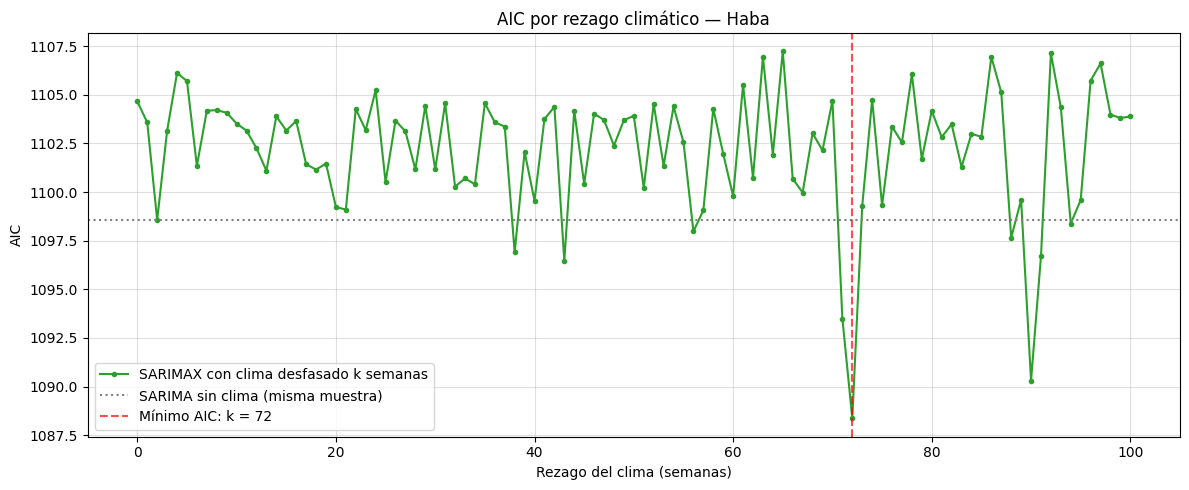

Haba: semanas de prueba 53 (53 con cotización real). Clima conocido al cierre de 2024: 53 de 53.


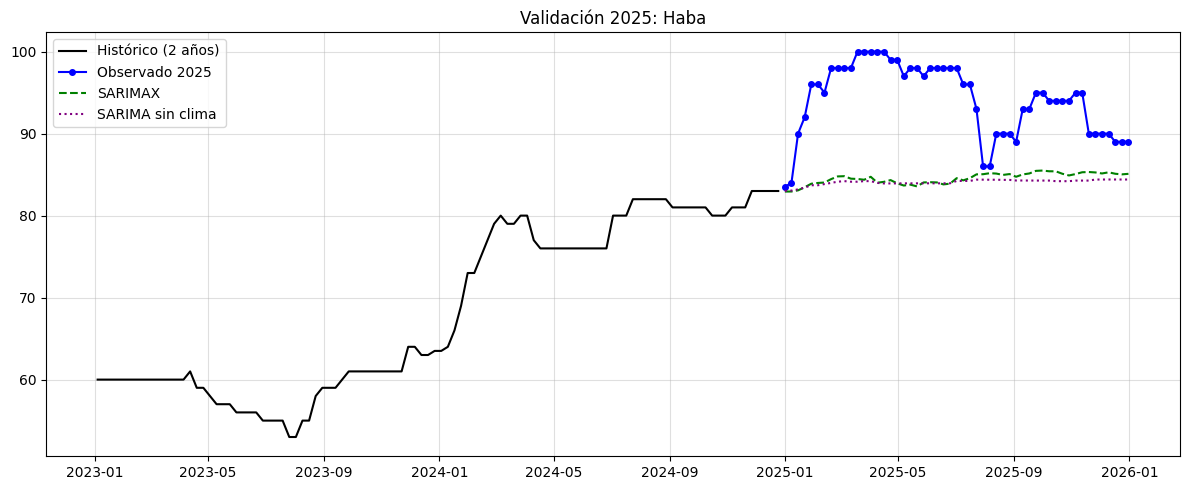

Haba: orden (1, 1, 2) x (0, 0, 1, 52) | rezago óptimo: 72 semanas


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),11.003,10.093,10.518
SARIMAX,10.652,9.637,10.027
SARIMAX con clima observado (referencia),10.652,9.637,10.027
Ingenuo (último valor),12.006,11.179,11.673
Ingenuo estacional (52 semanas antes),17.070,15.877,16.683


MAÍZ BLANCO (con clima)


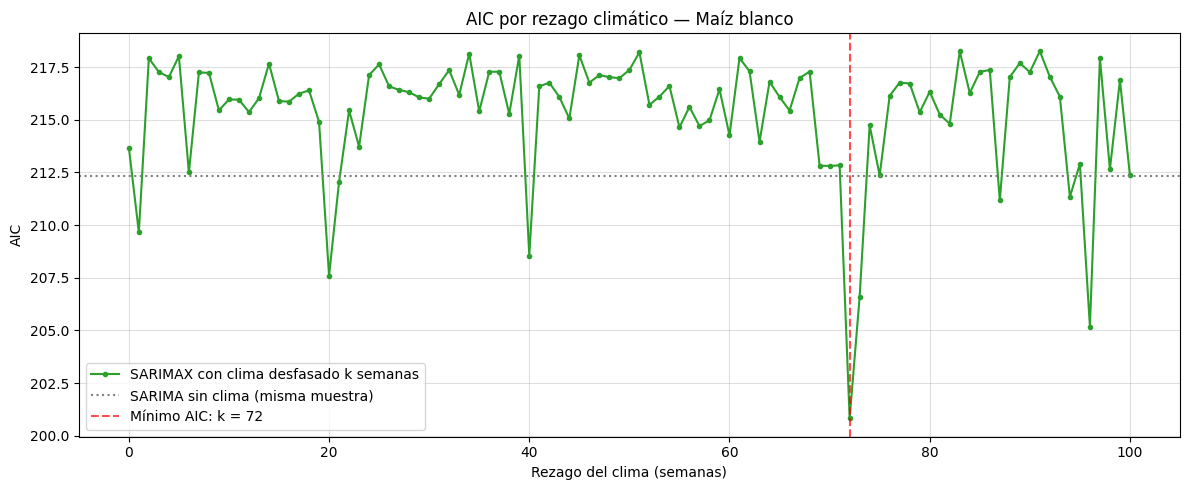

Maíz blanco: semanas de prueba 53 (52 con cotización real). Clima conocido al cierre de 2024: 53 de 53.


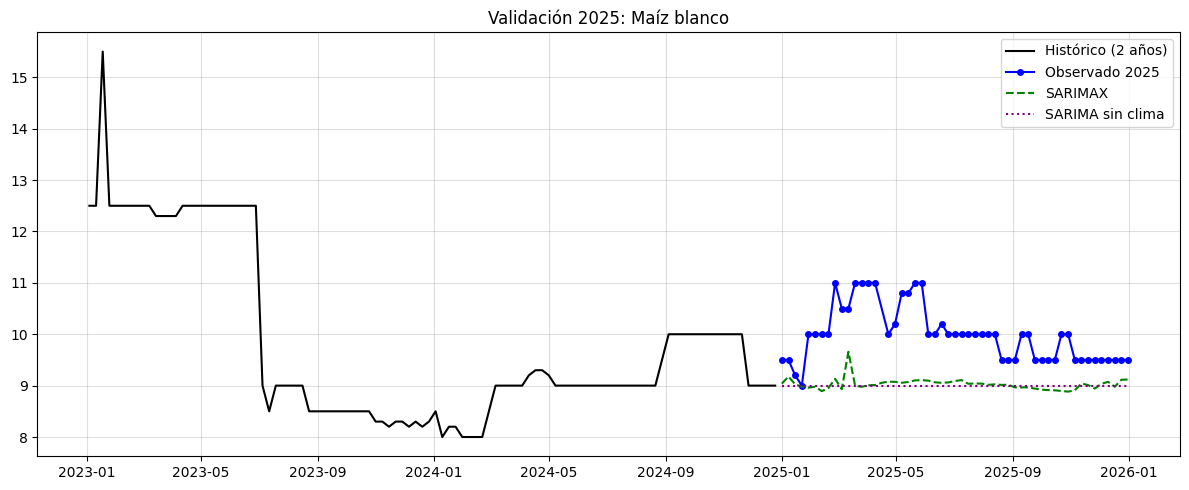

Maíz blanco: orden (0, 1, 1) x (0, 0, 0, 52) | rezago óptimo: 72 semanas


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),1.121,0.984,9.605
SARIMAX,1.090,0.957,9.340
SARIMAX con clima observado (referencia),1.090,0.957,9.340
Ingenuo (último valor),1.121,0.985,9.608
Ingenuo estacional (52 semanas antes),1.223,1.021,10.004


FRIJOL PINTO (con clima)


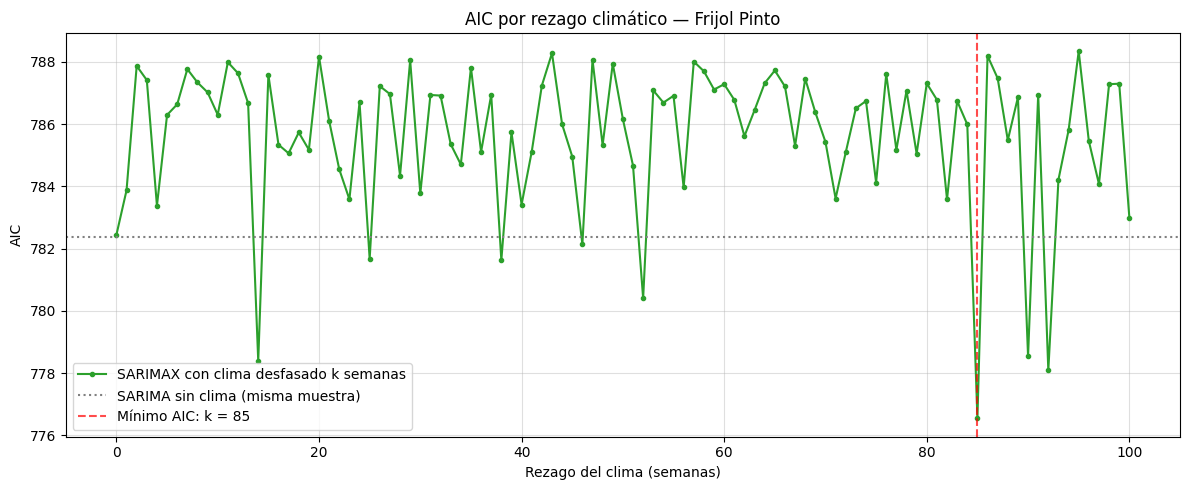

Frijol Pinto: semanas de prueba 53 (53 con cotización real). Clima conocido al cierre de 2024: 53 de 53.


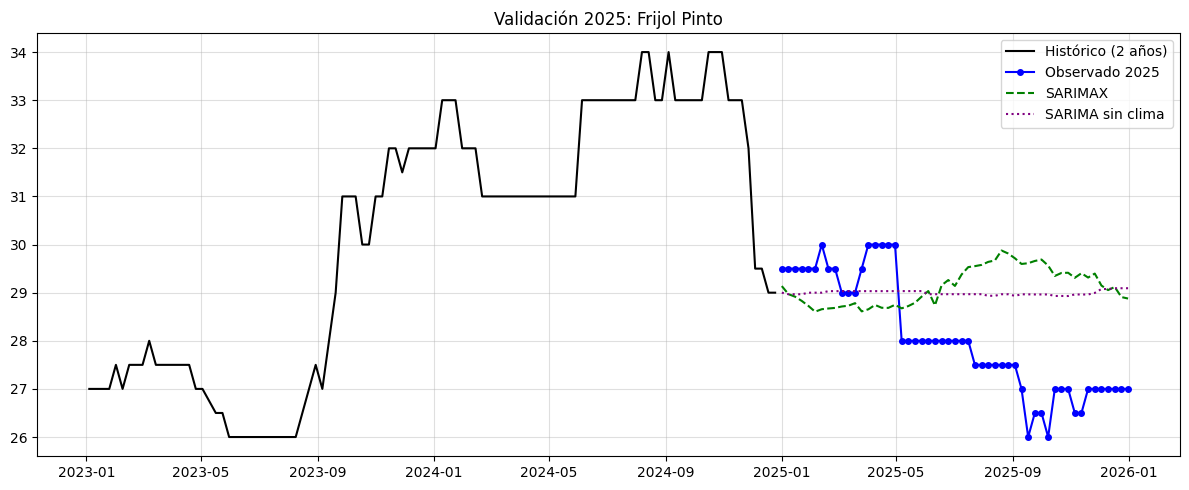

Frijol Pinto: orden (0, 1, 0) x (0, 0, 1, 52) | rezago óptimo: 85 semanas


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),1.505,1.310,4.774
SARIMAX,1.838,1.612,5.863
SARIMAX con clima observado (referencia),1.838,1.612,5.863
Ingenuo (último valor),1.517,1.321,4.812
Ingenuo estacional (52 semanas antes),4.514,4.028,14.610


AGUACATE HASS - PRIMERA (con clima)


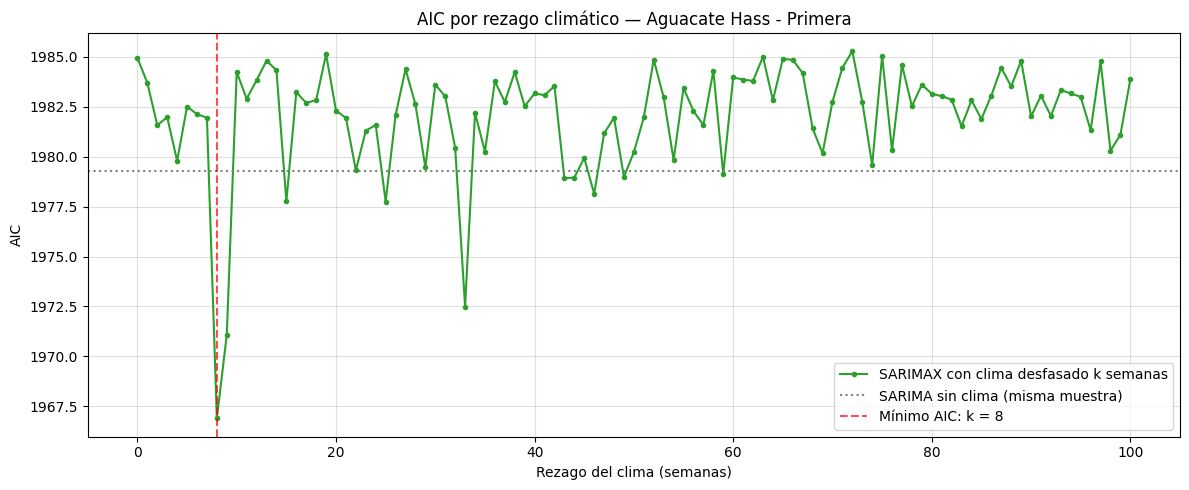

Aguacate Hass - Primera: semanas de prueba 53 (53 con cotización real). Clima conocido al cierre de 2024: 8 de 53.


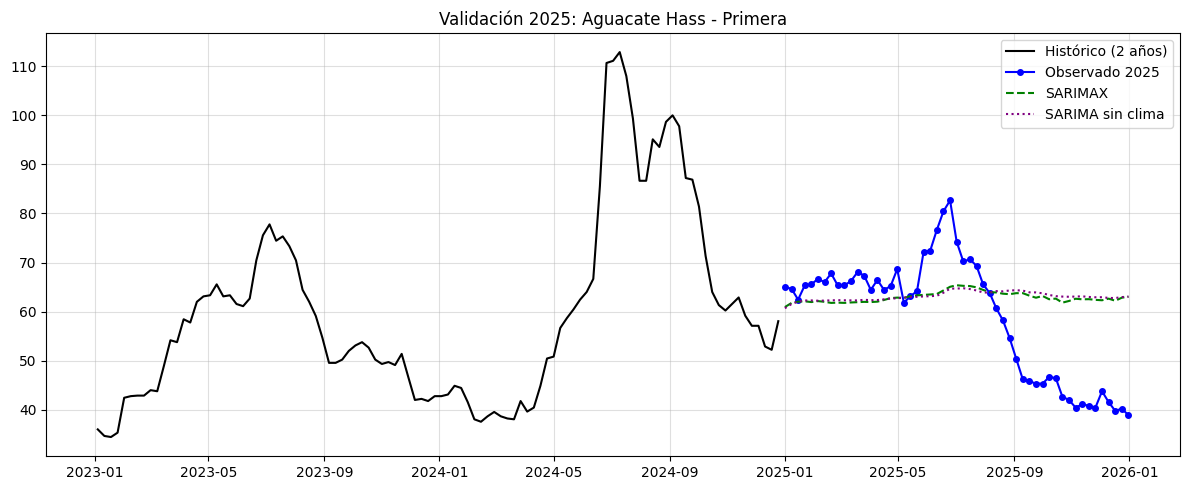

Aguacate Hass - Primera: orden (1, 1, 2) x (0, 0, 1, 52) | rezago óptimo: 8 semanas


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),12.984,10.233,20.908
SARIMAX,12.637,9.980,20.379
SARIMAX con clima observado (referencia),12.995,10.246,20.940
Ingenuo (último valor),12.285,11.090,20.582
Ingenuo estacional (52 semanas antes),26.449,23.942,42.784


TOMATE SALADETTE - PRIMERA (con clima)


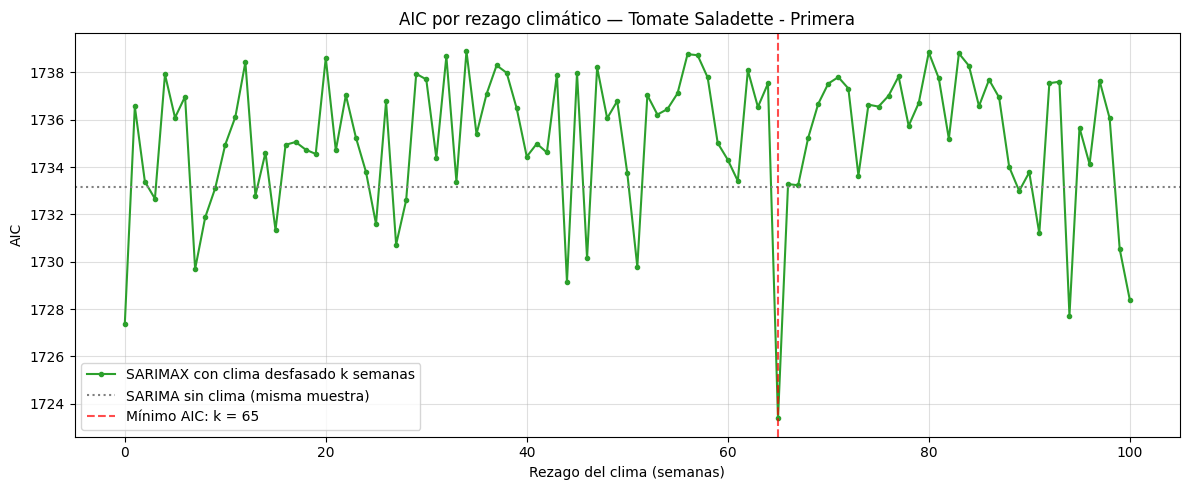

Tomate Saladette - Primera: semanas de prueba 53 (53 con cotización real). Clima conocido al cierre de 2024: 53 de 53.


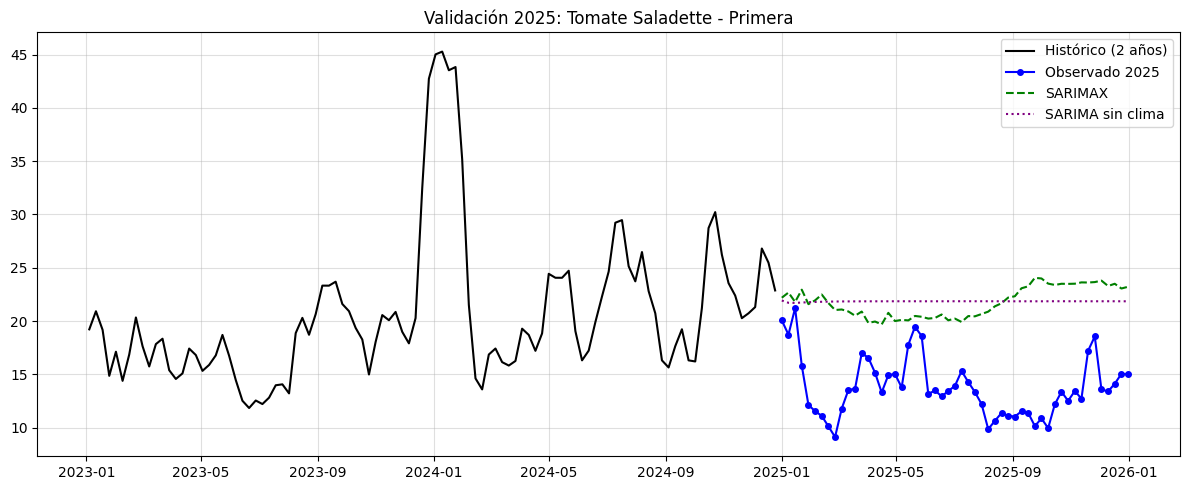

Tomate Saladette - Primera: orden (2, 1, 2) x (1, 0, 1, 52) | rezago óptimo: 65 semanas


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),8.521,8.046,64.550
SARIMAX,8.643,7.974,64.391
SARIMAX con clima observado (referencia),8.643,7.974,64.391
Ingenuo (último valor),9.495,9.073,72.285
Ingenuo estacional (52 semanas antes),11.421,9.336,69.189


,Producto,Con clima,Orden,Estacional,Rezago óptimo (semanas),AIC SARIMA,AIC SARIMAX,ΔAIC (SARIMA − SARIMAX),Ljung-Box p (10),Ljung-Box p (52),RMSE SARIMA,RMSE SARIMAX,MAPE SARIMA (%),MAPE SARIMAX (%),RMSE ingenuo
0,Haba,True,"(1, 1, 2)","(0, 0, 1, 52)",72,1098.58,1088.37,10.22,0.135,0.386,11.003,10.652,10.518,10.027,12.006
1,Maíz blanco,True,"(0, 1, 1)","(0, 0, 0, 52)",72,212.33,200.83,11.51,0.978,0.004,1.121,1.090,9.605,9.340,1.121
2,Frijol Pinto,True,"(0, 1, 0)","(0, 0, 1, 52)",85,782.36,776.55,5.81,0.741,0.340,1.505,1.838,4.774,5.863,1.517
3,Aguacate Hass - Primera,True,"(1, 1, 2)","(0, 0, 1, 52)",8,1979.31,1966.89,12.42,0.550,0.739,12.984,12.637,20.908,20.379,12.285
4,Tomate Saladette - Primera,True,"(2, 1, 2)","(1, 0, 1, 52)",65,1733.15,1723.38,9.77,0.481,0.286,8.521,8.643,64.550,64.391,9.495


In [56]:
resumenes_5 = []
for producto in PRODUCTOS_MODELADO:
    con_clima = producto in PRODUCTOS_CON_CLIMA
    print('=' * 70)
    print(f"{producto.upper()} {'(con clima)' if con_clima else '(sin clima: ' + DETALLE_CLIMA.get(producto, '') + ')'}")
    print('=' * 70)
    resumenes_5.append(pipeline_cultivo(producto, con_clima))

tabla_resumen_5 = pd.DataFrame(resumenes_5)
tabla_resumen_5.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, 'tabla_resumen_5_productos.csv'), index=False)
display(tabla_resumen_5)

### 5.10 Modelo de Koyck (rezagos distribuidos geométricos)

El SARIMAX de arriba usa el clima desfasado **un solo** rezago `k`. El modelo de Koyck supone en cambio que el efecto del clima se reparte en todos los rezagos y **se desvanece geométricamente**:

$$y_t = \alpha + \sum_{j} \beta_j \sum_{i=0}^{\infty} \lambda^{i}\, x_{j,t-i} + u_t, \qquad 0 \le \lambda < 1$$

con un solo parámetro de decaimiento `λ` común a TMAX, TMIN y PRECIP: el clima de hace `i` semanas pesa `λ^i` veces lo que pesa el de esta semana.

**Transformación de Koyck.** Restando `λ·y_(t-1)` se obtiene la forma que aparece en los libros: `y_t = α(1−λ) + λ·y_(t-1) + Σ β_j·x_(j,t) + v_t`, con `v_t = u_t − λ·u_(t-1)`. El error `v_t` está correlacionado con `y_(t-1)`, así que **MCO sobre esa ecuación es inconsistente**: el sesgo de `λ̂` va hacia abajo si `u_t` es ruido blanco y puede ir hacia arriba si `u_t` es muy persistente. Por eso aquí se estima la forma geométrica original por mínimos cuadrados no lineales: para cada `λ` se construye `z_(j,t) = x_(j,t) + λ·z_(j,t-1)`, se regresa `y` sobre las `z` y se elige el `λ` de menor suma de cuadrados (rejilla de 0.01 y refinamiento). Como las `z` dependen solo del clima, no hay regresor correlacionado con el error; si `u_t` es ruido blanco, esto es la máxima verosimilitud gaussiana del modelo original. La estimación MCO de la ecuación transformada se reporta solo como referencia, para ver el sesgo.

**Dos versiones.** `niveles` modela `y_t` (la versión de los libros). `diferencias` modela `Δy_t` con `Δx`, igual que el SARIMA con d = 1 de la sección 5.4: sin constante (sin deriva) y con el pronóstico del nivel acumulando los cambios desde el último precio de entrenamiento. Con precios cercanos a I(1) la versión en niveles puede dar relaciones espurias; por eso se corren las dos y se comparan.

**Cantidades derivadas.** Multiplicador de corto plazo `β_j`; de largo plazo `β_j / (1 − λ)`; rezago medio `λ / (1 − λ)` semanas; rezago mediano `−ln 2 / ln λ` semanas (cuándo se acumula la mitad del efecto total). Las desviaciones estándar de `β_j` son HAC y condicionales a `λ̂`; el intervalo de `λ` sale de la razón de verosimilitud del perfil y es aproximado si los residuos tienen autocorrelación (se reporta Ljung-Box).

**Qué compara y qué no.** Solo se estima para productos con clima. El año de prueba se pronostica con el clima desconocido reemplazado por la climatología de entrenamiento (como el SARIMAX para las semanas que aún no se conocían) y, como referencia, con el clima observado. A diferencia del SARIMAX, el Koyck usa el clima de la misma semana (k = 0) con memoria geométrica, así que no ve semanas «ya conocidas» del año de prueba. Los AIC del Koyck y del SARIMAX no son comparables (otra variable dependiente y otra muestra); la comparación es por RMSE / MAE / MAPE en el año de prueba.

In [57]:
from scipy.signal import lfilter
from scipy.optimize import minimize_scalar
import statsmodels.api as sm

LAMBDA_MAX = 0.995
KOYCK_GRILLA = np.unique(np.round(np.append(np.arange(0.0, 1.0, 0.01), LAMBDA_MAX), 3))
FORMAS_KOYCK = {'niveles': 'niveles', 'diferencias': 'Δ'}
TABLAS_KOYCK, PRONOSTICOS_KOYCK = {}, {}


def acumular_koyck(X, lam, x_previo):
    """z_t = x_t + lam * z_(t-1). Antes de la muestra se supone el clima en su media: z_(-1) = x_previo / (1 - lam)."""
    X = np.asarray(X, dtype=float)
    zi = (lam * np.asarray(x_previo, dtype=float) / (1.0 - lam)).reshape(1, -1)
    z, _ = lfilter([1.0], [1.0, -lam], X, axis=0, zi=zi)
    return z


def _koyck_mco_dado_lambda(w, X, lam, x_previo, intercepto):
    Z = acumular_koyck(X, lam, x_previo)
    A = np.column_stack([np.ones(len(w)), Z]) if intercepto else Z
    coef = np.linalg.lstsq(A, w, rcond=None)[0]
    resid = w - A @ coef
    return float(resid @ resid), coef, resid, A


def ajustar_koyck(w, X, intercepto, nombres=VARIABLES_CLIMA):
    """Koyck por mínimos cuadrados no lineales (perfil sobre lambda). w: (n,), X: (n, p)."""
    w, X = np.asarray(w, dtype=float), np.asarray(X, dtype=float)
    n, p = X.shape
    x_previo = X.mean(axis=0)
    ssr_grilla = np.array([_koyck_mco_dado_lambda(w, X, l, x_previo, intercepto)[0] for l in KOYCK_GRILLA])
    i0 = int(np.argmin(ssr_grilla))
    lo, hi = KOYCK_GRILLA[max(i0 - 1, 0)], KOYCK_GRILLA[min(i0 + 1, len(KOYCK_GRILLA) - 1)]
    opt = minimize_scalar(lambda l: _koyck_mco_dado_lambda(w, X, l, x_previo, intercepto)[0],
                          bounds=(lo, hi), method='bounded', options={'xatol': 1e-6})
    lam = float(opt.x) if opt.fun <= ssr_grilla[i0] else float(KOYCK_GRILLA[i0])
    ssr, coef, resid, A = _koyck_mco_dado_lambda(w, X, lam, x_previo, intercepto)
    k_par = A.shape[1] + 2                                   # coeficientes + lambda + varianza
    perfil = pd.DataFrame({'lambda': KOYCK_GRILLA, 'SSR': ssr_grilla,
                           'AIC': n * np.log(ssr_grilla / n) + 2 * k_par})
    dentro = KOYCK_GRILLA[n * np.log(ssr_grilla / ssr) <= 3.841]      # razón de verosimilitud, χ²(1) al 95 %
    ic = (float(dentro.min()), float(dentro.max())) if len(dentro) else (lam, lam)
    etiquetas = (['const'] if intercepto else []) + list(nombres)
    hac = sm.OLS(w, A).fit(cov_type='HAC', cov_kwds={'maxlags': 8})
    return {'lam': lam, 'ic_lam': ic, 'coef': pd.Series(coef, index=etiquetas), 'se': pd.Series(hac.bse, index=etiquetas),
            'pvalor': pd.Series(hac.pvalues, index=etiquetas), 'resid': resid, 'ssr': ssr, 'n': n,
            'x_previo': x_previo, 'intercepto': intercepto, 'nombres': list(nombres), 'perfil': perfil,
            'borde': bool(lam < 0.005 or lam > LAMBDA_MAX - 0.005)}


def koyck_mco_transformada(w, X, intercepto):
    """Referencia: MCO sobre y_t = c + lam*y_(t-1) + X_t b + v_t (sesgado e inconsistente, ver texto)."""
    w, X = np.asarray(w, dtype=float), np.asarray(X, dtype=float)
    A = np.column_stack(([np.ones(len(w) - 1)] if intercepto else []) + [w[:-1], X[1:]])
    coef = np.linalg.lstsq(A, w[1:], rcond=None)[0]
    return float(coef[1 if intercepto else 0])


def derivados_koyck(lam, betas):
    medio = lam / (1.0 - lam)
    mediano = 0.0 if lam <= 0 else float(-np.log(2) / np.log(lam))
    return medio, mediano, betas / (1.0 - lam)


def preparar_koyck(datos, forma):
    """Muestra de entrenamiento (nunca el año de prueba). 'diferencias': Δy sobre Δx, sin constante."""
    train = entrenamiento(datos)
    y, X = train['Precio'], train[VARIABLES_CLIMA]
    if forma == 'diferencias':
        y, X = y.diff().iloc[1:], X.diff().iloc[1:]
    ok = y.notna() & X.notna().all(axis=1)
    return y[ok].values.astype(float), X[ok].values.astype(float)


def clima_prueba_koyck(datos, observado):
    """Clima del año de prueba: el observado (referencia) o la climatología de entrenamiento."""
    test_idx = prueba(datos).index
    if observado:
        return datos.loc[test_idx, VARIABLES_CLIMA]
    clim = climatologia(datos[VARIABLES_CLIMA])
    return pd.DataFrame(clim.loc[SEMANA_DEL_ANIO(test_idx)].values, index=test_idx, columns=VARIABLES_CLIMA)


def pronosticar_koyck(ajuste, forma, datos, clima_test):
    """Pronóstico del nivel del precio en el año de prueba (multi-paso desde el cierre del entrenamiento)."""
    train = entrenamiento(datos)
    x_todo = pd.concat([train[VARIABLES_CLIMA], clima_test])
    betas = ajuste['coef'][ajuste['nombres']].values
    if forma == 'niveles':
        z = acumular_koyck(x_todo.values, ajuste['lam'], ajuste['x_previo'])[len(train):]
        yhat = z @ betas + (ajuste['coef']['const'] if ajuste['intercepto'] else 0.0)
    else:
        dz = acumular_koyck(x_todo.diff().iloc[1:].values, ajuste['lam'], ajuste['x_previo'])[len(train) - 1:]
        yhat = train['Precio'].iloc[-1] + np.cumsum(dz @ betas)
    return pd.Series(yhat, index=clima_test.index)


def ljung_box_serie(resid):
    lags = [l for l in (10, 52) if l < len(resid)]
    return acorr_ljungbox(resid, lags=lags)['lb_pvalue'] if lags else pd.Series(dtype=float)


def koyck_producto(datos, producto, graficar=True):
    """Ajusta las dos versiones del Koyck, pronostica el año de prueba y compara con los demás modelos."""
    if producto not in TABLAS_METRICAS_5:
        raise RuntimeError(f"Falta el resultado de la sección 5.9 para '{producto}': corre esa celda antes del Koyck.")
    test = prueba(datos)
    obs = test['Observado'].values.astype(bool)
    y_obs = test['Precio'].values[obs]
    filas_param, filas_var, filas_met, pron_real, pron_ref, perfiles = [], [], {}, {}, {}, {}
    for forma, etiqueta in FORMAS_KOYCK.items():
        intercepto = forma == 'niveles'
        w, X = preparar_koyck(datos, forma)
        aj = ajustar_koyck(w, X, intercepto)
        lam_mco = koyck_mco_transformada(w, X, intercepto)
        betas = aj['coef'][VARIABLES_CLIMA]
        medio, mediano, largo = derivados_koyck(aj['lam'], betas)
        lb = ljung_box_serie(aj['resid'])
        fila = {'Producto': producto, 'Forma': etiqueta, 'λ': round(aj['lam'], 3),
                'IC95 λ': f"[{aj['ic_lam'][0]:.2f}, {aj['ic_lam'][1]:.2f}]", 'Rezago medio (sem)': round(medio, 1),
                'Rezago mediano (sem)': round(mediano, 1), 'λ MCO transformada (sesgada)': round(lam_mco, 3),
                'n': aj['n'], 'Ljung-Box p (10)': round(lb.get(10), 3) if 10 in lb.index else None,
                'Ljung-Box p (52)': round(lb.get(52), 3) if 52 in lb.index else None}
        for v in VARIABLES_CLIMA:
            fila.update({f'β {v} (corto plazo)': round(betas[v], 4), f'p {v}': round(aj['pvalor'][v], 4),
                         f'Largo plazo {v}': round(largo[v], 4)})
        filas_param.append(fila)
        if aj['borde']:
            print(f"  [!] Koyck ({etiqueta}): λ̂ = {aj['lam']:.3f} quedó en el borde de la rejilla; la memoria no está bien identificada.")
        # λ por variable (un Koyck por regresor) — solo para interpretar la memoria de cada variable
        for j, v in enumerate(VARIABLES_CLIMA):
            av = ajustar_koyck(w, X[:, [j]], intercepto, nombres=[v])
            m_v, md_v, lp_v = derivados_koyck(av['lam'], av['coef'][[v]])
            filas_var.append({'Producto': producto, 'Forma': etiqueta, 'Variable': v, 'λ': round(av['lam'], 3),
                              'Rezago medio (sem)': round(m_v, 1), 'Rezago mediano (sem)': round(md_v, 1),
                              'β (corto plazo)': round(float(av['coef'][v]), 4), 'Largo plazo': round(float(lp_v[v]), 4),
                              'p β': round(float(av['pvalor'][v]), 4), 'λ en el borde': av['borde']})
            if av['borde']:
                print(f"  [!] Koyck ({etiqueta}) solo con {v}: λ̂ = {av['lam']:.3f} quedó en el borde de la rejilla (memoria no identificada).")
        pron_real[etiqueta] = pronosticar_koyck(aj, forma, datos, clima_prueba_koyck(datos, observado=False))
        pron_ref[etiqueta] = pronosticar_koyck(aj, forma, datos, clima_prueba_koyck(datos, observado=True))
        perfiles[etiqueta] = aj['perfil']
        if obs.sum() > 0:
            filas_met[f'Koyck ({etiqueta})'] = metricas(y_obs, pron_real[etiqueta].values[obs])
            filas_met[f'Koyck ({etiqueta}) con clima observado (referencia)'] = metricas(y_obs, pron_ref[etiqueta].values[obs])
    tabla = pd.concat([TABLAS_METRICAS_5[producto], pd.DataFrame(filas_met).T.round(3)]) if filas_met else TABLAS_METRICAS_5[producto]
    if graficar:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
        for etiqueta, perfil in perfiles.items():
            ax1.plot(perfil['lambda'], perfil['AIC'] - perfil['AIC'].min(), label=f'Koyck ({etiqueta})')
        ax1.set_xlabel('λ (decaimiento geométrico)')
        ax1.set_ylabel('AIC − AIC mínimo')
        ax1.set_ylim(0, None)
        ax1.set_title('Perfil de λ')
        ax1.legend(); ax1.grid(alpha=0.4)
        train = entrenamiento(datos)
        ax2.plot(train.index[-104:], train['Precio'].iloc[-104:], color='black', label='Histórico (2 años, solo visual)')
        if obs.sum() > 0:
            ax2.plot(test.index[obs], y_obs, color='blue', marker='o', markersize=4, label=f'Observado {ANIO_PRUEBA}')
        if 'SARIMAX' in PRONOSTICOS_5[producto]:
            ax2.plot(test.index, PRONOSTICOS_5[producto]['SARIMAX'], color='green', linestyle='--', label='SARIMAX')
        for etiqueta, color in zip(pron_real, ['#d62728', '#ff7f0e']):
            ax2.plot(test.index, pron_real[etiqueta], color=color, linestyle='-.', label=f'Koyck ({etiqueta})')
        ax2.set_title(f'Validación {ANIO_PRUEBA}: {producto}')
        ax2.legend(); ax2.grid(alpha=0.4)
        fig.tight_layout()
        plt.savefig(os.path.join(CARPETA_RESULTADOS_MODELADO, f'koyck_{slug(producto)}.png'), dpi=200)
        plt.show()
    return pd.DataFrame(filas_param), pd.DataFrame(filas_var), tabla, pron_real

### 5.11 Koyck: ejecución y comparación con SARIMA / SARIMAX

Para cada producto con clima: parámetros del Koyck (las dos versiones), `λ` y memoria de cada variable por separado, y las métricas del año de prueba junto a las de SARIMA, SARIMAX y los pronósticos ingenuos. «Mejor modelo» es el de menor RMSE sin contar las filas «con clima observado (referencia)», que usan información que aún no existía al pronosticar. Resultados en `resultados_modelado/koyck_*.csv`.

HABA — modelo de Koyck
  [!] Koyck (niveles): λ̂ = 0.995 quedó en el borde de la rejilla; la memoria no está bien identificada.
  [!] Koyck (niveles) solo con TMAX: λ̂ = 0.995 quedó en el borde de la rejilla (memoria no identificada).
  [!] Koyck (niveles) solo con PRECIP: λ̂ = 0.995 quedó en el borde de la rejilla (memoria no identificada).


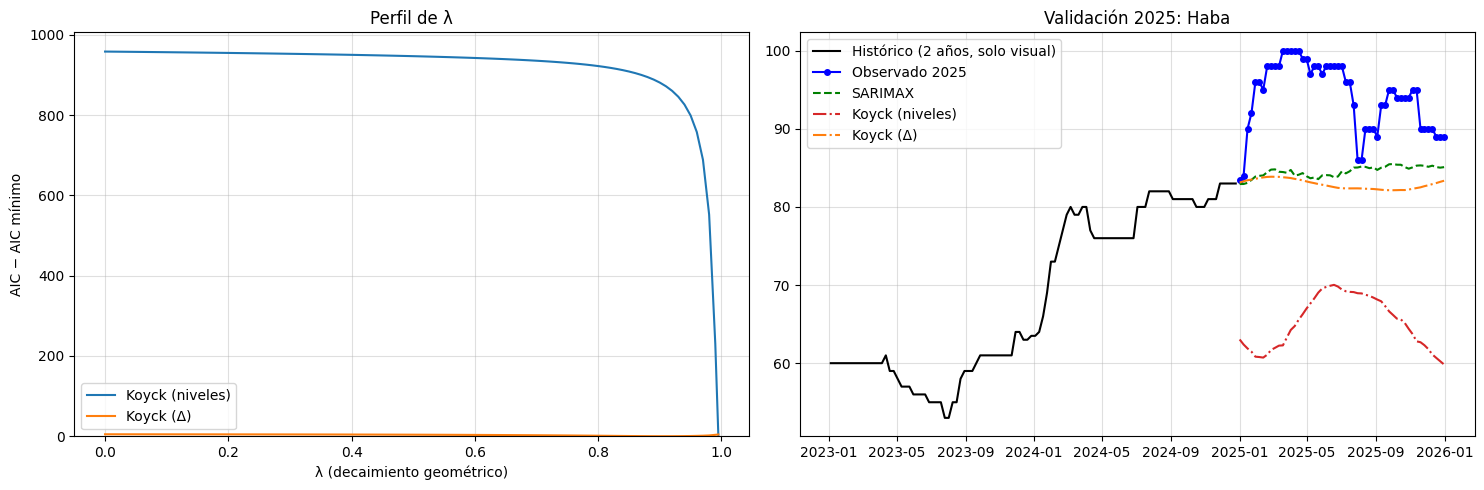

Parámetros (todas las variables con un λ común):


,0,1
Producto,Haba,Haba
Forma,niveles,Δ
λ,0.995,0.907
IC95 λ,"[0.99, 0.99]","[0.50, 0.99]"
Rezago medio (sem),199.0,9.8
Rezago mediano (sem),138.3,7.1
λ MCO transformada (sesgada),1.002,0.095
n,521,520
Ljung-Box p (10),0.0,0.019
Ljung-Box p (52),0.0,0.025


Memoria de cada variable por separado:


,Forma,Variable,λ,Rezago medio (sem),Rezago mediano (sem),β (corto plazo),Largo plazo,p β,λ en el borde
0,niveles,TMAX,0.995,199.0,138.3,0.3408,68.1574,0.0000,True
1,niveles,TMIN,0.985,65.2,45.5,0.2355,15.5876,0.0310,False
2,niveles,PRECIP,0.995,199.0,138.3,0.0283,5.6518,0.0000,True
3,Δ,TMAX,0.970,32.2,22.7,-0.0220,-0.7297,0.0340,False
4,Δ,TMIN,0.920,11.4,8.3,-0.0470,-0.5856,0.0101,False
5,Δ,PRECIP,0.832,5.0,3.8,-0.0020,-0.0117,0.3064,False


Año de prueba:


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),11.003,10.093,10.518
SARIMAX,10.652,9.637,10.027
SARIMAX con clima observado (referencia),10.652,9.637,10.027
Ingenuo (último valor),12.006,11.179,11.673
Ingenuo estacional (52 semanas antes),17.070,15.877,16.683
Koyck (niveles),29.362,28.930,30.592
Koyck (niveles) con clima observado (referencia),37.757,37.319,39.615
Koyck (Δ),12.052,11.289,11.799
Koyck (Δ) con clima observado (referencia),12.378,11.611,12.139


MAÍZ BLANCO — modelo de Koyck
  [!] Koyck (niveles): λ̂ = 0.995 quedó en el borde de la rejilla; la memoria no está bien identificada.
  [!] Koyck (niveles) solo con TMIN: λ̂ = 0.995 quedó en el borde de la rejilla (memoria no identificada).
  [!] Koyck (niveles) solo con PRECIP: λ̂ = 0.995 quedó en el borde de la rejilla (memoria no identificada).


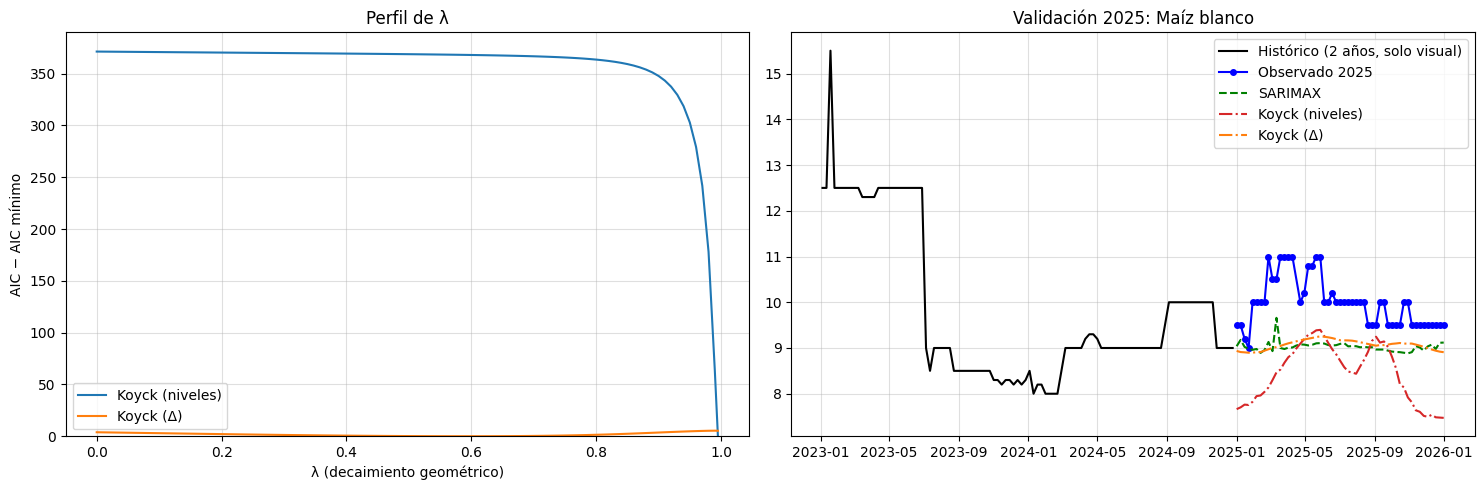

Parámetros (todas las variables con un λ común):


,0,1
Producto,Maíz blanco,Maíz blanco
Forma,niveles,Δ
λ,0.995,0.592
IC95 λ,"[0.99, 0.99]","[0.00, 0.91]"
Rezago medio (sem),199.0,1.5
Rezago mediano (sem),138.3,1.3
λ MCO transformada (sesgada),0.989,-0.173
n,521,520
Ljung-Box p (10),0.0,0.016
Ljung-Box p (52),0.0,0.0


Memoria de cada variable por separado:


,Forma,Variable,λ,Rezago medio (sem),Rezago mediano (sem),β (corto plazo),Largo plazo,p β,λ en el borde
0,niveles,TMAX,0.207,0.3,0.4,0.0559,0.0705,0.4287,False
1,niveles,TMIN,0.995,199.0,138.3,-0.0167,-3.3444,0.0223,True
2,niveles,PRECIP,0.995,199.0,138.3,-0.0020,-0.4068,0.3591,True
3,Δ,TMAX,0.490,1.0,1.0,0.0252,0.0494,0.0125,False
4,Δ,TMIN,0.274,0.4,0.5,0.0126,0.0173,0.0766,False
5,Δ,PRECIP,0.639,1.8,1.5,-0.0015,-0.0041,0.2840,False


Año de prueba:


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),1.121,0.984,9.605
SARIMAX,1.090,0.957,9.340
SARIMAX con clima observado (referencia),1.090,0.957,9.340
Ingenuo (último valor),1.121,0.985,9.608
Ingenuo estacional (52 semanas antes),1.223,1.021,10.004
Koyck (niveles),1.653,1.549,15.447
Koyck (niveles) con clima observado (referencia),1.419,1.196,12.163
Koyck (Δ),1.041,0.913,8.913
Koyck (Δ) con clima observado (referencia),1.008,0.880,8.588


FRIJOL PINTO — modelo de Koyck
  [!] Koyck (niveles): λ̂ = 0.990 quedó en el borde de la rejilla; la memoria no está bien identificada.
  [!] Koyck (niveles) solo con TMAX: λ̂ = 0.990 quedó en el borde de la rejilla (memoria no identificada).
  [!] Koyck (niveles) solo con PRECIP: λ̂ = 0.995 quedó en el borde de la rejilla (memoria no identificada).
  [!] Koyck (Δ): λ̂ = 0.000 quedó en el borde de la rejilla; la memoria no está bien identificada.
  [!] Koyck (Δ) solo con TMAX: λ̂ = 0.995 quedó en el borde de la rejilla (memoria no identificada).
  [!] Koyck (Δ) solo con PRECIP: λ̂ = 0.000 quedó en el borde de la rejilla (memoria no identificada).


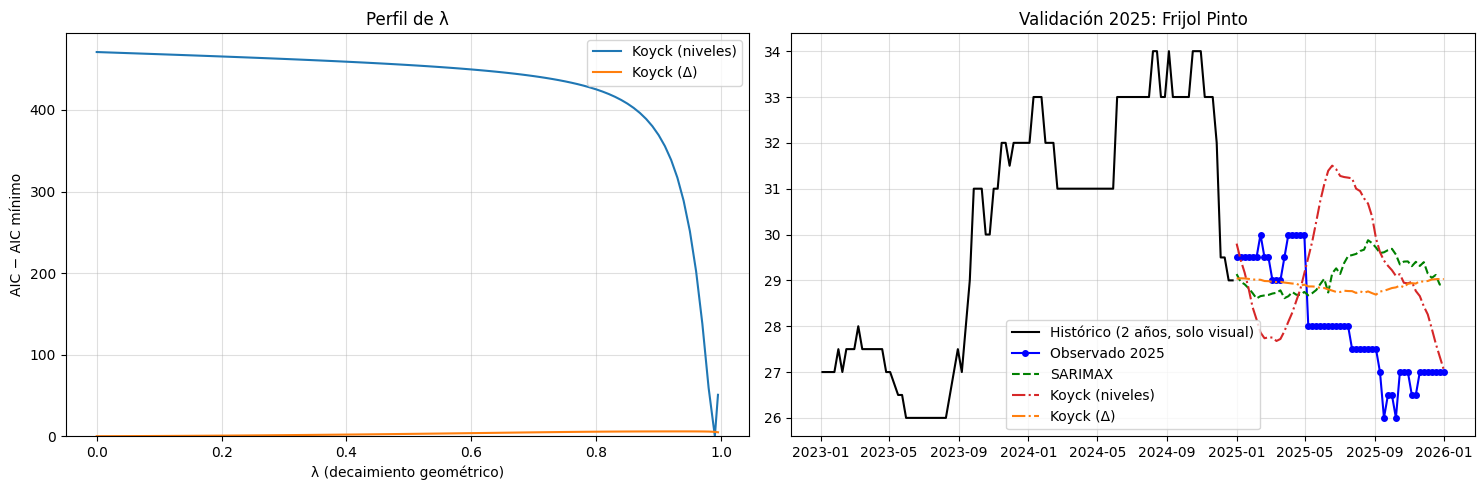

Parámetros (todas las variables con un λ común):


,0,1
Producto,Frijol Pinto,Frijol Pinto
Forma,niveles,Δ
λ,0.99,0.0
IC95 λ,"[0.99, 0.99]","[0.00, 0.60]"
Rezago medio (sem),99.3,0.0
Rezago mediano (sem),69.2,0.0
λ MCO transformada (sesgada),0.993,0.022
n,521,520
Ljung-Box p (10),0.0,0.669
Ljung-Box p (52),0.0,0.187


Memoria de cada variable por separado:


,Forma,Variable,λ,Rezago medio (sem),Rezago mediano (sem),β (corto plazo),Largo plazo,p β,λ en el borde
0,niveles,TMAX,0.990,101.7,70.9,0.0877,9.0128,0.0000,True
1,niveles,TMIN,0.990,96.9,67.5,0.0472,4.6194,0.0128,False
2,niveles,PRECIP,0.995,199.0,138.3,-0.0287,-5.7314,0.0000,True
3,Δ,TMAX,0.995,199.0,138.3,0.0062,1.2362,0.1695,True
4,Δ,TMIN,0.270,0.4,0.5,-0.0227,-0.0311,0.2244,False
5,Δ,PRECIP,0.000,0.0,0.0,-0.0043,-0.0043,0.2529,True


Año de prueba:


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),1.505,1.310,4.774
SARIMAX,1.838,1.612,5.863
SARIMAX con clima observado (referencia),1.838,1.612,5.863
Ingenuo (último valor),1.517,1.321,4.812
Ingenuo estacional (52 semanas antes),4.514,4.028,14.610
Koyck (niveles),2.281,2.032,7.316
Koyck (niveles) con clima observado (referencia),2.989,2.438,8.836
Koyck (Δ),1.422,1.226,4.465
Koyck (Δ) con clima observado (referencia),1.413,1.216,4.427


AGUACATE HASS - PRIMERA — modelo de Koyck
  [!] Koyck (Δ) solo con PRECIP: λ̂ = 0.994 quedó en el borde de la rejilla (memoria no identificada).


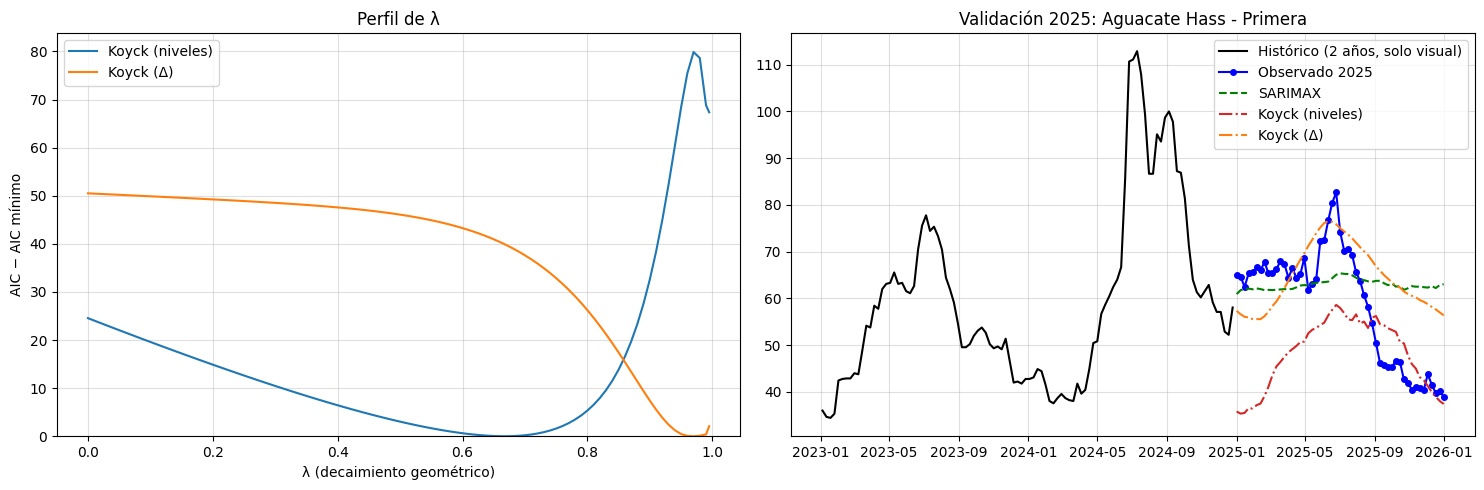

Parámetros (todas las variables con un λ común):


,0,1
Producto,Aguacate Hass - Primera,Aguacate Hass - Primera
Forma,niveles,Δ
λ,0.667,0.967
IC95 λ,"[0.48, 0.78]","[0.93, 0.99]"
Rezago medio (sem),2.0,29.7
Rezago mediano (sem),1.7,20.9
λ MCO transformada (sesgada),0.984,0.452
n,521,520
Ljung-Box p (10),0.0,0.0
Ljung-Box p (52),0.0,0.0


Memoria de cada variable por separado:


,Forma,Variable,λ,Rezago medio (sem),Rezago mediano (sem),β (corto plazo),Largo plazo,p β,λ en el borde
0,niveles,TMAX,0.910,10.1,7.4,0.3377,3.7535,0.0113,False
1,niveles,TMIN,0.706,2.4,2.0,1.1400,3.8832,0.0012,False
2,niveles,PRECIP,0.344,0.5,0.6,0.1204,0.1836,0.0014,False
3,Δ,TMAX,0.977,41.7,29.3,0.4573,19.5312,0.0000,False
4,Δ,TMIN,0.867,6.5,4.8,0.4213,3.1584,0.0002,False
5,Δ,PRECIP,0.994,179.5,124.8,-0.0165,-2.9695,0.0079,True


Año de prueba:


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),12.984,10.233,20.908
SARIMAX,12.637,9.980,20.379
SARIMAX con clima observado (referencia),12.995,10.246,20.940
Ingenuo (último valor),12.285,11.090,20.582
Ingenuo estacional (52 semanas antes),26.449,23.942,42.784
Koyck (niveles),16.438,13.664,21.487
Koyck (niveles) con clima observado (referencia),18.684,16.778,28.049
Koyck (Δ),12.038,10.286,20.637
Koyck (Δ) con clima observado (referencia),15.855,12.615,26.200


TOMATE SALADETTE - PRIMERA — modelo de Koyck
  [!] Koyck (niveles) solo con TMAX: λ̂ = 0.000 quedó en el borde de la rejilla (memoria no identificada).
  [!] Koyck (Δ): λ̂ = 0.000 quedó en el borde de la rejilla; la memoria no está bien identificada.


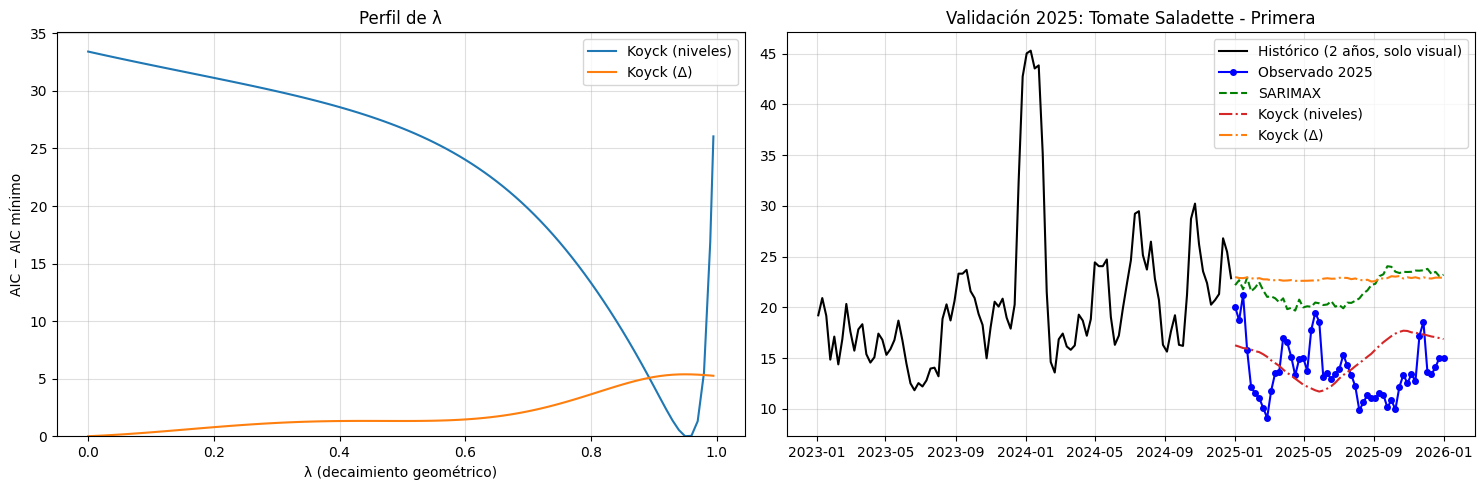

Parámetros (todas las variables con un λ común):


,0,1
Producto,Tomate Saladette - Primera,Tomate Saladette - Primera
Forma,niveles,Δ
λ,0.955,0.0
IC95 λ,"[0.91, 0.97]","[0.00, 0.81]"
Rezago medio (sem),21.2,0.0
Rezago mediano (sem),15.0,0.0
λ MCO transformada (sesgada),0.896,0.33
n,521,520
Ljung-Box p (10),0.0,0.0
Ljung-Box p (52),0.0,0.0


Memoria de cada variable por separado:


,Forma,Variable,λ,Rezago medio (sem),Rezago mediano (sem),β (corto plazo),Largo plazo,p β,λ en el borde
0,niveles,TMAX,0.000,0.0,0.0,-0.3464,-0.3464,0.1416,True
1,niveles,TMIN,0.989,86.6,60.4,0.0441,3.8597,0.0013,False
2,niveles,PRECIP,0.978,44.5,31.2,0.0196,0.8901,0.0001,False
3,Δ,TMAX,0.678,2.1,1.8,-0.0881,-0.2736,0.3021,False
4,Δ,TMIN,0.645,1.8,1.6,-0.1053,-0.2966,0.1748,False
5,Δ,PRECIP,0.073,0.1,0.3,-0.0150,-0.0162,0.0009,False


Año de prueba:


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),8.521,8.046,64.550
SARIMAX,8.643,7.974,64.391
SARIMAX con clima observado (referencia),8.643,7.974,64.391
Ingenuo (último valor),9.495,9.073,72.285
Ingenuo estacional (52 semanas antes),11.421,9.336,69.189
Koyck (niveles),3.906,3.338,26.136
Koyck (niveles) con clima observado (referencia),5.179,4.587,34.887
Koyck (Δ),9.439,9.013,71.834
Koyck (Δ) con clima observado (referencia),9.506,9.073,72.303


,Producto,Forma,λ,IC95 λ,Rezago medio (sem),Rezago mediano (sem),λ MCO transformada (sesgada),Ljung-Box p (10),RMSE Koyck,RMSE SARIMAX,RMSE SARIMA,RMSE ingenuo,Mejor modelo (RMSE)
0,Haba,niveles,0.995,"[0.99, 0.99]",199.0,138.3,1.002,0.000,29.362,10.652,11.003,12.006,SARIMAX
1,Haba,Δ,0.907,"[0.50, 0.99]",9.8,7.1,0.095,0.019,12.052,10.652,11.003,12.006,SARIMAX
2,Maíz blanco,niveles,0.995,"[0.99, 0.99]",199.0,138.3,0.989,0.000,1.653,1.090,1.121,1.121,Koyck (Δ)
3,Maíz blanco,Δ,0.592,"[0.00, 0.91]",1.5,1.3,-0.173,0.016,1.041,1.090,1.121,1.121,Koyck (Δ)
4,Frijol Pinto,niveles,0.990,"[0.99, 0.99]",99.3,69.2,0.993,0.000,2.281,1.838,1.505,1.517,Koyck (Δ)
5,Frijol Pinto,Δ,0.000,"[0.00, 0.60]",0.0,0.0,0.022,0.669,1.422,1.838,1.505,1.517,Koyck (Δ)
6,Aguacate Hass - Primera,niveles,0.667,"[0.48, 0.78]",2.0,1.7,0.984,0.000,16.438,12.637,12.984,12.285,Koyck (Δ)
7,Aguacate Hass - Primera,Δ,0.967,"[0.93, 0.99]",29.7,20.9,0.452,0.000,12.038,12.637,12.984,12.285,Koyck (Δ)
8,Tomate Saladette - Primera,niveles,0.955,"[0.91, 0.97]",21.2,15.0,0.896,0.000,3.906,8.643,8.521,9.495,Koyck (niveles)
9,Tomate Saladette - Primera,Δ,0.000,"[0.00, 0.81]",0.0,0.0,0.330,0.000,9.439,8.643,8.521,9.495,Koyck (niveles)


In [58]:
param_koyck, var_koyck, resumen_koyck = [], [], []
for producto in PRODUCTOS_MODELADO:
    if producto not in PRODUCTOS_CON_CLIMA:
        print(f"{producto}: sin Koyck — necesita clima como variable explicativa ({DETALLE_CLIMA.get(producto, 'sin clima')}).\n")
        continue
    print('=' * 70)
    print(f"{producto.upper()} — modelo de Koyck")
    print('=' * 70)
    p_df, v_df, tabla, pron = koyck_producto(datos_por_producto[producto], producto)
    TABLAS_KOYCK[producto], PRONOSTICOS_KOYCK[producto] = tabla, pron
    p_df.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, f'koyck_parametros_{slug(producto)}.csv'), index=False)
    v_df.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, f'koyck_por_variable_{slug(producto)}.csv'), index=False)
    tabla.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, f'metricas_koyck_{ANIO_PRUEBA}_{slug(producto)}.csv'))
    print("Parámetros (todas las variables con un λ común):")
    display(p_df.T)
    print("Memoria de cada variable por separado:")
    display(v_df.drop(columns=['Producto']))
    print("Año de prueba:")
    display(tabla)
    sin_ref = tabla[~tabla.index.str.contains('referencia')]
    mejor = sin_ref['RMSE'].idxmin() if len(sin_ref) and sin_ref['RMSE'].notna().any() else None
    for _, fila in p_df.iterrows():
        nombre = f"Koyck ({fila['Forma']})"
        resumen_koyck.append({**fila.to_dict(), 'RMSE Koyck': tabla.loc[nombre, 'RMSE'] if nombre in tabla.index else None,
                              'MAPE Koyck (%)': tabla.loc[nombre, 'MAPE (%)'] if nombre in tabla.index else None,
                              'RMSE SARIMAX': tabla.loc['SARIMAX', 'RMSE'] if 'SARIMAX' in tabla.index else None,
                              'RMSE SARIMA': tabla.loc['SARIMA (sin clima)', 'RMSE'] if 'SARIMA (sin clima)' in tabla.index else None,
                              'RMSE ingenuo': tabla.loc['Ingenuo (último valor)', 'RMSE'] if 'Ingenuo (último valor)' in tabla.index else None,
                              'Mejor modelo (RMSE)': mejor})
    param_koyck.append(p_df); var_koyck.append(v_df)

if resumen_koyck:
    tabla_resumen_koyck = pd.DataFrame(resumen_koyck)
    tabla_resumen_koyck.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, 'tabla_resumen_koyck.csv'), index=False)
    columnas = ['Producto', 'Forma', 'λ', 'IC95 λ', 'Rezago medio (sem)', 'Rezago mediano (sem)', 'λ MCO transformada (sesgada)',
                'Ljung-Box p (10)', 'RMSE Koyck', 'RMSE SARIMAX', 'RMSE SARIMA', 'RMSE ingenuo', 'Mejor modelo (RMSE)']
    display(tabla_resumen_koyck[columnas])
else:
    print("Ningún producto tiene clima suficiente: no se estimó el modelo de Koyck.")

### 5.12 Descomposición STL: un modelo por componente

En lugar de modelar el precio completo, se separa en `precio = tendencia + estacionalidad + residuo` (STL aditivo, período 52, robusto, como en la sección 4 pero ajustado **solo con 2015-2024**), se pronostica cada componente con el modelo que le corresponde y se vuelven a sumar.

| Componente | Modelo | Cómo se elige |
|---|---|---|
| Tendencia | ARIMA(p, d, q) | `d` por ADF (0 o 1; no se permite d = 2 porque extrapolaría una pendiente durante todo el año de prueba); `p`, `q` por AIC |
| Estacionalidad | SARIMA(p, 0, q)(P, 0, Q)₅₂ | por AIC (D = 0, igual que en 5.1) |
| Residuo | **depende de si es ruido blanco** | Ljung-Box (rezagos 10 y 52, 5 %): si no se rechaza ruido blanco, el modelo es solo una media; si se rechaza, ARMA(p, q) por AIC |

**Versión con clima.** Los mismos tres modelos con regresores climáticos (ARIMAX en la tendencia, SARIMAX en la estacionalidad, ARMAX en el residuo), desfasados el mismo `k` que eligió el SARIMAX en 5.8. Cada componente recibe **el componente correspondiente del clima**: TMAX, TMIN y PRECIP se descomponen con el mismo STL, y la tendencia del clima alimenta a la tendencia del precio, la estacionalidad del clima a la estacionalidad del precio y la anomalía (residuo) del clima al residuo del precio. Meter el clima en bruto en todos los componentes mezcla su estacionalidad en componentes que ya no la tienen; en mis pruebas con series sintéticas eso empeoró mucho el pronóstico, incluso usando el clima observado. Para quitar el clima de algún componente, edita `COMPONENTES_CON_CLIMA`.

**Qué se supone del clima de 2025.** Las semanas ya conocidas al cierre de 2024 (hasta `k`) se usan tal cual. Para el resto: la tendencia del clima se mantiene en su último valor, la estacionalidad repite el último ciclo y la anomalía vale 0, porque una anomalía futura no se puede conocer. Por eso los modelos con clima solo pueden ganar con las semanas conocidas y con lo que el clima aporte a la tendencia y a la forma estacional. Solo hay versión con clima para los productos que tienen clima suficiente. Para comparar con justicia, los modelos con y sin clima se ajustan sobre la misma muestra (la que descarta las primeras `MAX_LAG` semanas) en los productos con clima.

Además de las versiones principales se incluye **«estacional = último ciclo»**: la estacionalidad se pronostica repitiendo las últimas 52 semanas de su componente. Si el SARIMA del componente estacional no le gana a esta referencia, no está aportando nada.

**Cosas a tener en cuenta al interpretar:**
- STL suaviza con datos de ambos lados. Al final de la muestra solo tiene datos de un lado, así que **la tendencia de las últimas ~50 semanas es menos fiable** (se sombrea en la figura) y el ARIMA de la tendencia hereda esa debilidad. Es justo la zona desde la que se pronostica.
- El componente estacional de STL es casi periódico y muy suave; el SARIMA sobre él es un ajuste fino, no un descubrimiento.
- El clima de la tendencia y de la estacionalidad es muy suave y está muy correlacionado entre variables; la tabla de modelos muestra el ΔAIC y los regresores significativos por componente para decidir si dejarlo. Con tres regresores suaves es fácil sobreajustar la tendencia.
- La fila «con clima observado (referencia)» usa los componentes del clima real de 2025 (descompuestos con la serie completa) y no cuenta para «mejor modelo».
- Los AIC se comparan entre componentes con y sin clima sobre la misma muestra, pero no entre componentes distintos ni contra el SARIMAX de 5.8 (otra variable dependiente).

In [59]:
from statsmodels.tsa.seasonal import STL

# --- Configuración de la descomposición STL ---
STL_PERIODO = S_ESTACIONAL
STL_SEASONAL = 7              # suavizado estacional (impar; valor por defecto de statsmodels). Mayor = estacionalidad más estable
STL_ROBUSTO = True
ALFA_RUIDO_BLANCO = 0.05      # nivel de la prueba Ljung-Box que decide el modelo del residuo
D_TENDENCIA_MAX = 1           # d máximo de la tendencia
COMPONENTES_CON_CLIMA = ['tendencia', 'estacional', 'residuo']   # componentes que reciben el clima en la versión «con clima»
GRILLAS_STL = {'tendencia': {'p_max': 2, 'q_max': 2},
               'estacional': {'p_max': 2, 'q_max': 1, 'P_max': 1, 'Q_max': 1},
               'residuo': {'p_max': 2, 'q_max': 2}}
COMPONENTES = ['tendencia', 'estacional', 'residuo']
TABLAS_STL, PRONOSTICOS_STL = {}, {}


def ventana_tendencia_stl():
    """Ventana de tendencia por defecto de statsmodels (se fija explícita para poder sombrear el borde)."""
    t = int(np.ceil(1.5 * STL_PERIODO / (1 - 1.5 / STL_SEASONAL)))
    return t + 1 if t % 2 == 0 else t


def descomponer_stl(precio):
    r = STL(precio, period=STL_PERIODO, seasonal=STL_SEASONAL, trend=ventana_tendencia_stl(), robust=STL_ROBUSTO).fit()
    return pd.DataFrame({'tendencia': r.trend, 'estacional': r.seasonal, 'residuo': r.resid}, index=precio.index)


def elegir_d_tendencia(tendencia):
    """Menor d (hasta D_TENDENCIA_MAX) para el que ADF rechaza raíz unitaria al 5 %. Devuelve (d, p-valores ADF)."""
    x, pvals = tendencia, []
    for d in range(D_TENDENCIA_MAX + 1):
        p = adfuller(x.dropna(), autolag='AIC')[1]
        pvals.append(round(p, 4))
        if p < 0.05:
            return d, pvals
        x = x.diff()
    return D_TENDENCIA_MAX, pvals


def es_ruido_blanco(resid, alfa=ALFA_RUIDO_BLANCO):
    lags = [l for l in (10, 52) if l < len(resid)]
    pv = acorr_ljungbox(resid, lags=lags)['lb_pvalue']
    return bool((pv > alfa).all()), pv


def especificacion(componente, d=0, p=0, q=0, P=0, Q=0):
    """(order, seasonal_order, trend) de cada componente."""
    if componente == 'tendencia':
        return (p, d, q), (0, 0, 0, 0), ('c' if d == 0 else 'n')
    if componente == 'estacional':
        return (p, 0, q), (P, D_ESTACIONAL, Q, STL_PERIODO), 'n'
    return (p, 0, q), (0, 0, 0, 0), 'c'


def nombre_modelo(componente, spec, con_clima=False):
    (p, d, q), (P, D, Q, sp), _ = spec
    x = 'X' if con_clima else ''
    if componente == 'tendencia':
        return f'ARIMA{x}({p},{d},{q})'
    if componente == 'estacional':
        return f'SARIMA{x}({p},{d},{q})({P},{D},{Q},{sp})'
    if (p, q) == (0, 0):
        return 'Media + clima (regresión)' if con_clima else 'Media (ruido blanco)'
    return f'ARMA{x}({p},{q})'


def ajustar_componente(y, spec, exog=None, arranque=None):
    """SARIMAX de un componente. Con clima, `arranque` (parámetros del ajuste sin clima) fija el punto de partida del
    optimizador: coeficientes del clima en 0 y el resto como en el modelo sin clima. Así el modelo con clima no puede
    quedar peor que el modelo sin clima por un mal punto de partida."""
    orden, orden_est, tendencia = spec
    modelo = SARIMAX(y, exog=exog, order=orden, seasonal_order=orden_est, trend=tendencia,
                     enforce_stationarity=False, enforce_invertibility=False)
    if arranque is None:
        return modelo.fit(disp=False)
    inicio = np.array([float(arranque.get(nombre, 0.0)) for nombre in modelo.param_names])
    return modelo.fit(start_params=inicio, disp=False)


def seleccionar_componente(y, componente, d=0):
    """Rejilla por AIC (sin clima). Devuelve (mejor especificación, tabla de candidatos)."""
    g = GRILLAS_STL[componente]
    filas, mejor = [], None
    for p, q, P, Q in itertools.product(range(g['p_max'] + 1), range(g['q_max'] + 1),
                                        range(g.get('P_max', 0) + 1), range(g.get('Q_max', 0) + 1)):
        spec = especificacion(componente, d, p, q, P, Q)
        try:
            r = ajustar_componente(y, spec)
        except Exception:
            continue
        filas.append({'Modelo': nombre_modelo(componente, spec), 'AIC': r.aic})
        if mejor is None or r.aic < mejor[1]:
            mejor = (spec, r.aic)
    if mejor is None:
        raise RuntimeError(f"No se pudo ajustar ningún modelo para el componente '{componente}'.")
    return mejor[0], pd.DataFrame(filas).sort_values('AIC').reset_index(drop=True)


def exogenas_componentes(datos, clima_comp, k):
    """Regresores de cada componente para el año de prueba (versión principal): lo ya conocido al cierre del
    entrenamiento (semana − k <= cierre) y, para el resto, tendencia = último valor, estacionalidad = último ciclo
    y anomalía = 0."""
    test_idx, origen = prueba(datos).index, entrenamiento(datos).index[-1]
    salida = {c: {v: [] for v in VARIABLES_CLIMA} for c in COMPONENTES}
    for v in VARIABLES_CLIMA:
        comp = clima_comp[v]
        futuro = ultimo_ciclo(comp['estacional'], len(test_idx))
        for t in test_idx:
            fuente = t - pd.Timedelta(weeks=k)
            if fuente <= origen:
                for c in COMPONENTES:
                    salida[c][v].append(comp.loc[fuente, c])
            else:
                paso = int(round((fuente - origen) / pd.Timedelta(weeks=1)))      # 1 = semana siguiente al cierre
                salida['tendencia'][v].append(comp['tendencia'].iloc[-1])
                salida['estacional'][v].append(futuro[paso - 1])
                salida['residuo'][v].append(0.0)
    return {c: pd.DataFrame(salida[c], index=test_idx, columns=VARIABLES_CLIMA) for c in COMPONENTES}


def pronosticar_componente(modelo, h, exog=None):
    return modelo.get_forecast(h, exog=exog).predicted_mean.values


def ultimo_ciclo(estacional, h):
    """Repite las últimas STL_PERIODO observaciones del componente estacional."""
    return np.take(estacional.values[-STL_PERIODO:], np.arange(h) % STL_PERIODO)


def graficar_stl_entrenamiento(datos, comp, producto):
    train = entrenamiento(datos)
    borde = comp.index[-(ventana_tendencia_stl() // 2)]
    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    for ax, (nombre, serie) in zip(axes, [('Precio', train['Precio'])] + [(c.capitalize(), comp[c]) for c in COMPONENTES]):
        ax.plot(serie.index, serie.values, color='black', linewidth=1.2)
        ax.axvspan(borde, comp.index[-1], color='orange', alpha=0.15)
        ax.set_ylabel(nombre)
        ax.grid(alpha=0.3)
    axes[2].axhline(0, color='gray', linewidth=0.8); axes[3].axhline(0, color='gray', linewidth=0.8)
    fig.suptitle(f'STL del entrenamiento — {producto} (sombreado: borde final, tendencia menos fiable)', y=1.0)
    fig.tight_layout()
    plt.savefig(os.path.join(CARPETA_RESULTADOS_MODELADO, f'stl_componentes_{slug(producto)}.png'), dpi=200)
    plt.show()


def graficar_stl_validacion(datos, comp, producto, pron_comp, pron_total, obs):
    train, test = entrenamiento(datos), prueba(datos)
    fig = plt.figure(figsize=(15, 9))
    gs = fig.add_gridspec(2, 3)
    ax = fig.add_subplot(gs[0, :])
    ax.plot(train.index[-104:], train['Precio'].iloc[-104:], color='black', label='Histórico (2 años, solo visual)')
    if obs.sum() > 0:
        ax.plot(test.index[obs], test['Precio'].values[obs], color='blue', marker='o', markersize=4, label=f'Observado {ANIO_PRUEBA}')
    if 'SARIMAX' in PRONOSTICOS_5.get(producto, {}):
        ax.plot(test.index, PRONOSTICOS_5[producto]['SARIMAX'], color='green', linestyle='--', label='SARIMAX')
    estilos = {'STL sin clima': '#8c564b', 'STL con clima': '#17becf'}
    for nombre, color in estilos.items():
        if nombre in pron_total:
            ax.plot(test.index, pron_total[nombre], color=color, linestyle='-.', linewidth=2, label=nombre)
    ax.set_title(f'Validación {ANIO_PRUEBA}: {producto}')
    ax.legend(); ax.grid(alpha=0.4)
    for j, c in enumerate(COMPONENTES):
        axc = fig.add_subplot(gs[1, j])
        axc.plot(comp.index[-104:], comp[c].iloc[-104:], color='black', label='STL (entrenamiento)')
        for nombre, color in estilos.items():
            if nombre in pron_comp:
                axc.plot(test.index, pron_comp[nombre][c], color=color, linestyle='-.', label=nombre)
        if c == 'estacional':
            axc.plot(test.index, pron_comp['STL sin clima (estacional = último ciclo)'][c], color='gray', linestyle=':', label='Último ciclo')
        axc.set_title(f'Pronóstico: {c}')
        axc.grid(alpha=0.4)
        axc.tick_params(axis='x', labelrotation=30, labelsize=8)
        if j == 0:
            axc.legend(fontsize=8)
    fig.tight_layout()
    plt.savefig(os.path.join(CARPETA_RESULTADOS_MODELADO, f'stl_validacion_{slug(producto)}.png'), dpi=200)
    plt.show()


def stl_producto(producto, graficar=True):
    """STL + modelo por componente (sin y con clima), recombinación y comparación con los demás modelos."""
    if producto not in TABLAS_METRICAS_5:
        raise RuntimeError(f"Falta el resultado de la sección 5.9 para '{producto}': corre esa celda antes del STL.")
    datos = datos_por_producto[producto]
    con_clima = producto in PRODUCTOS_CON_CLIMA
    k = PARAMETROS_5[producto]['k'] if con_clima else None
    train, test = entrenamiento(datos), prueba(datos)
    h = len(test)
    obs = test['Observado'].values.astype(bool)
    y_obs = test['Precio'].values[obs]
    comp = descomponer_stl(train['Precio'])
    muestra = comp.iloc[MAX_LAG if con_clima else 0:]          # misma muestra que el SARIMA/SARIMAX de 5.8
    if graficar:
        graficar_stl_entrenamiento(datos, comp, producto)

    # ---- especificación de cada componente (siempre se elige SIN clima)
    d, pvals_adf = elegir_d_tendencia(muestra['tendencia'])
    spec = {'tendencia': seleccionar_componente(muestra['tendencia'], 'tendencia', d)[0],
            'estacional': seleccionar_componente(muestra['estacional'], 'estacional')[0]}
    blanco, pv_blanco = es_ruido_blanco(muestra['residuo'])
    spec['residuo'] = especificacion('residuo') if blanco else seleccionar_componente(muestra['residuo'], 'residuo')[0]
    print(f"{producto}: tendencia d = {d} (p ADF {pvals_adf}) | residuo STL "
          f"{'ES' if blanco else 'NO es'} ruido blanco (Ljung-Box p: " + ', '.join(f'{l}={v:.3f}' for l, v in pv_blanco.items()) + ")")

    # ---- ajuste sin clima y con clima, sobre la misma muestra
    sin = {c: ajustar_componente(muestra[c], spec[c]) for c in COMPONENTES}
    con = None
    if con_clima:
        clima_comp = {v: descomponer_stl(train[v]) for v in VARIABLES_CLIMA}          # solo entrenamiento
        clima_completo = {v: descomponer_stl(datos[v]) for v in VARIABLES_CLIMA}      # solo para la fila de referencia
        X = {c: pd.DataFrame({v: clima_comp[v][c] for v in VARIABLES_CLIMA}).shift(k).loc[muestra.index] for c in COMPONENTES}
        X_real = exogenas_componentes(datos, clima_comp, k)
        X_obs = {c: pd.DataFrame({v: clima_completo[v][c] for v in VARIABLES_CLIMA}).shift(k).loc[test.index] for c in COMPONENTES}
        con = {c: (ajustar_componente(muestra[c], spec[c], exog=X[c], arranque=sin[c].params) if c in COMPONENTES_CON_CLIMA else sin[c])
               for c in COMPONENTES}

    # ---- pronósticos por componente y recombinación
    def pronostico(modelos, X_futura=None):
        return pd.DataFrame({c: pronosticar_componente(modelos[c], h, X_futura[c] if (X_futura is not None and c in COMPONENTES_CON_CLIMA) else None)
                             for c in COMPONENTES}, index=test.index)
    pron_comp = {'STL sin clima': pronostico(sin)}
    ult = pron_comp['STL sin clima'].copy()
    ult['estacional'] = ultimo_ciclo(comp['estacional'], h)
    pron_comp['STL sin clima (estacional = último ciclo)'] = ult
    if con_clima:
        pron_comp['STL con clima'] = pronostico(con, X_real)
        pron_comp['STL con clima observado (referencia)'] = pronostico(con, X_obs)
    pron_total = {n: df.sum(axis=1) for n, df in pron_comp.items()}

    # ---- métricas junto a los demás modelos
    base = TABLAS_KOYCK.get(producto, TABLAS_METRICAS_5[producto]) if 'TABLAS_KOYCK' in globals() else TABLAS_METRICAS_5[producto]
    if obs.sum() > 0:
        filas = {n: metricas(y_obs, s.values[obs]) for n, s in pron_total.items()}
        tabla = pd.concat([base, pd.DataFrame(filas).T.round(3)])
    else:
        tabla = base

    # ---- tabla de modelos por componente
    filas_mod = []
    for c in COMPONENTES:
        orden, orden_est, _ = spec[c]
        lb = ljung_box(sin[c], orden, orden_est)
        fila = {'Componente': c, 'Modelo sin clima': nombre_modelo(c, spec[c]), 'AIC sin clima': round(sin[c].aic, 2),
                'Ljung-Box p (10)': round(lb.get(10), 3) if 10 in lb.index else None,
                'Ljung-Box p (52)': round(lb.get(52), 3) if 52 in lb.index else None}
        if con_clima:
            usa = c in COMPONENTES_CON_CLIMA
            sig = [v for v in VARIABLES_CLIMA if usa and con[c].pvalues[v] < 0.05]
            fila.update({'Modelo con clima': nombre_modelo(c, spec[c], True) if usa else 'sin clima (igual que arriba)',
                         'AIC con clima': round(con[c].aic, 2) if usa else None,
                         'ΔAIC (sin − con)': round(sin[c].aic - con[c].aic, 2) if usa else None,
                         'Clima significativo (p<0.05)': ', '.join(sig) if sig else ('—' if usa else 'n/a')})
        filas_mod.append(fila)
    modelos = pd.DataFrame(filas_mod)
    if graficar:
        graficar_stl_validacion(datos, comp, producto, pron_comp, pron_total, obs)
    detalle = {'d': d, 'ruido_blanco': blanco, 'k': k, 'modelos': {c: nombre_modelo(c, spec[c]) for c in COMPONENTES}}
    return comp, modelos, tabla, pron_comp, pron_total, detalle

### 5.13 STL: ejecución y comparación

Para cada producto: descomposición del entrenamiento, qué modelo recibió cada componente (y si el residuo resultó ruido blanco), el pronóstico recombinado y las métricas junto a SARIMA, SARIMAX, Koyck (si ya corriste 5.11) y los ingenuos. «Mejor modelo» es el de menor RMSE sin contar las filas de referencia. Resultados en `resultados_modelado/stl_*.csv` y `metricas_stl_*.csv`.

HABA — STL por componentes (con y sin clima)


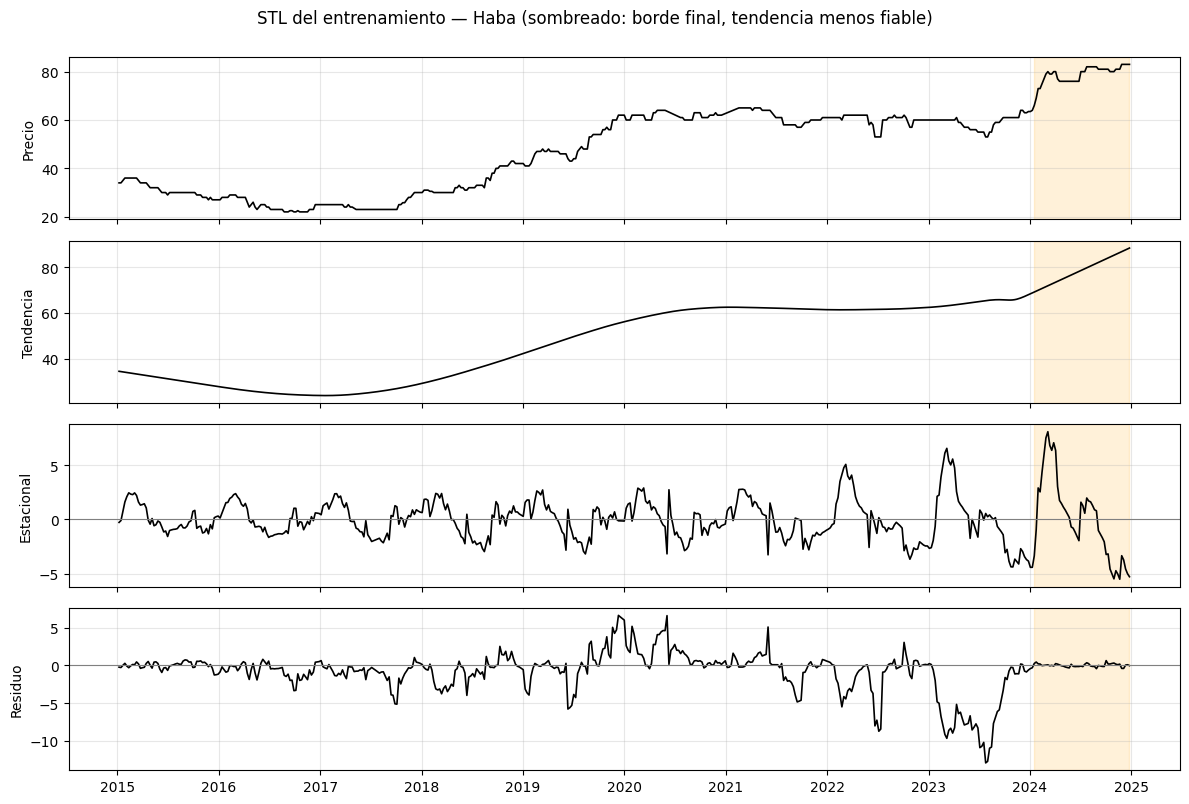

Haba: tendencia d = 1 (p ADF [np.float64(0.8963), np.float64(0.7697)]) | residuo STL NO es ruido blanco (Ljung-Box p: 10=0.000, 52=0.000)


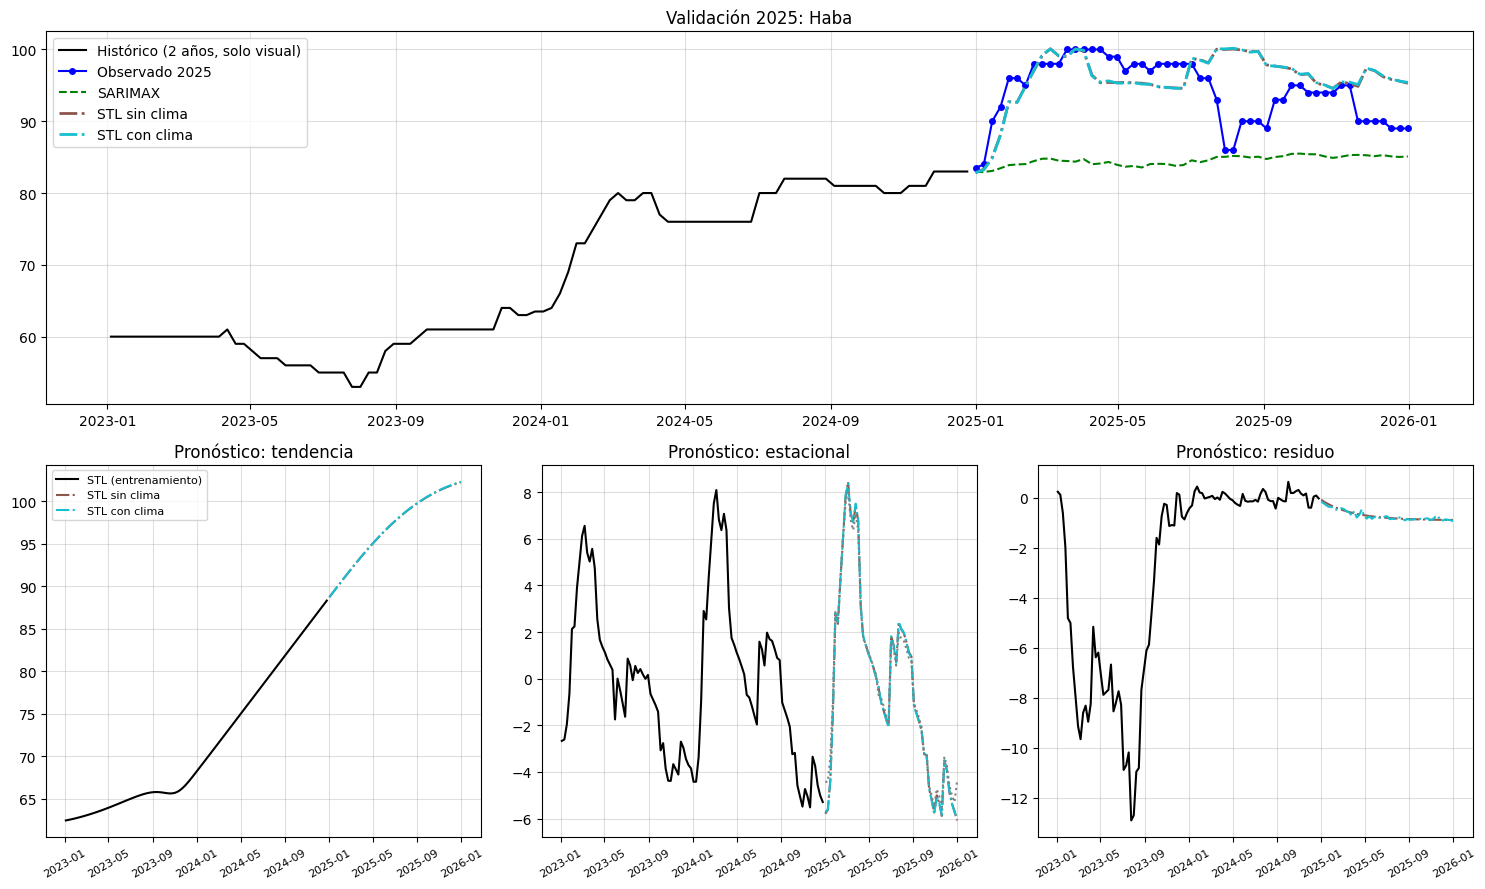

Modelo de cada componente:


,Componente,Modelo sin clima,AIC sin clima,Ljung-Box p (10),Ljung-Box p (52),Modelo con clima,AIC con clima,ΔAIC (sin − con),Clima significativo (p<0.05)
0,tendencia,"ARIMA(2,1,1)",-4534.58,0.332,1.0,"ARIMAX(2,1,1)",-4529.79,-4.80,—
1,estacional,"SARIMA(1,0,0)(1,0,1,52)",352.16,0.033,0.0,"SARIMAX(1,0,0)(1,0,1,52)",353.25,-1.08,—
2,residuo,"ARMA(1,2)",1306.36,0.932,0.0,"ARMAX(1,2)",1309.08,-2.72,—


Año de prueba:


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),11.003,10.093,10.518
SARIMAX,10.652,9.637,10.027
SARIMAX con clima observado (referencia),10.652,9.637,10.027
Ingenuo (último valor),12.006,11.179,11.673
Ingenuo estacional (52 semanas antes),17.070,15.877,16.683
Koyck (niveles),29.362,28.930,30.592
Koyck (niveles) con clima observado (referencia),37.757,37.319,39.615
Koyck (Δ),12.052,11.289,11.799
Koyck (Δ) con clima observado (referencia),12.378,11.611,12.139
STL sin clima,5.089,3.854,4.199


MAÍZ BLANCO — STL por componentes (con y sin clima)


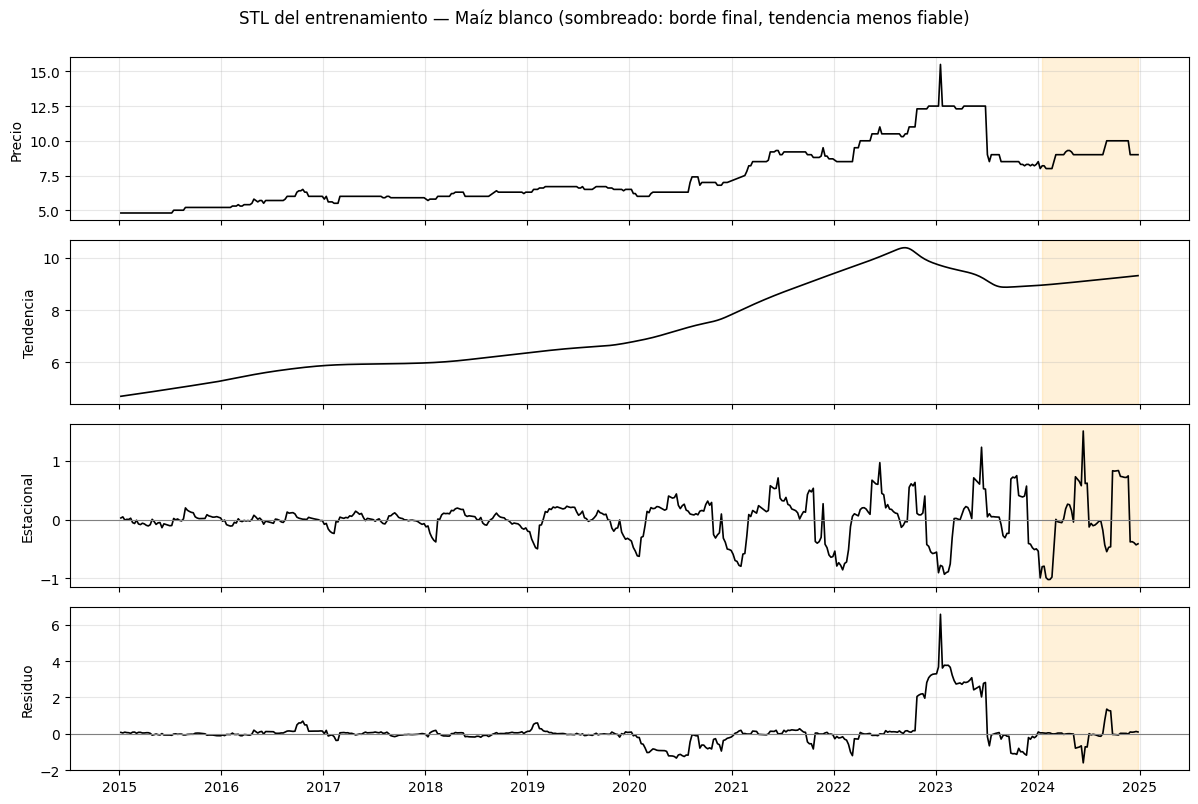

Maíz blanco: tendencia d = 1 (p ADF [np.float64(0.599), np.float64(0.2643)]) | residuo STL NO es ruido blanco (Ljung-Box p: 10=0.000, 52=0.000)


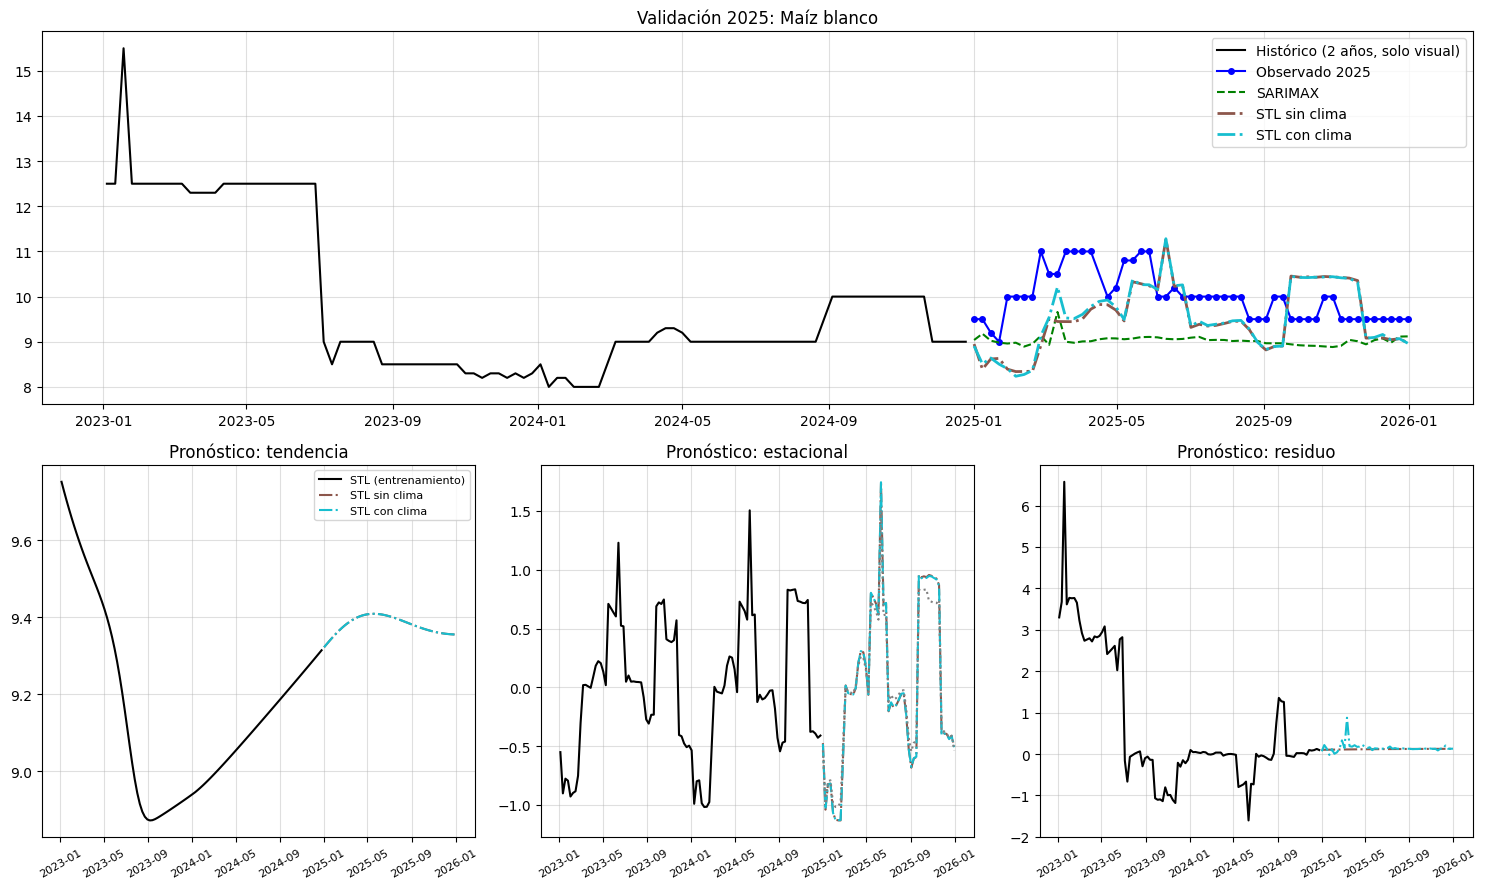

Modelo de cada componente:


,Componente,Modelo sin clima,AIC sin clima,Ljung-Box p (10),Ljung-Box p (52),Modelo con clima,AIC con clima,ΔAIC (sin − con),Clima significativo (p<0.05)
0,tendencia,"ARIMA(2,1,2)",-5710.92,0.321,1.0,"ARIMAX(2,1,2)",-5705.69,-5.23,—
1,estacional,"SARIMA(1,0,0)(1,0,1,52)",-963.12,0.015,0.0,"SARIMAX(1,0,0)(1,0,1,52)",-959.42,-3.70,—
2,residuo,"ARMA(1,1)",258.65,0.493,0.0,"ARMAX(1,1)",247.42,11.23,PRECIP


Año de prueba:


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),1.121,0.984,9.605
SARIMAX,1.090,0.957,9.340
SARIMAX con clima observado (referencia),1.090,0.957,9.340
Ingenuo (último valor),1.121,0.985,9.608
Ingenuo estacional (52 semanas antes),1.223,1.021,10.004
Koyck (niveles),1.653,1.549,15.447
Koyck (niveles) con clima observado (referencia),1.419,1.196,12.163
Koyck (Δ),1.041,0.913,8.913
Koyck (Δ) con clima observado (referencia),1.008,0.880,8.588
STL sin clima,0.945,0.822,8.149


FRIJOL PINTO — STL por componentes (con y sin clima)


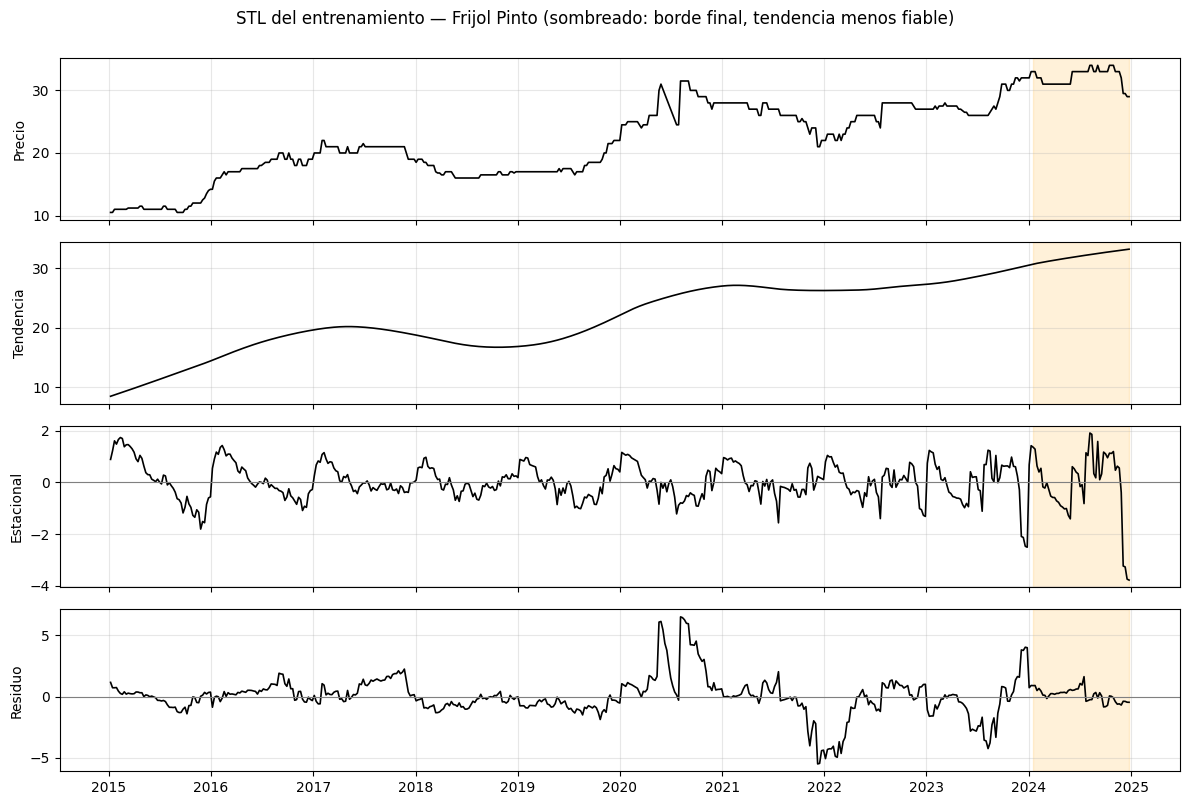

Frijol Pinto: tendencia d = 1 (p ADF [np.float64(0.9401), np.float64(0.0584)]) | residuo STL NO es ruido blanco (Ljung-Box p: 10=0.000, 52=0.000)


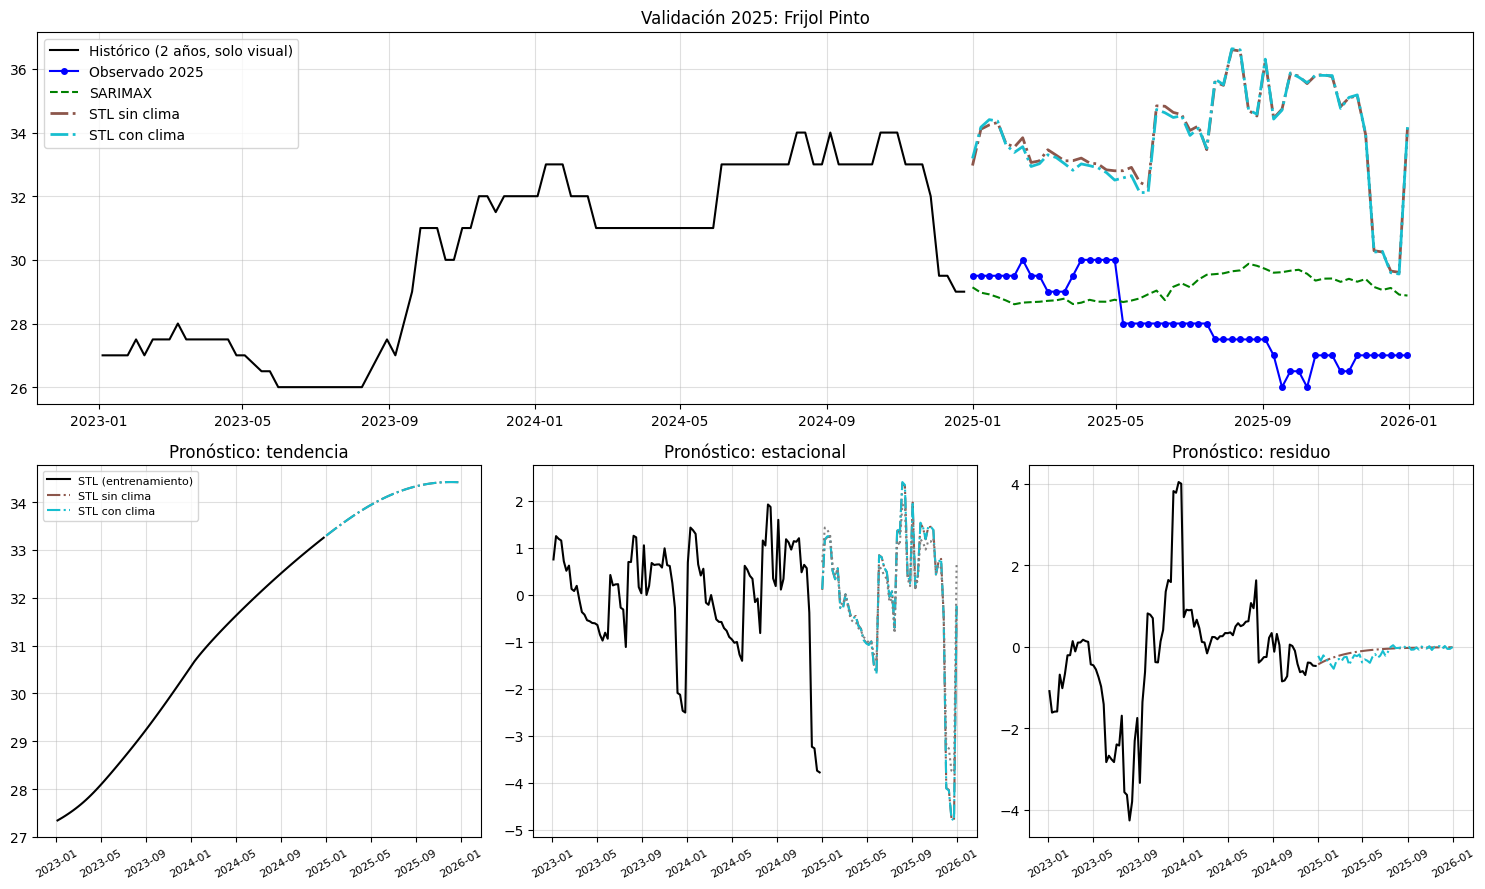

Modelo de cada componente:


,Componente,Modelo sin clima,AIC sin clima,Ljung-Box p (10),Ljung-Box p (52),Modelo con clima,AIC con clima,ΔAIC (sin − con),Clima significativo (p<0.05)
0,tendencia,"ARIMA(2,1,1)",-4986.48,0.359,1.000,"ARIMAX(2,1,1)",-4980.47,-6.00,—
1,estacional,"SARIMA(2,0,1)(1,0,1,52)",-283.94,0.000,0.002,"SARIMAX(2,0,1)(1,0,1,52)",-278.96,-4.98,—
2,residuo,"ARMA(1,0)",878.03,0.988,0.393,"ARMAX(1,0)",875.08,2.95,TMIN


Año de prueba:


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),1.505,1.310,4.774
SARIMAX,1.838,1.612,5.863
SARIMAX con clima observado (referencia),1.838,1.612,5.863
Ingenuo (último valor),1.517,1.321,4.812
Ingenuo estacional (52 semanas antes),4.514,4.028,14.610
Koyck (niveles),2.281,2.032,7.316
Koyck (niveles) con clima observado (referencia),2.989,2.438,8.836
Koyck (Δ),1.422,1.226,4.465
Koyck (Δ) con clima observado (referencia),1.413,1.216,4.427
STL sin clima,6.265,5.851,21.127


AGUACATE HASS - PRIMERA — STL por componentes (con y sin clima)


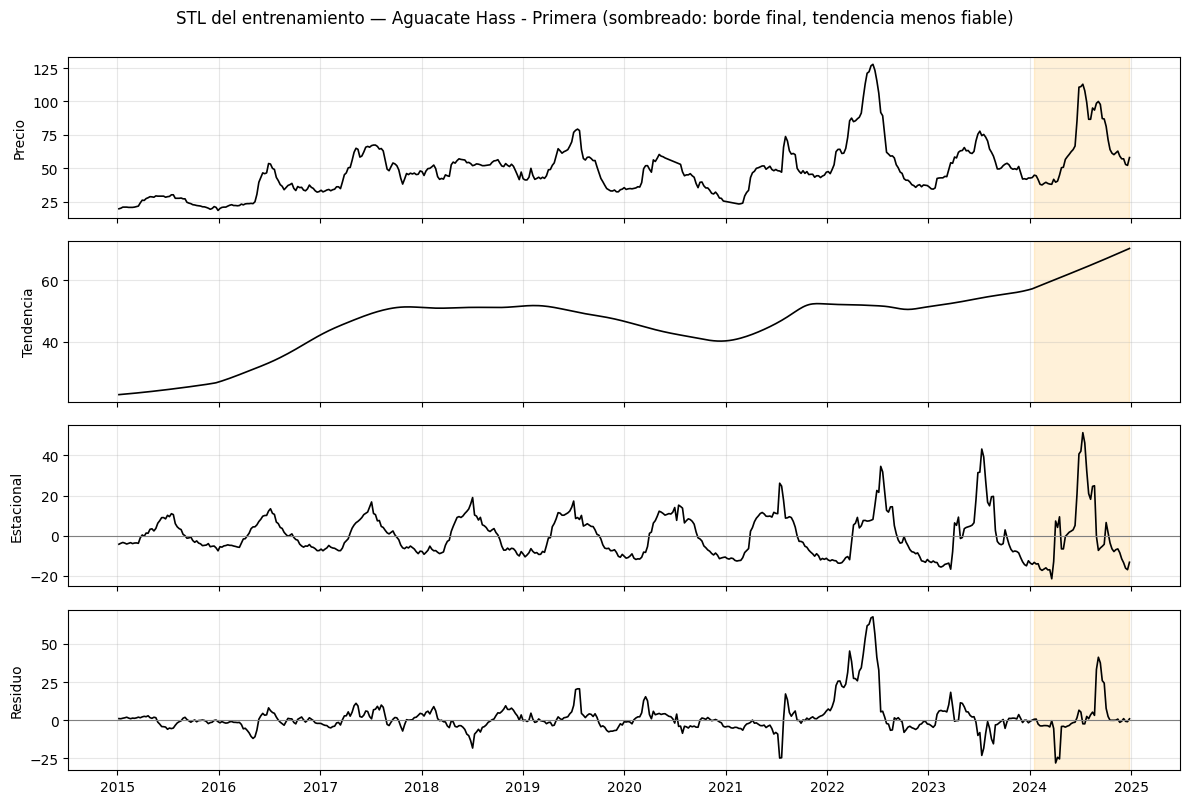

Aguacate Hass - Primera: tendencia d = 1 (p ADF [np.float64(0.9566), np.float64(0.2667)]) | residuo STL NO es ruido blanco (Ljung-Box p: 10=0.000, 52=0.000)


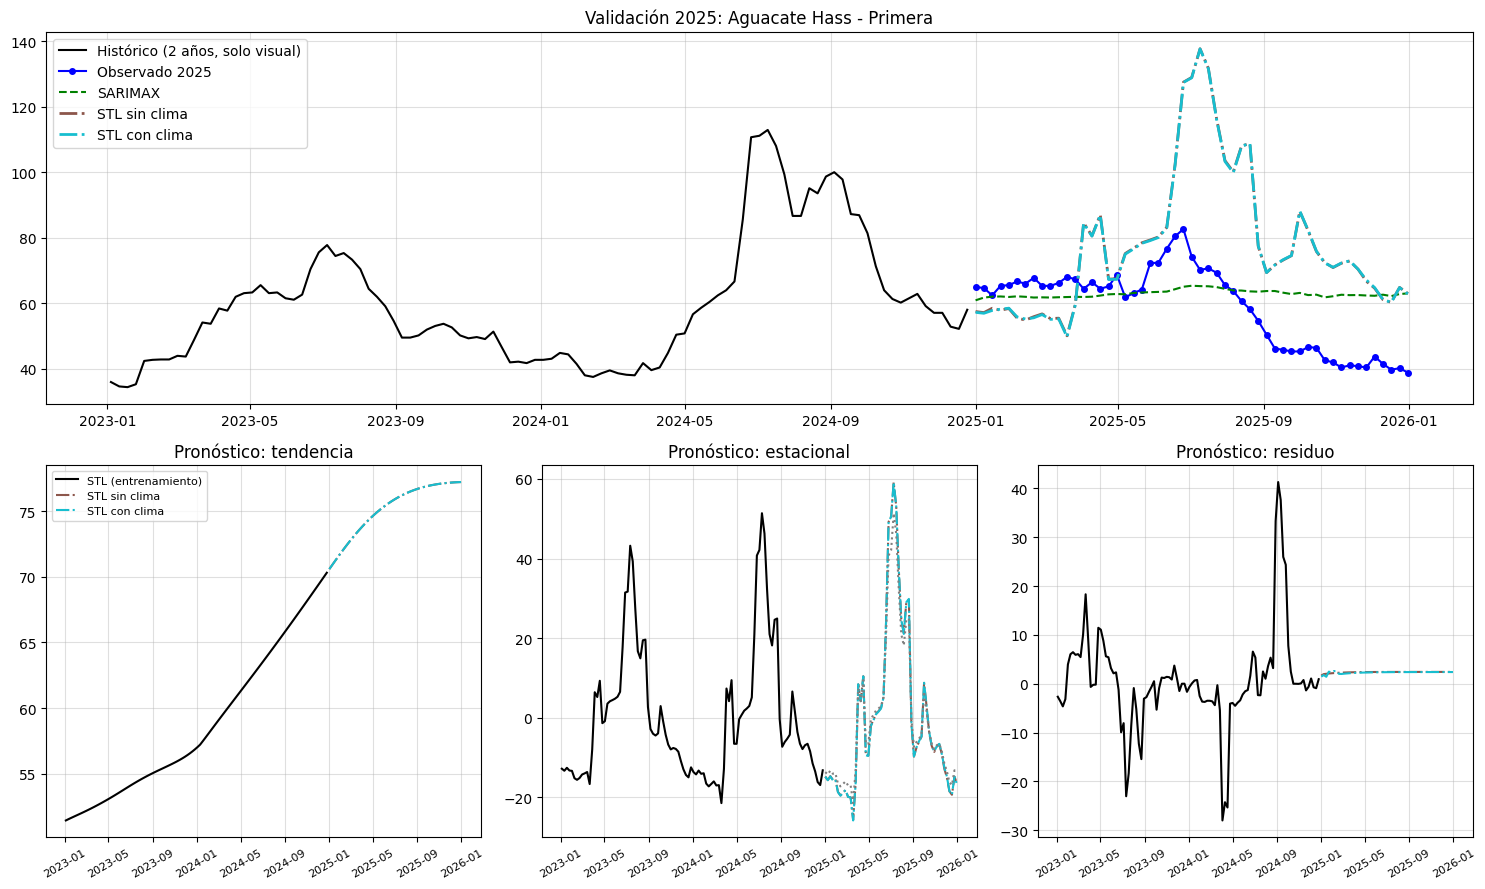

Modelo de cada componente:


,Componente,Modelo sin clima,AIC sin clima,Ljung-Box p (10),Ljung-Box p (52),Modelo con clima,AIC con clima,ΔAIC (sin − con),Clima significativo (p<0.05)
0,tendencia,"ARIMA(2,1,2)",-3357.04,0.364,1.0,"ARIMAX(2,1,2)",-3351.04,-6.00,—
1,estacional,"SARIMA(1,0,1)(1,0,1,52)",1213.50,0.000,0.0,"SARIMAX(1,0,1)(1,0,1,52)",1214.72,-1.22,—
2,residuo,"ARMA(1,2)",2437.76,0.547,0.0,"ARMAX(1,2)",2432.01,5.74,—


Año de prueba:


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),12.984,10.233,20.908
SARIMAX,12.637,9.980,20.379
SARIMAX con clima observado (referencia),12.995,10.246,20.940
Ingenuo (último valor),12.285,11.090,20.582
Ingenuo estacional (52 semanas antes),26.449,23.942,42.784
Koyck (niveles),16.438,13.664,21.487
Koyck (niveles) con clima observado (referencia),18.684,16.778,28.049
Koyck (Δ),12.038,10.286,20.637
Koyck (Δ) con clima observado (referencia),15.855,12.615,26.200
STL sin clima,27.966,23.275,42.468


TOMATE SALADETTE - PRIMERA — STL por componentes (con y sin clima)


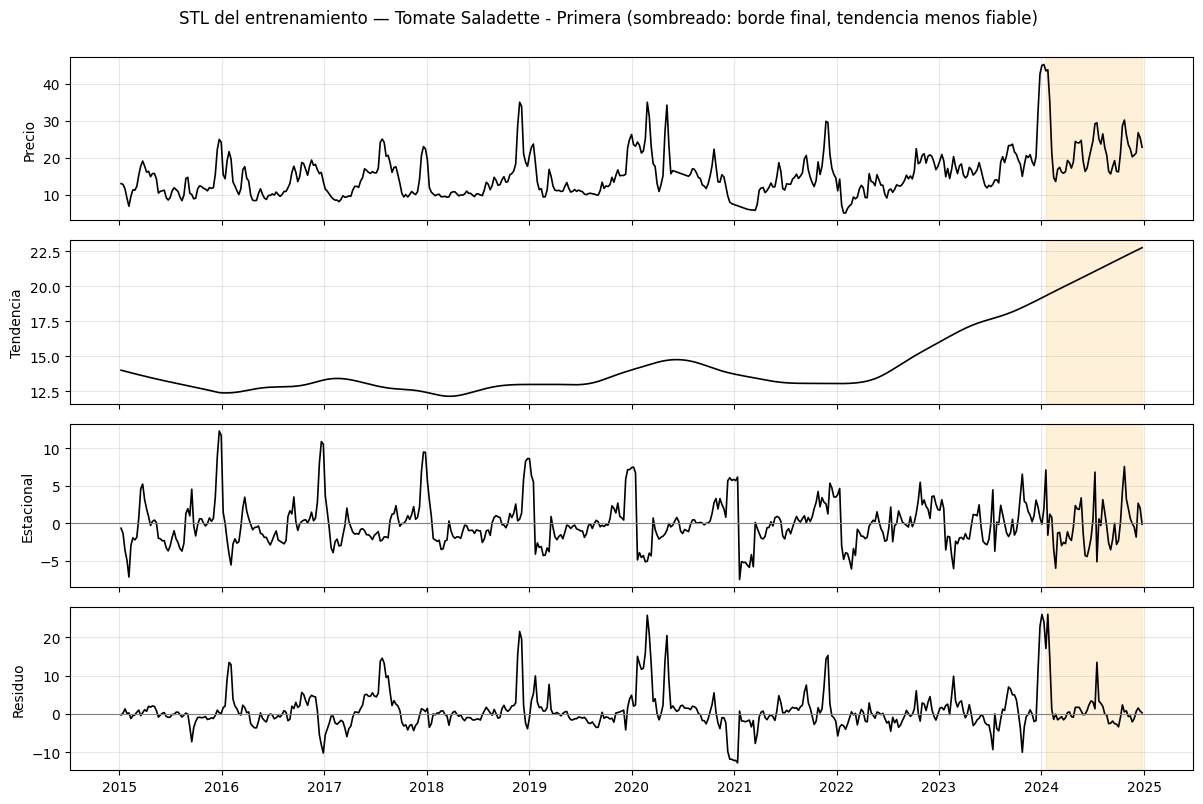

Tomate Saladette - Primera: tendencia d = 1 (p ADF [np.float64(0.975), np.float64(0.5597)]) | residuo STL NO es ruido blanco (Ljung-Box p: 10=0.000, 52=0.000)


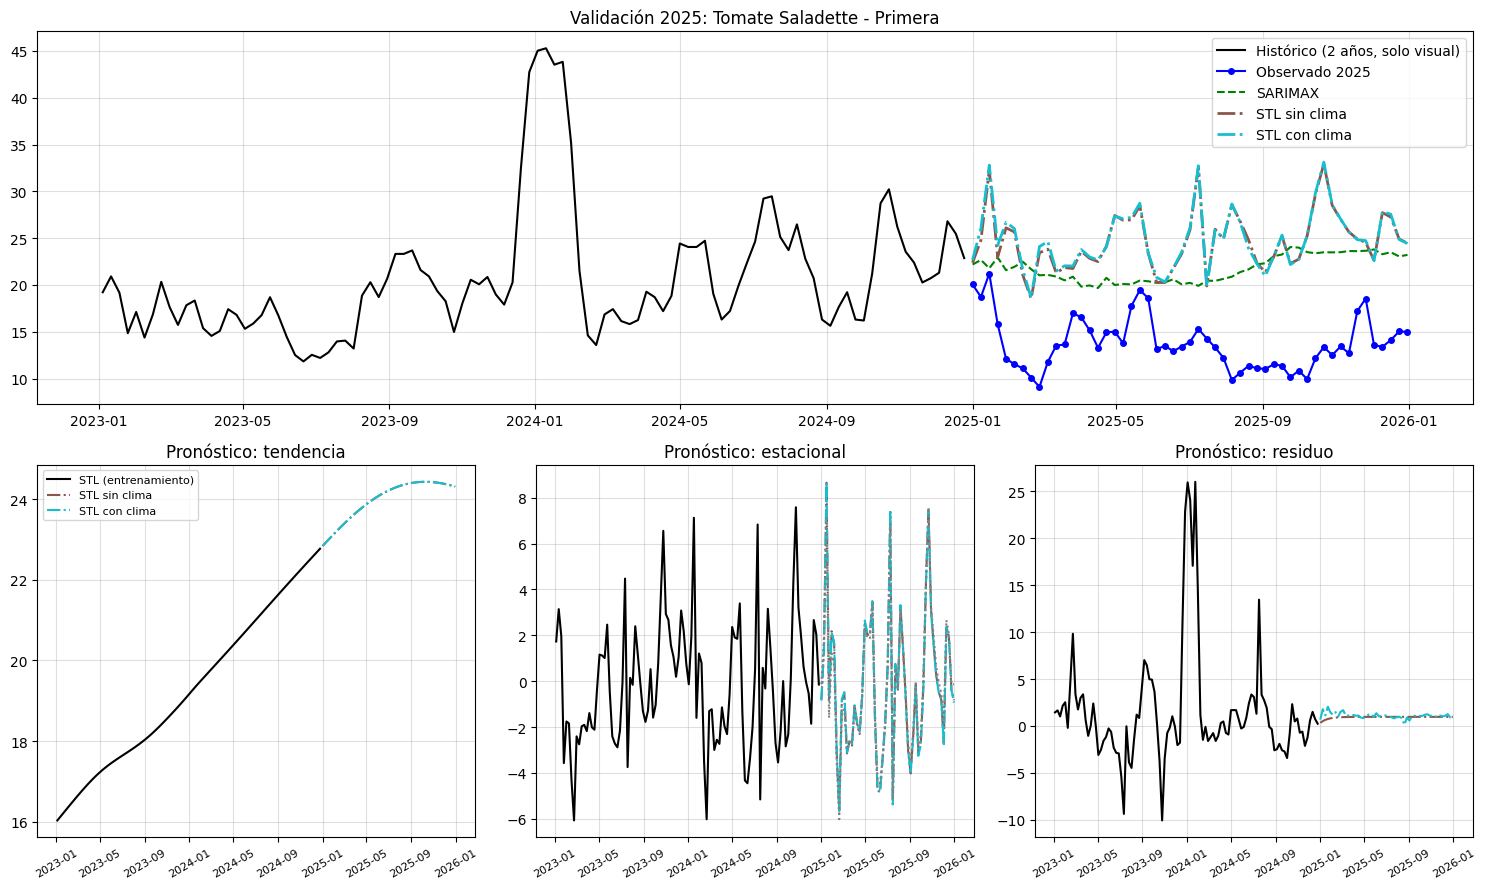

Modelo de cada componente:


,Componente,Modelo sin clima,AIC sin clima,Ljung-Box p (10),Ljung-Box p (52),Modelo con clima,AIC con clima,ΔAIC (sin − con),Clima significativo (p<0.05)
0,tendencia,"ARIMA(2,1,2)",-6076.93,0.355,1.000,"ARIMAX(2,1,2)",-6069.80,-7.13,—
1,estacional,"SARIMA(2,0,0)(1,0,1,52)",909.44,0.000,0.000,"SARIMAX(2,0,0)(1,0,1,52)",914.11,-4.67,—
2,residuo,"ARMA(1,2)",2121.18,0.121,0.001,"ARMAX(1,2)",2123.26,-2.08,—


Año de prueba:


,RMSE,MAE,MAPE (%)
SARIMA (sin clima),8.521,8.046,64.550
SARIMAX,8.643,7.974,64.391
SARIMAX con clima observado (referencia),8.643,7.974,64.391
Ingenuo (último valor),9.495,9.073,72.285
Ingenuo estacional (52 semanas antes),11.421,9.336,69.189
Koyck (niveles),3.906,3.338,26.136
Koyck (niveles) con clima observado (referencia),5.179,4.587,34.887
Koyck (Δ),9.439,9.013,71.834
Koyck (Δ) con clima observado (referencia),9.506,9.073,72.303
STL sin clima,11.538,10.915,85.305


,Producto,Con clima,d tendencia,Residuo ruido blanco,Modelo tendencia,Modelo estacional,Modelo residuo,Rezago clima k,Mejor modelo (RMSE),RMSE STL sin clima,RMSE STL sin clima (estacional = último ciclo),RMSE STL con clima,RMSE SARIMA (sin clima),RMSE SARIMAX,RMSE Ingenuo (último valor),MAPE STL sin clima (%),MAPE STL con clima (%)
0,Haba,True,1,False,"ARIMA(2,1,1)","SARIMA(1,0,0)(1,0,1,52)","ARMA(1,2)",72,STL sin clima (estacional = último ciclo),5.089,5.073,5.115,11.003,10.652,12.006,4.199,4.229
1,Maíz blanco,True,1,False,"ARIMA(2,1,2)","SARIMA(1,0,0)(1,0,1,52)","ARMA(1,1)",72,STL sin clima (estacional = último ciclo),0.945,0.885,0.913,1.121,1.090,1.121,8.149,7.834
2,Frijol Pinto,True,1,False,"ARIMA(2,1,1)","SARIMA(2,0,1)(1,0,1,52)","ARMA(1,0)",85,Koyck (Δ),6.265,6.225,6.229,1.505,1.838,1.517,21.127,20.924
3,Aguacate Hass - Primera,True,1,False,"ARIMA(2,1,2)","SARIMA(1,0,1)(1,0,1,52)","ARMA(1,2)",8,Koyck (Δ),27.966,26.236,27.950,12.984,12.637,12.285,42.468,42.488
4,Tomate Saladette - Primera,True,1,False,"ARIMA(2,1,2)","SARIMA(2,0,0)(1,0,1,52)","ARMA(1,2)",65,Koyck (niveles),11.538,11.523,11.679,8.521,8.643,9.495,85.305,86.434


In [60]:
resumen_stl = []
for producto in PRODUCTOS_MODELADO:
    print('=' * 70)
    print(f"{producto.upper()} — STL por componentes {'(con y sin clima)' if producto in PRODUCTOS_CON_CLIMA else '(sin clima)'}")
    print('=' * 70)
    comp, modelos, tabla, pron_comp, pron_total, detalle = stl_producto(producto)
    TABLAS_STL[producto] = tabla
    PRONOSTICOS_STL[producto] = {'componentes': pron_comp, 'total': pron_total}
    comp.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, f'stl_componentes_{slug(producto)}.csv'))
    modelos.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, f'stl_modelos_{slug(producto)}.csv'), index=False)
    tabla.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, f'metricas_stl_{ANIO_PRUEBA}_{slug(producto)}.csv'))
    pd.concat({n: df.assign(Total=df.sum(axis=1)) for n, df in pron_comp.items()}, axis=1).to_csv(
        os.path.join(CARPETA_RESULTADOS_MODELADO, f'stl_pronosticos_{ANIO_PRUEBA}_{slug(producto)}.csv'))
    print("Modelo de cada componente:")
    display(modelos)
    print("Año de prueba:")
    display(tabla)
    sin_ref = tabla[~tabla.index.str.contains('referencia')]
    mejor = sin_ref['RMSE'].idxmin() if len(sin_ref) and sin_ref['RMSE'].notna().any() else None
    fila = {'Producto': producto, 'Con clima': producto in PRODUCTOS_CON_CLIMA, 'd tendencia': detalle['d'],
            'Residuo ruido blanco': detalle['ruido_blanco'], 'Modelo tendencia': detalle['modelos']['tendencia'],
            'Modelo estacional': detalle['modelos']['estacional'], 'Modelo residuo': detalle['modelos']['residuo'],
            'Rezago clima k': detalle['k'], 'Mejor modelo (RMSE)': mejor}
    for nombre in ['STL sin clima', 'STL sin clima (estacional = último ciclo)', 'STL con clima', 'SARIMA (sin clima)', 'SARIMAX', 'Ingenuo (último valor)']:
        fila[f'RMSE {nombre}'] = tabla.loc[nombre, 'RMSE'] if nombre in tabla.index else None
    for nombre in ['STL sin clima', 'STL con clima']:
        fila[f'MAPE {nombre} (%)'] = tabla.loc[nombre, 'MAPE (%)'] if nombre in tabla.index else None
    resumen_stl.append(fila)

tabla_resumen_stl = pd.DataFrame(resumen_stl)
tabla_resumen_stl.to_csv(os.path.join(CARPETA_RESULTADOS_MODELADO, 'tabla_resumen_stl.csv'), index=False)
display(tabla_resumen_stl)

### 5.14 Siguientes pasos

- **Clima de Aguacate Hass y Tomate Saladette.** Si aún no los tienes: corre `Clima_Hortalizas_Aguacate_Tomate.ipynb` con `Municipios_Top50_5_Productos.csv` (sección 5.3) en su carpeta, copia a esta carpeta los dos archivos que genera (`Clima_Hortalizas_Top50_Semanal_v2.csv` y `Asignacion_Hortalizas_k5_v2.csv`) y vuelve a correr desde la sección 5.5: CCF, rezago óptimo, ARIMAX y SARIMAX se calculan solos para los productos cuyo clima cumpla `MIN_SEMANAS_PRUEBA_CON_CLIMA`. La sección 5.5 imprime, para cada producto, si quedó con o sin clima y por qué.
- **Koyck.** Lee los `λ` y los rezagos medios de `resultados_modelado/koyck_parametros_*.csv` junto con el rezago óptimo del SARIMAX (5.8) y con la CCF (5.7): si coinciden en el orden de magnitud del retardo, la evidencia es consistente. Si `λ̂` queda en el borde de la rejilla o el Ljung-Box rechaza ruido blanco, el Koyck está capturando persistencia del precio y no memoria del clima; en ese caso conviene presentarlo como referencia y no como modelo final.
- **STL.** Mira primero en la 5.13 si el residuo de cada producto resultó ruido blanco y qué modelo recibió cada componente, y si el SARIMA del componente estacional le gana a «estacional = último ciclo». Si la versión con clima no mejora el ΔAIC de ningún componente, el clima está aportando poco una vez separada la estacionalidad. Para probar el clima solo en el residuo, deja `COMPONENTES_CON_CLIMA = ['residuo']`.
- **Revisar `MAPEO_CULTIVO_SIAP`** para Aguacate Hass y Tomate Saladette contra los valores reales de `Cultivo` en tus CSV del SIAP (`'Aguacate'` y `'Tomate rojo (jitomate)'` son el nombre más común, pero puede variar por año).